# ECW-NMF — an evidence-coverage-weighted objective for WNMFDDA (Kaggle notebook)

**Proposed modification.** WNMFDDA's reconstruction loss treats every unobserved pair as a confirmed zero, with full weight, including pairs that involve a drug or disease with almost no recorded associations. ECW-NMF keeps the whole WNMFDDA pipeline (graphs, Laplacian penalties, non-negativity, multiplicative updates) and changes **one thing in the data-fit term**: a zero is trusted only to the extent that *both* its drug and its disease have been annotated.

The notebook uses the same **E / P / Q / V / L** framework as the earlier notebooks, now for a *constructive* claim: the new objective beats the baseline under a pre-registered protocol.

| Part | Meaning |
|---|---|
| **E** | Equations (baseline objective, modified objective, update rules, one analytical result) |
| **P** | Proposition (falsifiable improvement claim) |
| **Q** | Quantities and decision rule, fixed *before* running |
| **V** | Verification (code: correctness audit, then fair comparison on Fdataset and Cdataset) |
| **L** | Link to predictive consequences and what each outcome would mean |

### Why this modification (evidence from the two reports)
* "Unknown is not negative" (both reports): unobserved pairs include undiscovered positives. The risk is highest for entities with few recorded associations, and total for entities with none (cold start).
* Cold start was never evaluated and the interim report flags it as pending; WKNN's cold-start value was small. The loss itself gives an unobserved entity a *wrong* target: an all-zero row or column.
* Graph regularisation helps (RH10: real graph beats rewired graphs) but only at moderate strength; λ = 10 hurts. Stronger smoothing is therefore not the lever; **what the data-fit term asks the model to believe** is.
* WKNN is largely redundant with the graph term (R1), so the modification does not rely on it.

### E — Equations
Baseline (paper), target $M$ ($=Y'$ with WKNN), $L_R=D_R-S^{R*}$, $L_D=D_D-S^{D*}$:

$$\mathcal J_{\rm WNMFDDA}(A,B)=\|M-A^\top B\|_F^2+\lambda\big[\operatorname{Tr}(AL_RA^\top)+\operatorname{Tr}(BL_DB^\top)\big]+\beta(\|A\|_F^2+\|B\|_F^2).$$

**ECW-NMF.** Let $n_i$ be the number of *training* associations of drug $i$ and $n_j$ that of disease $j$. Define coverage

$$\omega_R(i)=\frac{n_i}{n_i+\kappa},\qquad \omega_D(j)=\frac{n_j}{n_j+\kappa},\qquad W_{ij}=\begin{cases}1 & Y_{ij}=1\\ \omega_R(i)\,\omega_D(j) & Y_{ij}=0\end{cases}$$

$$\mathcal J_{\rm ECW}(A,B)=\|\sqrt{W}\odot(Y-A^\top B)\|_F^2+\lambda\big[\operatorname{Tr}(AL_RA^\top)+\operatorname{Tr}(BL_DB^\top)\big]+\beta(\|A\|_F^2+\|B\|_F^2),\quad A,B\ge 0 .$$

$\kappa=0$ is defined as $W\equiv 1$, so **WNMFDDA's loss is the special case $\kappa=0$** (with target $Y$; WKNN is an ablation). *Interpretation:* if each entity's annotation is complete with probability $\omega$, a zero for pair $(i,j)$ is informative with probability $\omega_R(i)\omega_D(j)$, so $W$ is the expected informativeness of that zero. Known positives always keep weight 1. Counts come from the **training matrix only**.

**Updates** (non-negative weights, so the multiplicative scheme still applies):

$$A\leftarrow A\odot\frac{B(W\odot M)^\top+\lambda AS^{R*}}{B(W\odot A^\top B)^\top+\lambda AD_R+\beta A},\qquad B\leftarrow B\odot\frac{A(W\odot M)+\lambda BS^{D*}}{A(W\odot A^\top B)+\lambda BD_D+\beta B}.$$

**Analytical result (verified numerically in the audit).** For a drug with no training associations ($n_i=0$, $\kappa>0$) all its unknown-pair weights are 0, so at a stationary point of the update every non-zero latent coordinate satisfies
$$a_{if}=\frac{\lambda\,(AS^{R*})_{fi}}{\lambda d_i+\beta},$$
i.e. a new entity's factor is exactly the shrunken, graph-weighted mean of its neighbours' factors. In the baseline the same entity satisfies $(\lambda d_i+\beta)a_{if}=\lambda(AS^{R*})_{fi}-(BB^\top a_i)_f$, hence $a^{\rm base}_{if}\le\lambda(AS^{R*})_{fi}/(\lambda d_i+\beta)$: the baseline's own zero-target subtracts a data-fit term and pushes the new entity's scores down, whereas ECW-NMF removes that pull. (The same holds for a new disease with $B$ and $S^{D*}$.)

### P — Proposition
* **P1 (primary).** With dev-tuned hyper-parameters, ECW-NMF has higher pooled ROC-AUC than the best dev-tuned WNMFDDA (same grid budget, nested) by more than $\delta=0.01$, in **warm start, new-drug and new-disease evaluation, on both datasets** (6 cells).
* **P2 (mechanism).** The gain comes from *which* entities are down-weighted: ECW-NMF beats (a) a tuned **uniform** zero down-weight (same grid size) and (b) ECW-NMF with **coverage values permuted across entities**.
* **P3 (honest trade-off, reported, not gating).** Effect on AUPR and per-entity recall@10, warm and cold.
* **P4 (comparison with the published configuration).** Same contrast against the paper's fixed parameters (WKNN on, $\lambda=1$, $\beta=0.02$, $k=160$).

### Q — Quantities and decision rule (fixed before running)
$\delta=0.01$ ROC-AUC (pooled, all unobserved pairs of the evaluated entities as negatives); unit = seed mean over folds; paired t intervals at 95 %; one-sided tests H0: improvement $\le\delta$ (small p ⇒ improvement shown to exceed $\delta$); Holm correction over the 6 primary tests.

| Label per cell | Rule |
|---|---|
| **STRONG** | lower 95 % bound of (ECW − comparator) $>\delta$ |
| **POSITIVE** | lower bound $>0$ but not above $\delta$ |
| **INCONCLUSIVE** | interval contains 0 |
| **WORSE** | upper bound $<0$ |

**Aggregate for P1:** *SUPPORTED* if all 6 cells are STRONG; *PARTIAL (k/6)* if k cells are STRONG; *POSITIVE ONLY* if none are STRONG but every cell is at least POSITIVE; otherwise *NOT SUPPORTED*. P2 is supported in a cell if both control contrasts have lower bound $>0$. Protocol: same folds, candidate pairs and iteration cap for every model; hyper-parameters chosen on an inner dev split of the training matrix only; comparator grids are *nested* inside the ECW grid (the ECW grid contains the baseline grid), so tuned ECW cannot do worse on dev than tuned baseline.

### V — Verification
Warm start: random held-out positive pairs. New drugs / new diseases: whole entities removed from training (all their associations), with held-out entities' zero rows/columns scored. Negatives are all unobserved pairs of the evaluated entities (not verified negatives). Correctness audit and a convergence audit precede the experiment; a leaky pipeline is included as a positive control. Results cache to CSV and resume.

### L — Link to predictive consequences
| Outcome | Reading |
|---|---|
| P1 supported, P2 supported | The loss, not the graph or WKNN, was leaving accuracy on the table; coverage-aware zeros are a better data-fit term, especially for new entities. |
| P1 supported only in cold start | The change is a cold-start fix; warm-start gain is within margin. |
| P1 supported but P2 fails | The gain is generic zero down-weighting or extra tuning freedom, not entity coverage. Report it as such. |
| P1 not supported | The modification does not beat a fairly tuned baseline; report the negative result. |

**Scope and caveats.** Two datasets; pooled AUC is the primary metric and is known to reward calibration across entities, so AUPR and recall@10 are reported next to it (the pilot suggested a *warm-start AUPR cost*, see P3). Seed intervals reflect split and initialisation randomness only. The paper's parameters were tuned by its authors on these same datasets, which favours the published configuration. Pilot runs used held-out seeds 100–102; this notebook uses seeds from `SEED0` (default 0).

**GPU.** On Kaggle choose *Accelerator: GPU T4*. The fits then run in float32 on CUDA (same initialisation and updates; the stop rule is checked every 5 iterations). The correctness audits always use float64 CPU. Set `USE_GPU=0` in the environment to force CPU.

**How to run on Kaggle.** Attach the dataset with `DataF.mat` and `DataC.mat` (default `/kaggle/input/datasets/cliffbooth/drug-disease-association`; recursive search fallback). Set `PROFILE`: `smoke` (minutes), `quick` (default, 3 seeds × 3 folds), `full` (10 × 5, many hours).

In [2]:
import os, sys, time, glob, warnings
from types import SimpleNamespace as NS
import numpy as np, pandas as pd, scipy.io as sio
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from IPython.display import display
except Exception:
    display = print
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 140)

# ------------------------------ CONFIG ------------------------------
PROFILE = os.environ.get("WNMFDDA_PROFILE", "quick")             # 'smoke' | 'quick' | 'full'
PROFILES = {
    "smoke": dict(N_SEEDS=2, N_FOLDS=2, MAX_ITER=30,  DEV_ITER=20),
    "quick": dict(N_SEEDS=3, N_FOLDS=3, MAX_ITER=300, DEV_ITER=150),
    "full":  dict(N_SEEDS=10, N_FOLDS=5, MAX_ITER=500, DEV_ITER=200),
}
globals().update(PROFILES[PROFILE])
SEED0 = int(os.environ.get("SEED0", "0")); SEEDS = list(range(SEED0, SEED0 + N_SEEDS))

PAPER = dict(p=5, K=5, a=0.5, k=160, lam=1.0, beta=0.02)         # published configuration
DATA_DIR = os.environ.get("DATA_DIR", "/kaggle/input/datasets/cliffbooth/drug-disease-association")
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
RES_PATH = os.path.join(OUT_DIR, f"ecw_results_{PROFILE}_s{SEED0}.csv")
FORCE_RERUN = False
DELTA = 0.01; ALPHA = 0.05

# GPU (Kaggle T4): the multiplicative updates run in float32 on CUDA when available; USE_GPU=0 forces the float64 CPU path
try:
    import torch
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch, DEVICE = None, None
USE_GPU = (torch is not None) and (DEVICE.type == "cuda") and os.environ.get("USE_GPU", "1") == "1"
print("compute device:", torch.cuda.get_device_name(0) if USE_GPU else "CPU (float64 numpy)")

# hyper-parameter grids (identical (lam, beta) axes for every tuned model => nested, equal-axis budget)
LAMS = [0.5, 1.0, 2.0]; BETAS = [0.02, 0.1]
KAPS = [0.3, 1.0]            # ECW coverage constants (0 = baseline weights)
ALPHAS = [0.5, 0.2]          # uniform zero-weight control (1 = baseline weights)

RES = pd.read_csv(RES_PATH) if (os.path.exists(RES_PATH) and not FORCE_RERUN) else pd.DataFrame()
PRIMARY, SECOND = {}, {}
print(f"PROFILE={PROFILE} seeds={SEEDS} folds={N_FOLDS} max_iter={MAX_ITER} dev_iter={DEV_ITER}")
print(f"data dir: {DATA_DIR}\ncached rows: {len(RES)} -> {RES_PATH}")

compute device: Tesla T4
PROFILE=quick seeds=[0, 1, 2] folds=3 max_iter=300 dev_iter=150
data dir: /kaggle/input/datasets/cliffbooth/drug-disease-association
cached rows: 0 -> /kaggle/working/ecw_results_quick_s0.csv


In [3]:
# ============================== CORE LIBRARY ==============================
EPS = 1e-12

def neighbor_order(S):
    S2 = np.array(S, dtype=float); np.fill_diagonal(S2, -np.inf)
    return np.argsort(-S2, axis=1, kind="stable")[:, :-1]

def build_graph(S, p):
    # published rule: W=1 mutual p-NN, 0 neither, 0.5 otherwise; S* = S (.) W
    n = S.shape[0]; order = neighbor_order(S)
    N = np.zeros((n, n), bool); N[np.arange(n)[:, None], order[:, :p]] = True
    W = np.where(N & N.T, 1.0, np.where(~(N | N.T), 0.0, 0.5)); np.fill_diagonal(W, 0.0)
    Sg = S * W; np.fill_diagonal(Sg, 0.0); return Sg

def wknn_side(S, P, K, a, order):
    # eligible neighbours only (>=1 training association); numerator decay a^(t-1) s, denominator unweighted sum of selected s
    n = S.shape[0]; rows = np.arange(n)[:, None]
    valid = (P.sum(axis=1) > 0)[order]; cum = np.cumsum(valid, axis=1); sel = valid & (cum <= K)
    sims = np.maximum(S[rows, order], 0.0)
    w = np.where(sel, np.power(a, np.maximum(cum - 1, 0)) * sims, 0.0); den = np.where(sel, sims, 0.0).sum(axis=1)
    Wf = np.zeros((n, n)); Wf[rows, order] = w; out = Wf @ P; ok = den > EPS
    out[ok] /= den[ok, None]; out[~ok] = 0.0; return out

def wknn_reconstruct(Y, D):
    Yr = wknn_side(D.SR, Y, PAPER["K"], PAPER["a"], D.ordR); Yd = wknn_side(D.SD, Y.T, PAPER["K"], PAPER["a"], D.ordD).T
    return np.maximum(Y, (Yr + Yd) / 2)

# ---------- coverage weights ----------
def coverage_weights(Ytr, kappa, kind="real", rng=None, alpha=None):
    """W_ij = 1 on observed positives; on unknown pairs: omega_R(i)*omega_D(j) (kind='real'), the same with coverage values
    permuted across entities (kind='perm'), or a constant alpha (kind='uniform').  kappa=0 / alpha=1 give W = 1 (baseline)."""
    if kind == "uniform":
        return np.ones_like(Ytr) if (alpha is None or alpha >= 1) else np.where(Ytr > 0, 1.0, alpha)
    if kappa <= 0: return np.ones_like(Ytr)
    nR, nD = Ytr.sum(1), Ytr.sum(0); oR, oD = nR / (nR + kappa), nD / (nD + kappa)
    if kind == "perm": oR, oD = rng.permutation(oR), rng.permutation(oD)
    return np.where(Ytr > 0, 1.0, np.outer(oR, oD))

# ---------- weighted graph-regularised NMF (paper updates when W = 1) ----------
def _wnmf_fit_gpu(M, Wt, SgR, SgD, k, lam, beta, max_iter, seed, tol):
    rng = np.random.default_rng(seed); n, m = M.shape
    c = 2 * np.sqrt(max(M.mean(), 1e-8) / k)
    A0 = rng.random((k, n)) * c + 1e-6; B0 = rng.random((k, m)) * c + 1e-6          # same initialisation as the CPU path
    f = lambda x: torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32, device=DEVICE)
    A, B, Mt, Wg, SR, SD = f(A0), f(B0), f(M), f(Wt), f(SgR), f(SgD); e = 1e-10
    dR, dD = SR.sum(1)[None, :], SD.sum(1)[None, :]; WM = Wg * Mt; it = 0
    with torch.no_grad():
        for it in range(1, max_iter + 1):
            An = A * (B @ WM.T + lam * (A @ SR)) / (B @ (Wg * (A.T @ B)).T + lam * A * dR + beta * A + e)
            Bn = B * (An @ WM + lam * (B @ SD)) / (An @ (Wg * (An.T @ B)) + lam * B * dD + beta * B + e)
            stop = False
            if it % 5 == 0 or it == max_iter:
                stop = max(((An - A) ** 2).sum(0).max().item(), ((Bn - B) ** 2).sum(0).max().item()) < tol
            A, B = An, Bn
            if stop: break
    return A.cpu().numpy().astype(np.float64), B.cpu().numpy().astype(np.float64), it

def wnmf_fit(M, Wt, SgR, SgD, k, lam, beta, max_iter, seed, tol=1e-4, trace=False, gpu=None):
    if (USE_GPU if gpu is None else gpu) and not trace and tol > 0:
        return _wnmf_fit_gpu(M, Wt, SgR, SgD, k, lam, beta, max_iter, seed, tol)
    rng = np.random.default_rng(seed); n, m = M.shape
    c = 2 * np.sqrt(max(M.mean(), 1e-8) / k)
    A = rng.random((k, n)) * c + 1e-6; B = rng.random((k, m)) * c + 1e-6
    dR, dD = SgR.sum(1)[None, :], SgD.sum(1)[None, :]; WM = Wt * M; obj = []
    def J(A, B):
        X = A.T @ B
        return float((Wt * (M - X) ** 2).sum() + lam * (np.sum((A @ (np.diag(SgR.sum(1)) - SgR)) * A) + np.sum((B @ (np.diag(SgD.sum(1)) - SgD)) * B)) + beta * ((A ** 2).sum() + (B ** 2).sum()))
    if trace: obj.append(J(A, B))
    for it in range(1, max_iter + 1):
        X = A.T @ B
        An = A * (B @ WM.T + lam * (A @ SgR)) / (B @ (Wt * X).T + lam * A * dR + beta * A + EPS)
        X = An.T @ B
        Bn = B * (An @ WM + lam * (B @ SgD)) / (An @ (Wt * X) + lam * B * dD + beta * B + EPS)
        err = max(((An - A) ** 2).sum(0).max(), ((Bn - B) ** 2).sum(0).max()); A, B = An, Bn
        if trace: obj.append(J(A, B))
        if err < tol: break
    return (A, B, it, obj) if trace else (A, B, it)

# ---------- metrics ----------
def auc_vs(ps, nss):
    lo = np.searchsorted(nss, ps, "left"); hi = np.searchsorted(nss, ps, "right")
    return float(np.mean((lo + 0.5 * (hi - lo)) / len(nss))) if len(ps) else np.nan

def metrics(Sc, pos, neg, with_aupr=True):
    s = Sc.ravel(); ps, ns = s[pos], s[neg]; out = {"auc": auc_vs(ps, np.sort(ns))}
    if with_aupr: out["aupr"] = float(average_precision_score(np.r_[np.ones(len(ps)), np.zeros(len(ns))], np.r_[ps, ns]))
    return out

def rec_at(Sc, Ytr, pos, shape, axis, k=10):
    # recall@k per entity list: rank of each held-out positive among the candidates of its own drug (axis 0) or its own disease (axis 1)
    n, m = shape; i, j = pos // m, pos % m
    if axis == 1: Sc, Ytr, i, j = Sc.T, Ytr.T, j, i
    ps = Sc[i, j]; Sm = Sc[i].copy(); Sm[Ytr[i] > 0] = -np.inf
    rank = (Sm > ps[:, None]).sum(1) + ((Sm == ps[:, None]).sum(1) - 1) / 2.0
    return float((rank < k).mean())

# ---------- splits (leakage-safe: held-out labels removed from the training matrix before any label-based step) ----------
def pair_split(D, seed, fold):
    pos = np.argwhere(D.Y > 0)
    test = pos[np.array_split(np.random.default_rng(seed).permutation(len(pos)), N_FOLDS)[fold]]
    Ytr = D.Y.copy(); Ytr[test[:, 0], test[:, 1]] = 0.0
    return NS(Ytr=Ytr, pos=test[:, 0] * D.m + test[:, 1], neg=D.neg_flat, axis=0)

def entity_split(D, axis, seed, fold):
    N = D.n if axis == 0 else D.m
    held = np.sort(np.array_split(np.random.default_rng([seed, 4242, axis]).permutation(N), N_FOLDS)[fold])
    mask = np.zeros(D.Y.shape, bool)
    if axis == 0: mask[held, :] = True
    else: mask[:, held] = True
    return NS(Ytr=np.where(mask, 0.0, D.Y), held=held, mask=mask, axis=axis,
              pos=np.flatnonzero((mask & (D.Y > 0)).ravel()), neg=np.flatnonzero((mask & (D.Y == 0)).ravel()))

def dev_split(Ytr, rng, mode, frac=0.2):
    n, m = Ytr.shape
    if mode == "pair":
        pos = np.argwhere(Ytr > 0); held = pos[rng.permutation(len(pos))[:max(1, int(round(frac * len(pos))))]]
        Yin = Ytr.copy(); Yin[held[:, 0], held[:, 1]] = 0.0
        return Yin, held[:, 0] * m + held[:, 1], np.flatnonzero(Ytr.ravel() == 0)
    ax = 0 if mode == "drug" else 1
    ent = np.flatnonzero((Ytr.sum(1) if ax == 0 else Ytr.sum(0)) > 0)
    h = rng.choice(ent, size=max(1, int(round(frac * len(ent)))), replace=False)
    mask = np.zeros(Ytr.shape, bool)
    if ax == 0: mask[h, :] = True
    else: mask[:, h] = True
    return np.where(mask, 0.0, Ytr), np.flatnonzero((mask & (Ytr > 0)).ravel()), np.flatnonzero((mask & (Ytr == 0)).ravel())

# ---------- dev tuning (inner split of the TRAINING matrix only) ----------
def fit_scores(Ytr, D, kind, kappa, alpha, lam, beta, seed, iters, perm_seed=0):
    rng = np.random.default_rng([perm_seed, 777])
    Wt = coverage_weights(Ytr, kappa, kind=kind, rng=rng, alpha=alpha)
    A, B, it = wnmf_fit(Ytr, Wt, D.SgR, D.SgD, PAPER["k"], lam, beta, iters, seed)
    return A.T @ B, it

def tune(Ytr, D, key, mode, family, seed):
    """family: 'base' | 'ecw' | 'uniform' | 'perm'.  Returns best config and the dev table.  'base' grid is the kappa=0 / alpha=1 slice shared by all."""
    Yin, pos, neg = dev_split(Ytr, np.random.default_rng(list(key)), mode); rows = []
    shapes = {"base": [(0.0, 1.0)], "ecw": [(0.0, 1.0)] + [(k, 1.0) for k in KAPS], "perm": [(0.0, 1.0)] + [(k, 1.0) for k in KAPS],
              "uniform": [(0.0, 1.0)] + [(0.0, a) for a in ALPHAS]}[family]
    kind = {"base": "real", "ecw": "real", "perm": "perm", "uniform": "uniform"}[family]
    for (kap, alp) in shapes:
        for lam in LAMS:
            for beta in BETAS:
                Sc, _ = fit_scores(Yin, D, kind, kap, alp, lam, beta, seed, DEV_ITER, perm_seed=seed)
                rows.append(dict(kappa=kap, alpha=alp, lam=lam, beta=beta, dev_auc=metrics(Sc, pos, neg, False)["auc"]))
    T = pd.DataFrame(rows); b = T.loc[T.dev_auc.idxmax()]
    return dict(kappa=float(b.kappa), alpha=float(b.alpha), lam=float(b.lam), beta=float(b.beta)), float(b.dev_auc)

# ---------- statistics ----------
def pstats(d, alpha=ALPHA):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    o = dict(n=n, mean=np.nan, sd=np.nan, ci_lo=np.nan, ci_hi=np.nan, min=np.nan, max=np.nan)
    if n == 0: return o
    o.update(mean=d.mean(), min=d.min(), max=d.max())
    if n >= 2:
        sd = d.std(ddof=1); se = sd / np.sqrt(n); tc = stats.t.ppf(1 - alpha / 2, n - 1)
        o.update(sd=sd, ci_lo=o["mean"] - tc * se, ci_hi=o["mean"] + tc * se)
    return o

def crow(label, d):
    s = pstats(d); return dict(contrast=label, n_seeds=s["n"], mean=s["mean"], ci95_lo=s["ci_lo"], ci95_hi=s["ci_hi"], worst=s["min"], best=s["max"])

def one_sided_p(d, thr, alt):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n < 2: return np.nan
    se = d.std(ddof=1) / np.sqrt(n)
    if se == 0: return 0.0 if ((d.mean() > thr) if alt == "gt" else (d.mean() < thr)) else 1.0
    t = (d.mean() - thr) / se; return float(stats.t.sf(t, n - 1) if alt == "gt" else stats.t.cdf(t, n - 1))

def holm(p):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def label_gain(d):
    s = pstats(d)
    if not np.isfinite(s["ci_lo"]): return "INCONCLUSIVE", s
    if s["ci_lo"] > DELTA: return "STRONG", s
    if s["ci_lo"] > 0: return "POSITIVE", s
    if s["ci_hi"] < 0: return "WORSE", s
    return "INCONCLUSIVE", s

def run_units(unit_fn, tasks, label, flush_s=60):
    global RES
    done = set(RES["unit"]) if len(RES) else set(); buf, t0, tl, k = [], time.time(), time.time(), 0
    for key, kw in tasks:
        if key in done: continue
        rows = unit_fn(**kw)
        for r in rows: r["unit"] = key
        buf += rows; k += 1
        if time.time() - tl > flush_s:
            RES = pd.concat([RES, pd.DataFrame(buf)], ignore_index=True); RES.to_csv(RES_PATH, index=False); buf, tl = [], time.time()
            print(f"  [{label}] {k} units done ({time.time()-t0:.0f}s)")
    if buf: RES = pd.concat([RES, pd.DataFrame(buf)], ignore_index=True); RES.to_csv(RES_PATH, index=False)
    print(f"  [{label}] finished: {k} new units in {time.time()-t0:.0f}s (rows cached: {len(RES)})")

def seed_pivot(df, col, val="auc"): return df.groupby(["seed", col])[val].mean().unstack(col)
print("core library ready")

core library ready


In [5]:
# ============================== DATA ==============================
def find_mat(name):
    for root in [DATA_DIR, "/kaggle/input", ".", "/mnt/user-data/uploads"]:
        if root and os.path.isdir(root):
            hits = sorted(glob.glob(os.path.join(root, "**", name), recursive=True))
            if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found. Attach it as a Kaggle Dataset or set DATA_DIR.")

def load_dataset(tag):
    path = find_mat(f"Data{tag}.mat"); M = sio.loadmat(path)
    miss = [k for k in ("Y", "SR", "SD") if k not in M]
    if miss: raise KeyError(f"{path} lacks {miss}; keys: {[k for k in M if not k.startswith('__')]}")
    Y, SR, SD = (np.asarray(M[k], float) for k in ("Y", "SR", "SD")); n, m = SR.shape[0], SD.shape[0]
    if Y.shape == (m, n): Y = Y.T
    assert Y.shape == (n, m), f"unexpected shapes {Y.shape}, {SR.shape}, {SD.shape}"
    SR, SD = np.clip((SR + SR.T) / 2, 0, None), np.clip((SD + SD.T) / 2, 0, None); Y = (Y > 0).astype(float)
    D = NS(tag=tag, name=f"{tag}dataset", Y=Y, SR=SR, SD=SD, n=n, m=m)
    D.ordR, D.ordD = neighbor_order(SR), neighbor_order(SD); D.SgR, D.SgD = build_graph(SR, PAPER["p"]), build_graph(SD, PAPER["p"])
    D.neg_flat = np.flatnonzero(Y.ravel() == 0)
    print(f"[{D.name}] {os.path.basename(path)}: Y {Y.shape}, positives={int(Y.sum())}, density={Y.mean():.4f}")
    return D

LOADED = {t: load_dataset(t) for t in ("F", "C")}

[Fdataset] DataF.mat: Y (593, 313), positives=1933, density=0.0104
[Cdataset] DataC.mat: Y (663, 409), positives=2532, density=0.0093


---
# Correctness audit (prerequisite)
Checks the weighted update rule (monotone decrease, reduction to the paper's updates at $W\equiv1$), the **analytical result** on new-entity factors, split cleanliness, a leaky positive control, and convergence.

In [6]:
# 1. weighted updates: objective non-increasing on a small problem; W = 1 reproduces the paper's update exactly
rng = np.random.default_rng(0); n, m, k = 30, 22, 6
def rg(d):
    S = rng.random((d, d)); S = np.where(S > 0.7, S, 0); S = (S + S.T) / 2; np.fill_diagonal(S, 0); return S
SgR_, SgD_ = rg(n), rg(m)
Ys = (rng.random((n, m)) < 0.12).astype(float); Ys[0, :] = 0                      # drug 0 has no associations
Wt_ = coverage_weights(Ys, 0.5)
A_, B_, it_, obj = wnmf_fit(Ys, Wt_, SgR_, SgD_, k, 1.0, 0.05, 400, 1, tol=0, trace=True)
inc = np.max(np.diff(obj)); assert inc < 1e-8, f"objective increased by {inc}"
print(f"weighted objective non-increasing over 400 iterations (largest single-step change {inc:+.2e}); start {obj[0]:.3f} -> end {obj[-1]:.3f}")
A1, B1, _ = wnmf_fit(Ys, np.ones_like(Ys), SgR_, SgD_, k, 1.0, 0.05, 25, 3, tol=0)         # reference: paper's update written independently
rr = np.random.default_rng(3); c = 2 * np.sqrt(max(Ys.mean(), 1e-8) / k); A2 = rr.random((k, n)) * c + 1e-6; B2 = rr.random((k, m)) * c + 1e-6
dR, dD = SgR_.sum(1)[None, :], SgD_.sum(1)[None, :]
for _ in range(25):
    A2 = A2 * (B2 @ Ys.T + 1.0 * (A2 @ SgR_)) / (0.05 * A2 + 1.0 * A2 * dR + (B2 @ B2.T) @ A2 + EPS)
    B2 = B2 * (A2 @ Ys + 1.0 * (B2 @ SgD_)) / (0.05 * B2 + 1.0 * B2 * dD + (A2 @ A2.T) @ B2 + EPS)
assert np.allclose(A1, A2, atol=1e-10) and np.allclose(B1, B2, atol=1e-10)
print("W = 1 reproduces the paper's multiplicative updates exactly (kappa = 0 is the baseline)")

# 2. analytical result: a drug with no training associations has a_if = lam (A S)_fi / (lam d_i + beta) under ECW, and <= that under the baseline
lam_, beta_ = 1.0, 0.05
Aw, Bw, _ = wnmf_fit(Ys, Wt_, SgR_, SgD_, k, lam_, beta_, 6000, 1, tol=0)
Ab, Bb, _ = wnmf_fit(Ys, np.ones_like(Ys), SgR_, SgD_, k, lam_, beta_, 6000, 1, tol=0)
def pred(A, i): return lam_ * (A @ SgR_)[:, i] / (lam_ * SgR_[i].sum() + beta_)
act = np.where(pred(Aw, 0) > 1e-6)[0]
err = np.abs(Aw[act, 0] - pred(Aw, 0)[act]).max() / pred(Aw, 0)[act].max()
assert err < 1e-3, err
assert (Ab[:, 0] <= pred(Ab, 0) * (1 + 1e-6) + 1e-9).all()
print(f"cold drug: ECW factor equals the shrunken neighbour mean (max relative error {err:.1e}); baseline factor is <= that bound; "
      f"mean ratio baseline/bound = {np.mean(Ab[act, 0] / pred(Ab, 0)[act]):.3f}")

# 3. splits, AUC implementation, leaky positive control
for tag, D in LOADED.items():
    sp = pair_split(D, SEED0, 0); s = np.outer(sp.Ytr.sum(1), sp.Ytr.sum(0)).ravel()
    assert abs(metrics(s.reshape(D.n, D.m), sp.pos, sp.neg, False)["auc"] - roc_auc_score(np.r_[np.ones(len(sp.pos)), np.zeros(len(sp.neg))], np.r_[s[sp.pos], s[sp.neg]])) < 1e-9
    assert (sp.Ytr.ravel()[sp.pos] == 0).all() and (D.Y.ravel()[sp.pos] == 1).all() and (D.Y.ravel()[sp.neg] == 0).all()
    for axis in (0, 1):
        es = entity_split(D, axis, SEED0, 0)
        assert (es.Ytr[es.mask] == 0).all() and not np.isin(es.pos, es.neg).any()
        _, dpos, _ = dev_split(es.Ytr, np.random.default_rng(1), "drug" if axis == 0 else "disease")
        assert (es.Ytr.ravel()[dpos] == 1).all() and not np.isin(dpos, es.pos).any(), "dev tuning must not touch held-out pairs"
        n_held = (es.Ytr.sum(1) if axis == 0 else es.Ytr.sum(0))[es.held]; assert (n_held == 0).all(), "held-out entities must have zero training associations"
print("splits clean; dev tuning never touches held-out pairs; held-out entities have n=0 in training; AUC matches scikit-learn")
print("Negatives = ALL unobserved pairs of the evaluated entities (not verified negatives); all models share splits and candidates.")

weighted objective non-increasing over 400 iterations (largest single-step change -1.52e-04); start 91.267 -> end 70.413
W = 1 reproduces the paper's multiplicative updates exactly (kappa = 0 is the baseline)
cold drug: ECW factor equals the shrunken neighbour mean (max relative error 1.7e-12); baseline factor is <= that bound; mean ratio baseline/bound = 0.484
splits clean; dev tuning never touches held-out pairs; held-out entities have n=0 in training; AUC matches scikit-learn
Negatives = ALL unobserved pairs of the evaluated entities (not verified negatives); all models share splits and candidates.


In [5]:
# convergence audit: baseline and ECW, iteration cap vs AUC (one warm split)
rows = []
for tag, D in LOADED.items():
    sp = pair_split(D, SEED0, 0)
    for cap in sorted({50, MAX_ITER, 2 * MAX_ITER}):
        for lab, kap in (("baseline", 0.0), ("ECW kappa=1", 1.0)):
            t = time.perf_counter(); Sc, it = fit_scores(sp.Ytr, D, "real", kap, None, 1.0, 0.02, 1, cap); sec = time.perf_counter() - t
            rows.append(dict(dataset=D.name, model=lab, iter_cap=cap, iterations_used=it, hit_cap=(it == cap), auc=metrics(Sc, sp.pos, sp.neg, False)["auc"], seconds=sec))
CONV = pd.DataFrame(rows); display(CONV.round(4))
sec_fit = float(CONV[CONV.iter_cap == MAX_ITER].seconds.mean())
fits_per_unit = 6 + 42
units = len(LOADED) * N_SEEDS * N_FOLDS * 3
print(f"projection: {units} units x ~{fits_per_unit} fits at ~{sec_fit:.1f}s => roughly {units * fits_per_unit * sec_fit * 0.8 / 3600:.1f} hours for this profile")

,dataset,model,iter_cap,iterations_used,hit_cap,auc,seconds
0,Fdataset,baseline,50,50,True,0.9065,0.8176
1,Fdataset,ECW kappa=1,50,50,True,0.9239,0.0411
2,Fdataset,baseline,300,110,False,0.9122,0.0757
3,Fdataset,ECW kappa=1,300,125,False,0.9228,0.0848
4,Fdataset,baseline,600,110,False,0.9122,0.1126
5,Fdataset,ECW kappa=1,600,125,False,0.9228,0.1196
6,Cdataset,baseline,50,50,True,0.9344,0.0780
7,Cdataset,ECW kappa=1,50,50,True,0.9442,0.0378
8,Cdataset,baseline,300,75,False,0.9347,0.0459
9,Cdataset,ECW kappa=1,300,115,False,0.9450,0.0705


projection: 54 units x ~48 fits at ~0.1s => roughly 0.0 hours for this profile


---
# V — Main experiment (P1, P2, P3, P4)
For every (dataset, setting, seed, fold) unit the following models are trained on the **same training matrix** and scored on the **same candidate pairs**:

| Model | Description | Tuned on dev? |
|---|---|---|
| **B0** | Published WNMFDDA: WKNN target, $\lambda=1$, $\beta=0.02$, $k=160$ | no |
| **W0** | Same without WKNN (ablation) | no |
| **B1** | WNMFDDA objective, target $Y$, $(\lambda,\beta)$ tuned (6 configs) | yes |
| **ECW** | ECW-NMF, $(\kappa,\lambda,\beta)$ tuned (18 configs, contains B1's grid) | yes |
| **UNI** | uniform zero down-weight $\alpha$, $(\alpha,\lambda,\beta)$ tuned (18 configs) — control for "any down-weighting" | yes |
| **PERM** | ECW with coverage values permuted across entities, tuned (18 configs) — control for "the coverage signal" | yes |

In [6]:
def unit(D, setting, seed, fold):
    if setting == "warm": sp = pair_split(D, seed, fold); mode, axis = "pair", 0
    else: axis = 0 if setting == "cold_drug" else 1; sp = entity_split(D, axis, seed, fold); mode = "drug" if axis == 0 else "disease"
    Ytr = sp.Ytr; base = dict(dataset=D.tag, setting=setting, seed=seed, fold=fold); rows = []
    def add(model, Sc, it=np.nan, cfg=None):
        rows.append(dict(base, model=model, **metrics(Sc, sp.pos, sp.neg), rec10=rec_at(Sc, Ytr, sp.pos, D.Y.shape, axis), n_iter=it, cfg=str(cfg) if cfg else ""))
    fs = 1000 * seed + fold
    # untuned reference models
    M = wknn_reconstruct(Ytr, D); A, B, it = wnmf_fit(M, np.ones_like(M), D.SgR, D.SgD, PAPER["k"], PAPER["lam"], PAPER["beta"], MAX_ITER, fs); add("B0", A.T @ B, it)
    Sc, it = fit_scores(Ytr, D, "real", 0.0, None, PAPER["lam"], PAPER["beta"], fs, MAX_ITER); add("W0", Sc, it)
    # tuned models: each family tuned on the same inner dev split (same key), then refit on the full training matrix
    key = (seed, fold, axis, 51)
    for fam, name in (("base", "B1"), ("ecw", "ECW"), ("uniform", "UNI"), ("perm", "PERM")):
        cfg, dev = tune(Ytr, D, key, mode, fam, fs)
        kind = {"base": "real", "ecw": "real", "uniform": "uniform", "perm": "perm"}[fam]
        Sc, it = fit_scores(Ytr, D, kind, cfg["kappa"], cfg["alpha"], cfg["lam"], cfg["beta"], fs, MAX_ITER, perm_seed=fs)
        add(name, Sc, it, dict(cfg, dev_auc=round(dev, 4)))
    return rows

tasks = [(f"{t}|{st}|{s}|{f}", dict(D=D, setting=st, seed=s, fold=f)) for t, D in LOADED.items() for st in ("warm", "cold_drug", "cold_disease") for s in SEEDS for f in range(N_FOLDS)]
run_units(unit, tasks, "MAIN")

  [MAIN] 13 units done (64s)
  [MAIN] 27 units done (125s)
  [MAIN] 37 units done (186s)
  [MAIN] 50 units done (251s)
  [MAIN] finished: 54 new units in 271s (rows cached: 324)


Fdataset | warm start (held-out pairs) | 3 seeds


model,B0,W0,B1,UNI,PERM,ECW
ROC-AUC,0.9095,0.9054,0.9032,0.9112,0.9032,0.9215
AUPR,0.2800,0.3002,0.2852,0.3036,0.2852,0.2509
recall@10,0.6303,0.6406,0.6255,0.6468,0.6255,0.6286


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
P1 ROC-AUC: ECW - B1 (tuned baseline) [primary],3,0.0183,0.0135,0.0230,0.0161,0.0195
P4 ROC-AUC: ECW - B0 (published parameters),3,0.0120,0.0077,0.0162,0.0101,0.0135
ROC-AUC: B1 - B0 (what tuning alone buys),3,-0.0063,-0.0085,-0.0041,-0.0073,-0.0056
P2a ROC-AUC: ECW - UNI (uniform down-weight),3,0.0103,0.0076,0.0130,0.0094,0.0116
P2b ROC-AUC: ECW - PERM (permuted coverage),3,0.0183,0.0135,0.0230,0.0161,0.0195
P3 AUPR: ECW - B1,3,-0.0343,-0.0458,-0.0229,-0.0371,-0.0290
P3 recall@10: ECW - B1,3,0.0031,-0.0201,0.0263,-0.0062,0.0124
"ROC-AUC: ECW - W0 (untuned, no WKNN)",3,0.0161,0.0128,0.0194,0.0147,0.0174


P1 [Fdataset, warm start (held-out pairs)]: STRONG  |  ECW - B1 = +0.0183 [+0.0135, +0.0230]   (STRONG needs lower bound > 0.01)
P2 mechanism: SUPPORTED  |  ECW-UNI +0.0103 [+0.0076, +0.0130]; ECW-PERM +0.0183 [+0.0135, +0.0230]
most frequent selected configs: {'B1': "{'kappa': 0.0, 'alpha': 1.0, 'lam': 2.0, 'beta': 0.02, 'dev_auc': 0.8663}", 'ECW': "{'kappa': 1.0, 'alpha': 1.0, 'lam': 1.0, 'beta': 0.1, 'dev_auc': 0.89}"}
Fdataset | new drugs | 3 seeds


model,B0,W0,B1,UNI,PERM,ECW
ROC-AUC,0.7874,0.7791,0.7790,0.7900,0.7790,0.8116
AUPR,0.1868,0.1688,0.1753,0.1767,0.1753,0.1954
recall@10,0.3946,0.3851,0.3840,0.3929,0.3840,0.3976


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
P1 ROC-AUC: ECW - B1 (tuned baseline) [primary],3,0.0326,0.0230,0.0422,0.0304,0.0371
P4 ROC-AUC: ECW - B0 (published parameters),3,0.0242,0.0131,0.0352,0.0195,0.0283
ROC-AUC: B1 - B0 (what tuning alone buys),3,-0.0085,-0.0286,0.0117,-0.0176,-0.0021
P2a ROC-AUC: ECW - UNI (uniform down-weight),3,0.0216,0.0122,0.0310,0.0188,0.0259
P2b ROC-AUC: ECW - PERM (permuted coverage),3,0.0326,0.0230,0.0422,0.0304,0.0371
P3 AUPR: ECW - B1,3,0.0201,-0.0228,0.0630,0.0084,0.0399
P3 recall@10: ECW - B1,3,0.0137,-0.0031,0.0304,0.0096,0.0214
"ROC-AUC: ECW - W0 (untuned, no WKNN)",3,0.0325,0.0233,0.0417,0.0285,0.0358


... (9 outputs left out)

P1 [Cdataset, new drugs]: POSITIVE  |  ECW - B1 = +0.0232 [+0.0068, +0.0395]   (STRONG needs lower bound > 0.01)
P2 mechanism: SUPPORTED  |  ECW-UNI +0.0156 [+0.0064, +0.0249]; ECW-PERM +0.0232 [+0.0068, +0.0395]
most frequent selected configs: {'B1': "{'kappa': 0.0, 'alpha': 1.0, 'lam': 2.0, 'beta': 0.1, 'dev_auc': 0.7626}", 'ECW': "{'kappa': 0.0, 'alpha': 1.0, 'lam': 2.0, 'beta': 0.1, 'dev_auc': 0.7626}"}
Cdataset | new diseases | 3 seeds


model,B0,W0,B1,UNI,PERM,ECW
ROC-AUC,0.8318,0.8208,0.8174,0.8328,0.8174,0.8659
AUPR,0.3472,0.3209,0.2982,0.3048,0.2982,0.3274
recall@10,0.3018,0.2980,0.2798,0.2870,0.2798,0.2960


,n_seeds,mean,ci95_lo,ci95_hi,worst,best
contrast,,,,,,
P1 ROC-AUC: ECW - B1 (tuned baseline) [primary],3,0.0485,0.0064,0.0907,0.0300,0.0634
P4 ROC-AUC: ECW - B0 (published parameters),3,0.0341,0.0303,0.0379,0.0329,0.0358
ROC-AUC: B1 - B0 (what tuning alone buys),3,-0.0144,-0.0533,0.0244,-0.0276,0.0028
P2a ROC-AUC: ECW - UNI (uniform down-weight),3,0.0331,0.0080,0.0582,0.0230,0.0432
P2b ROC-AUC: ECW - PERM (permuted coverage),3,0.0485,0.0064,0.0907,0.0300,0.0634
P3 AUPR: ECW - B1,3,0.0291,-0.0241,0.0823,0.0061,0.0484
P3 recall@10: ECW - B1,3,0.0163,-0.0123,0.0448,0.0086,0.0295
"ROC-AUC: ECW - W0 (untuned, no WKNN)",3,0.0451,0.0354,0.0548,0.0411,0.0489


P1 [Cdataset, new diseases]: POSITIVE  |  ECW - B1 = +0.0485 [+0.0064, +0.0907]   (STRONG needs lower bound > 0.01)
P2 mechanism: SUPPORTED  |  ECW-UNI +0.0331 [+0.0080, +0.0582]; ECW-PERM +0.0485 [+0.0064, +0.0907]
most frequent selected configs: {'B1': "{'kappa': 0.0, 'alpha': 1.0, 'lam': 0.5, 'beta': 0.02, 'dev_auc': 0.7744}", 'ECW': "{'kappa': 1.0, 'alpha': 1.0, 'lam': 2.0, 'beta': 0.02, 'dev_auc': 0.8338}"}


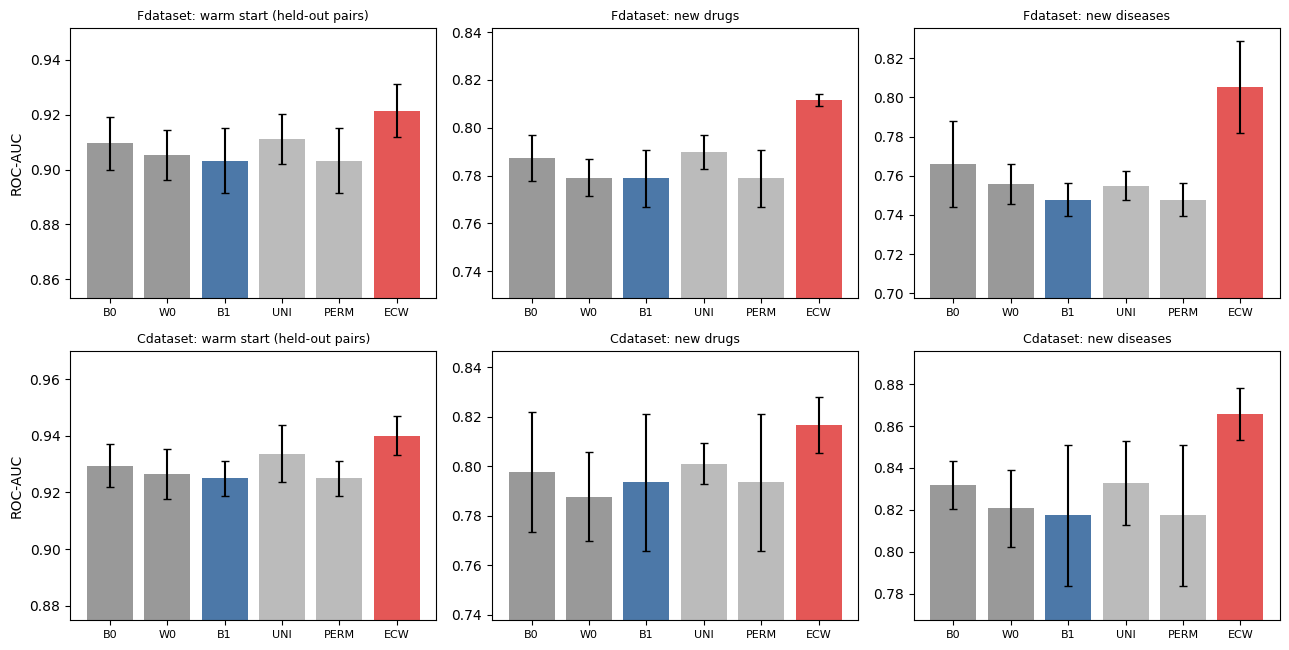

In [7]:
SET = {"warm": "warm start (held-out pairs)", "cold_drug": "new drugs", "cold_disease": "new diseases"}
CELLS = [(tag, st) for tag in LOADED for st in ("warm", "cold_drug", "cold_disease")]
for tag, st in CELLS:
    df = RES[(RES.dataset == tag) & (RES.setting == st)]
    if df.empty: continue
    P = {v: seed_pivot(df, "model", v).dropna() for v in ("auc", "aupr", "rec10")}; T = P["auc"]; key = (LOADED[tag].name, SET[st])
    print("=" * 112); print(f"{LOADED[tag].name} | {SET[st]} | {len(T)} seeds")
    order = ["B0", "W0", "B1", "UNI", "PERM", "ECW"]
    display(pd.DataFrame({k_: P[k_].mean() for k_ in ("auc", "aupr", "rec10")}).T[order].round(4).rename(index={"auc": "ROC-AUC", "aupr": "AUPR", "rec10": "recall@10"}))
    d1 = T["ECW"] - T["B1"]; lab1, s1 = label_gain(d1); lab0, s0 = label_gain(T["ECW"] - T["B0"])
    PRIMARY[key] = dict(p=one_sided_p(d1, DELTA, "gt"), label=lab1, ev=f"ECW - B1 = {s1['mean']:+.4f} [{s1['ci_lo']:+.4f}, {s1['ci_hi']:+.4f}]",
                        label_B0=lab0, ev_B0=f"ECW - B0 = {s0['mean']:+.4f} [{s0['ci_lo']:+.4f}, {s0['ci_hi']:+.4f}]")
    cu, cp = pstats(T["ECW"] - T["UNI"]), pstats(T["ECW"] - T["PERM"]); ok = (cu["ci_lo"] > 0) and (cp["ci_lo"] > 0)
    SECOND[key] = dict(mechanism="SUPPORTED" if ok else "NOT SUPPORTED", ev=f"ECW-UNI {cu['mean']:+.4f} [{cu['ci_lo']:+.4f}, {cu['ci_hi']:+.4f}]; ECW-PERM {cp['mean']:+.4f} [{cp['ci_lo']:+.4f}, {cp['ci_hi']:+.4f}]",
                       aupr=pstats(P["aupr"]["ECW"] - P["aupr"]["B1"]), rec=pstats(P["rec10"]["ECW"] - P["rec10"]["B1"]))
    display(pd.DataFrame([crow("P1  ROC-AUC: ECW - B1 (tuned baseline)  [primary]", d1), crow("P4  ROC-AUC: ECW - B0 (published parameters)", T["ECW"] - T["B0"]),
                          crow("    ROC-AUC: B1 - B0 (what tuning alone buys)", T["B1"] - T["B0"]),
                          crow("P2a ROC-AUC: ECW - UNI (uniform down-weight)", T["ECW"] - T["UNI"]), crow("P2b ROC-AUC: ECW - PERM (permuted coverage)", T["ECW"] - T["PERM"]),
                          crow("P3  AUPR: ECW - B1", P["aupr"]["ECW"] - P["aupr"]["B1"]), crow("P3  recall@10: ECW - B1", P["rec10"]["ECW"] - P["rec10"]["B1"]),
                          crow("    ROC-AUC: ECW - W0 (untuned, no WKNN)", T["ECW"] - T["W0"])]).set_index("contrast").round(4))
    print(f"P1 [{LOADED[tag].name}, {SET[st]}]: {lab1}  |  {PRIMARY[key]['ev']}   (STRONG needs lower bound > {DELTA})")
    print(f"P2 mechanism: {SECOND[key]['mechanism']}  |  {SECOND[key]['ev']}")
    sel = df[df.model.isin(["ECW", "B1"])].groupby("model")["cfg"].agg(lambda x: x.value_counts().index[0]); print("most frequent selected configs:", sel.to_dict())

fig, axs = plt.subplots(len(LOADED), 3, figsize=(13, 3.3 * len(LOADED)), squeeze=False)
for i, tag in enumerate(LOADED):
    for j, st in enumerate(("warm", "cold_drug", "cold_disease")):
        df = RES[(RES.dataset == tag) & (RES.setting == st)]
        if df.empty: continue
        T = seed_pivot(df, "model").dropna(); cols = ["B0", "W0", "B1", "UNI", "PERM", "ECW"]
        mu, ci = T[cols].mean(), T[cols].sem() * stats.t.ppf(0.975, max(len(T) - 1, 1))
        axs[i, j].bar(cols, mu.values, yerr=ci.values, capsize=3, color=["#999"] * 2 + ["#4C78A8"] + ["#BBB"] * 2 + ["#E45756"])
        axs[i, j].set_ylim(max(0.5, mu.min() - 0.05), min(1.0, mu.max() + 0.03)); axs[i, j].set_title(f"{LOADED[tag].name}: {SET[st]}", fontsize=9); axs[i, j].tick_params(axis="x", labelsize=8)
        if j == 0: axs[i, j].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

---
# Mechanism readouts (exploratory, not gating)
**M1 — Where does the gain come from?** AUC of held-out positives stratified by the *training coverage of the weaker of their two entities*, one warm split per dataset, B1 vs ECW against the same negatives.
**M2 — What happens to the scores of poorly annotated entities?** Mean score of unknown pairs per coverage bin.

In [8]:
rows, rows2 = [], []
for tag, D in LOADED.items():
    sp = pair_split(D, SEED0, 0); Ytr = sp.Ytr; fs = 1000 * SEED0
    cfgs = {}
    for fam, name in (("base", "B1"), ("ecw", "ECW")):
        cfgs[name], _ = tune(Ytr, D, (SEED0, 0, 0, 51), "pair", fam, fs)
    S = {name: fit_scores(Ytr, D, "real", c["kappa"], None, c["lam"], c["beta"], fs, MAX_ITER)[0] for name, c in cfgs.items()}
    print(f"[{D.name}] selected: B1 {cfgs['B1']}  ECW {cfgs['ECW']}")
    ti, tj = sp.pos // D.m, sp.pos % D.m; cov = np.minimum(Ytr.sum(1)[ti], Ytr.sum(0)[tj])
    bins = [(0, 0, "0"), (1, 1, "1"), (2, 3, "2-3"), (4, 9, "4-9"), (10, 10**9, "10+")]
    for lo, hi, nm in bins:
        sel = (cov >= lo) & (cov <= hi)
        if sel.sum() < 5: continue
        r = dict(dataset=D.name, min_train_assoc_of_the_pair=nm, held_out_positives=int(sel.sum()))
        for name, Sc in S.items(): r[f"AUC_{name}"] = auc_vs(Sc.ravel()[sp.pos][sel], np.sort(Sc.ravel()[sp.neg]))
        r["gain"] = r["AUC_ECW"] - r["AUC_B1"]; rows.append(r)
    cR = np.minimum(Ytr.sum(1)[:, None], Ytr.sum(0)[None, :]); unk = (Ytr == 0)
    for lo, hi, nm in bins:
        sel = unk & (cR >= lo) & (cR <= hi)
        if sel.sum() < 100: continue
        rows2.append(dict(dataset=D.name, min_train_assoc_of_the_pair=nm, mean_score_B1=S["B1"][sel].mean(), mean_score_ECW=S["ECW"][sel].mean(), ratio=S["ECW"][sel].mean() / max(S["B1"][sel].mean(), 1e-12)))
display(pd.DataFrame(rows).round(4)); display(pd.DataFrame(rows2).round(5))
print("Reading: a gain concentrated in the low-coverage rows, with ECW scoring unknown pairs of poorly annotated entities higher (ratio > 1), is the intended mechanism; "
      "the same raise can push those pairs into the global top ranks, which is why pooled AUPR is reported separately.")

[Fdataset] selected: B1 {'kappa': 0.0, 'alpha': 1.0, 'lam': 2.0, 'beta': 0.02}  ECW {'kappa': 1.0, 'alpha': 1.0, 'lam': 1.0, 'beta': 0.1}
[Cdataset] selected: B1 {'kappa': 0.0, 'alpha': 1.0, 'lam': 1.0, 'beta': 0.02}  ECW {'kappa': 0.3, 'alpha': 1.0, 'lam': 1.0, 'beta': 0.1}


,dataset,min_train_assoc_of_the_pair,held_out_positives,AUC_B1,AUC_ECW,gain
0,Fdataset,0,129,0.7418,0.8822,0.1404
1,Fdataset,1,149,0.8984,0.8995,0.0011
2,Fdataset,2-3,224,0.9581,0.9439,-0.0142
3,Fdataset,4-9,138,0.9663,0.9503,-0.0160
4,Fdataset,10+,5,0.9957,0.9916,-0.0041
5,Cdataset,0,153,0.7968,0.8918,0.0950
6,Cdataset,1,157,0.9313,0.9230,-0.0083
7,Cdataset,2-3,296,0.9726,0.9695,-0.0031
8,Cdataset,4-9,223,0.9757,0.9717,-0.0040
9,Cdataset,10+,15,0.9960,0.9948,-0.0013


,dataset,min_train_assoc_of_the_pair,mean_score_B1,mean_score_ECW,ratio
0,Fdataset,0,0.00397,0.01483,3.73467
1,Fdataset,1,0.00655,0.01155,1.76234
2,Fdataset,2-3,0.01052,0.01489,1.41541
3,Fdataset,4-9,0.01821,0.02147,1.17902
4,Fdataset,10+,0.03054,0.03221,1.05461
5,Cdataset,0,0.00243,0.00951,3.91678
6,Cdataset,1,0.00449,0.00604,1.34484
7,Cdataset,2-3,0.00813,0.00968,1.19086
8,Cdataset,4-9,0.01398,0.01549,1.10762
9,Cdataset,10+,0.02781,0.02925,1.05165


Reading: a gain concentrated in the low-coverage rows, with ECW scoring unknown pairs of poorly annotated entities higher (ratio > 1), is the intended mechanism; the same raise can push those pairs into the global top ranks, which is why pooled AUPR is reported separately.


---
# Consolidated evidence and verdict
Primary Holm family = the six P1 tests (**small p ⇒ ECW exceeds the tuned baseline by more than δ**). P2–P4 are descriptive and carry their own intervals above.

,dataset,setting,label,evidence_vs_tuned_baseline,p_raw,label_vs_published,evidence_vs_published,p_holm
0,Fdataset,warm start (held-out pairs),STRONG,"ECW - B1 = +0.0183 [+0.0135, +0.0230]",0.0086,POSITIVE,"ECW - B0 = +0.0120 [+0.0077, +0.0162]",0.0431
1,Fdataset,new drugs,STRONG,"ECW - B1 = +0.0326 [+0.0230, +0.0422]",0.0048,STRONG,"ECW - B0 = +0.0242 [+0.0131, +0.0352]",0.0287
2,Fdataset,new diseases,STRONG,"ECW - B1 = +0.0576 [+0.0272, +0.0880]",0.0106,STRONG,"ECW - B0 = +0.0394 [+0.0232, +0.0557]",0.0431
3,Cdataset,warm start (held-out pairs),STRONG,"ECW - B1 = +0.0150 [+0.0120, +0.0180]",0.0096,POSITIVE,"ECW - B0 = +0.0104 [+0.0063, +0.0145]",0.0431
4,Cdataset,new drugs,POSITIVE,"ECW - B1 = +0.0232 [+0.0068, +0.0395]",0.0371,POSITIVE,"ECW - B0 = +0.0190 [+0.0060, +0.0319]",0.0590
5,Cdataset,new diseases,POSITIVE,"ECW - B1 = +0.0485 [+0.0064, +0.0907]",0.0295,STRONG,"ECW - B0 = +0.0341 [+0.0303, +0.0379]",0.0590


P1 aggregate: PARTIAL: STRONG in 4/6 cells
P2 mechanism (ECW beats both uniform and permuted-coverage controls): {('Fdataset', 'warm start (held-out pairs)'): 'SUPPORTED', ('Fdataset', 'new drugs'): 'SUPPORTED', ('Fdataset', 'new diseases'): 'SUPPORTED', ('Cdataset', 'warm start (held-out pairs)'): 'SUPPORTED', ('Cdataset', 'new drugs'): 'SUPPORTED', ('Cdataset', 'new diseases'): 'SUPPORTED'}

P3 trade-off table (ECW - tuned baseline; negative = ECW worse):


,dataset,setting,d_AUPR,AUPR_ci,d_recall10,rec_ci
0,Fdataset,warm start (held-out pairs),-0.0343,"[-0.046, -0.023]",0.0031,"[-0.020, +0.026]"
1,Fdataset,new drugs,0.0201,"[-0.023, +0.063]",0.0137,"[-0.003, +0.030]"
2,Fdataset,new diseases,0.0207,"[+0.008, +0.033]",0.0240,"[-0.002, +0.050]"
3,Cdataset,warm start (held-out pairs),-0.0568,"[-0.089, -0.024]",-0.0070,"[-0.020, +0.006]"
4,Cdataset,new drugs,0.0253,"[+0.022, +0.029]",0.0234,"[+0.004, +0.043]"
5,Cdataset,new diseases,0.0291,"[-0.024, +0.082]",0.0163,"[-0.012, +0.045]"


share of final fits that stopped at the iteration cap (300): 0.0%
saved: /kaggle/working/ecw_results_quick_s0.csv, ecw_primary_*.csv, ecw_tradeoff_*.csv in /kaggle/working
Settings: profile=quick, seeds=[0, 1, 2], folds=3, max_iter=300, delta=0.01. Conditional on these two datasets; negatives are unobserved pairs.


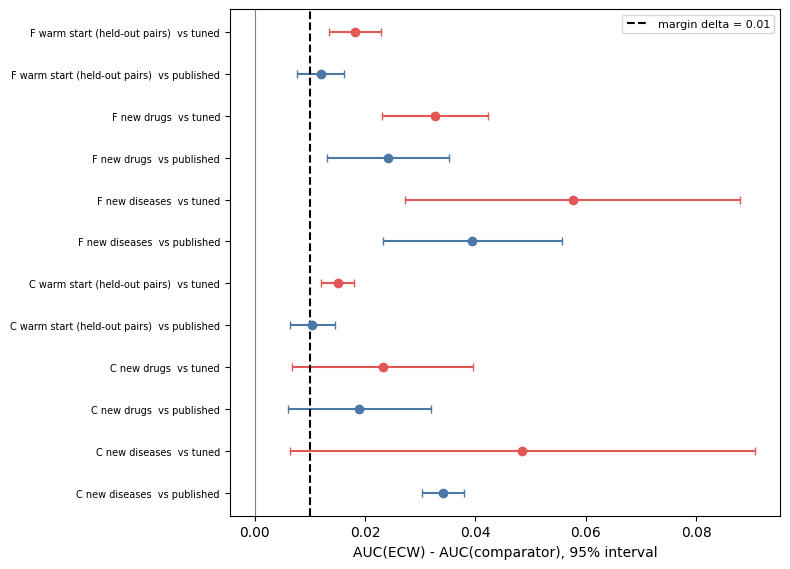

In [9]:
keys = list(PRIMARY)
tab = pd.DataFrame([dict(dataset=k[0], setting=k[1], label=PRIMARY[k]["label"], evidence_vs_tuned_baseline=PRIMARY[k]["ev"], p_raw=PRIMARY[k]["p"],
                         label_vs_published=PRIMARY[k]["label_B0"], evidence_vs_published=PRIMARY[k]["ev_B0"]) for k in keys])
tab["p_holm"] = holm(tab.p_raw.values); display(tab.round(4))
n_strong = int((tab.label == "STRONG").sum()); n = len(tab)
if n == 0: agg = "NO DATA"
elif n_strong == n: agg = f"SUPPORTED: STRONG in all {n} cells"
elif n_strong > 0: agg = f"PARTIAL: STRONG in {n_strong}/{n} cells"
elif (tab.label.isin(["STRONG", "POSITIVE"])).all(): agg = "POSITIVE ONLY: improvement is detectable in every cell but not above the margin"
else: agg = "NOT SUPPORTED"
print("P1 aggregate:", agg)
print("P2 mechanism (ECW beats both uniform and permuted-coverage controls):", {k: SECOND[k]["mechanism"] for k in keys})
trade = pd.DataFrame([dict(dataset=k[0], setting=k[1], d_AUPR=SECOND[k]["aupr"]["mean"], AUPR_ci=f"[{SECOND[k]['aupr']['ci_lo']:+.3f}, {SECOND[k]['aupr']['ci_hi']:+.3f}]",
                           d_recall10=SECOND[k]["rec"]["mean"], rec_ci=f"[{SECOND[k]['rec']['ci_lo']:+.3f}, {SECOND[k]['rec']['ci_hi']:+.3f}]") for k in keys])
print("\nP3 trade-off table (ECW - tuned baseline; negative = ECW worse):"); display(trade.round(4))
w = RES[RES.model.isin(["B0", "B1", "ECW"]) & RES.n_iter.notna()]
print(f"share of final fits that stopped at the iteration cap ({MAX_ITER}): {(w.n_iter >= MAX_ITER).mean():.1%}")
tab.to_csv(os.path.join(OUT_DIR, f"ecw_primary_{PROFILE}_s{SEED0}.csv"), index=False); trade.to_csv(os.path.join(OUT_DIR, f"ecw_tradeoff_{PROFILE}_s{SEED0}.csv"), index=False)
print(f"saved: {RES_PATH}, ecw_primary_*.csv, ecw_tradeoff_*.csv in {OUT_DIR}")
print(f"Settings: profile={PROFILE}, seeds={SEEDS}, folds={N_FOLDS}, max_iter={MAX_ITER}, delta={DELTA}. Conditional on these two datasets; negatives are unobserved pairs.")

items = []
for k in keys:
    df = RES[(RES.dataset == k[0][0]) & (RES.setting == [s for s, v in SET.items() if v == k[1]][0])]
    T = seed_pivot(df, "model").dropna(); items.append((f"{k[0][0]} {k[1]}  vs tuned", pstats(T["ECW"] - T["B1"]))); items.append((f"{k[0][0]} {k[1]}  vs published", pstats(T["ECW"] - T["B0"])))
fig, ax = plt.subplots(figsize=(8, 0.35 * len(items) + 1.6))
for i, (lab, s) in enumerate(items):
    ax.errorbar(s["mean"], i, xerr=[[s["mean"] - s["ci_lo"]], [s["ci_hi"] - s["mean"]]] if np.isfinite(s["ci_lo"]) else None, fmt="o", capsize=3, color="#E45756" if "tuned" in lab else "#4C78A8")
ax.axvline(DELTA, ls="--", c="k", label=f"margin delta = {DELTA}"); ax.axvline(0, c="grey", lw=0.8)
ax.set_yticks(range(len(items))); ax.set_yticklabels([x[0] for x in items], fontsize=7); ax.invert_yaxis(); ax.set_xlabel("AUC(ECW) - AUC(comparator), 95% interval"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [10]:
# ===================== SPECTRAL HEAT-KERNEL OPERATORS =====================
import numpy as np

def heat_kernel_operator(Sg, t=1.0, eps=1e-12):
    """
    Construct a graph heat kernel H = exp(-t L_sym).

    Sg: symmetric, nonnegative similarity graph with zero diagonal.
    t : diffusion scale; larger t means stronger smoothing.
    """
    Sg = np.asarray(Sg, dtype=np.float64)
    Sg = 0.5 * (Sg + Sg.T)
    np.fill_diagonal(Sg, 0.0)

    degree = Sg.sum(axis=1)
    inv_sqrt_degree = np.zeros_like(degree)
    nonisolated = degree > eps
    inv_sqrt_degree[nonisolated] = 1.0 / np.sqrt(degree[nonisolated])

    # Symmetric normalized Laplacian: eigenvalues are in [0, 2]
    L = np.eye(Sg.shape[0]) - (
        inv_sqrt_degree[:, None] * Sg * inv_sqrt_degree[None, :]
    )

    # An isolated node should have zero Laplacian, not diagonal value 1.
    L[~nonisolated, :] = 0.0
    L[:, ~nonisolated] = 0.0

    eigenvalues, U = np.linalg.eigh(L)
    eigenvalues = np.maximum(eigenvalues, 0.0)

    # H = U exp(-t Lambda) U^T
    H = (U * np.exp(-t * eigenvalues)[None, :]) @ U.T
    H = 0.5 * (H + H.T)

    # The quadratic penalty ||A - A H||_F^2 = Tr(A Q A^T)
    I = np.eye(Sg.shape[0])
    R = I - H
    Q = R @ R
    Q = 0.5 * (Q + Q.T)

    # Elementwise positive/negative split for multiplicative updates
    Q_pos = np.maximum(Q, 0.0)
    Q_neg = np.maximum(-Q, 0.0)

    return H, Q_pos, Q_neg, eigenvalues


# Precompute once per dataset and diffusion scale.
# The same operators can be reused across folds because the similarity
# graphs are fixed; association labels are not used to build them.
print("Heat-kernel function ready.")

Heat-kernel function ready.


In [11]:
# ===================== SPECTRAL HEAT-KERNEL NMF =====================

def spectral_wnmf_fit(
    M, Wt, Qpos_R, Qneg_R, Qpos_D, Qneg_D,
    k, lam_R, lam_D, beta,
    max_iter, seed, tol=1e-4, trace=False
):
    """
    Nonnegative matrix factorisation with heat-kernel spectral penalties.

    M       : target association matrix, shape (n_drugs, n_diseases)
    Wt      : elementwise reconstruction weights
    Qpos_*  : elementwise positive part of Q = (I - H)^2
    Qneg_*  : elementwise negative part of Q = (I - H)^2

    A shape: (k, n_drugs)
    B shape: (k, n_diseases)

    This initial implementation uses NumPy/CPU deliberately so that
    correctness can be audited before adding a GPU implementation.
    """
    M = np.asarray(M, dtype=np.float64)
    Wt = np.asarray(Wt, dtype=np.float64)

    n, m = M.shape
    rng = np.random.default_rng(seed)
    c = 2 * np.sqrt(max(M.mean(), 1e-8) / k)

    A = rng.random((k, n)) * c + 1e-6
    B = rng.random((k, m)) * c + 1e-6

    WM = Wt * M
    obj = []

    def objective(A, B):
        X = A.T @ B
        fit = np.sum(Wt * (M - X) ** 2)
        reg_R = lam_R * np.sum((A @ (Qpos_R - Qneg_R)) * A)
        reg_D = lam_D * np.sum((B @ (Qpos_D - Qneg_D)) * B)
        ridge = beta * (np.sum(A**2) + np.sum(B**2))
        return float(fit + reg_R + reg_D + ridge)

    if trace:
        obj.append(objective(A, B))

    for it in range(1, max_iter + 1):
        X = A.T @ B

        # Update drug factors A
        numerator_A = (
            B @ WM.T
            + lam_R * (A @ Qneg_R)
        )
        denominator_A = (
            B @ (Wt * X).T
            + lam_R * (A @ Qpos_R)
            + beta * A
            + EPS
        )
        A_new = A * numerator_A / denominator_A
        A_new = np.maximum(A_new, EPS)

        # Update disease factors B, using the updated A
        X_new = A_new.T @ B
        numerator_B = (
            A_new @ WM
            + lam_D * (B @ Qneg_D)
        )
        denominator_B = (
            A_new @ (Wt * X_new)
            + lam_D * (B @ Qpos_D)
            + beta * B
            + EPS
        )
        B_new = B * numerator_B / denominator_B
        B_new = np.maximum(B_new, EPS)

        err = max(
            np.max(np.sum((A_new - A) ** 2, axis=0)),
            np.max(np.sum((B_new - B) ** 2, axis=0))
        )

        A, B = A_new, B_new

        if trace:
            obj.append(objective(A, B))

        if err < tol:
            break

    if trace:
        return A, B, it, obj
    return A, B, it

In [12]:
# ===================== OPERATOR CACHE + SCORING WRAPPER =====================

SPECTRAL_CACHE = {}

def get_spectral_operators(D, t):
    key = (D.tag, float(t))

    if key not in SPECTRAL_CACHE:
        HR, QpR, QnR, eigR = heat_kernel_operator(D.SgR, t=t)
        HD, QpD, QnD, eigD = heat_kernel_operator(D.SgD, t=t)

        SPECTRAL_CACHE[key] = {
            "HR": HR, "QpR": QpR, "QnR": QnR,
            "HD": HD, "QpD": QpD, "QnD": QnD,
            "eigR": eigR, "eigD": eigD
        }

    return SPECTRAL_CACHE[key]


def spectral_fit_scores(Ytr, D, t, lam, beta, seed, iters,
                        tol=1e-4, weights=None):
    """
    Fit SH-WNMFDDA and return predicted association scores and iteration count.

    Start with weights=None, which means ordinary squared reconstruction loss.
    """
    ops = get_spectral_operators(D, t)

    if weights is None:
        weights = np.ones_like(Ytr, dtype=np.float64)

    A, B, n_iter = spectral_wnmf_fit(
        M=Ytr,
        Wt=weights,
        Qpos_R=ops["QpR"],
        Qneg_R=ops["QnR"],
        Qpos_D=ops["QpD"],
        Qneg_D=ops["QnD"],
        k=PAPER["k"],
        lam_R=lam,
        lam_D=lam,
        beta=beta,
        max_iter=iters,
        seed=seed,
        tol=tol
    )

    return A.T @ B, n_iter


print("Spectral scoring wrapper ready.")

Spectral scoring wrapper ready.


In [13]:
# ===================== SPECTRAL CORRECTNESS AUDIT =====================

rng = np.random.default_rng(7)
n, m, k = 25, 18, 5

def random_graph(n, rng):
    S = rng.random((n, n))
    S[S < 0.7] = 0.0
    S = 0.5 * (S + S.T)
    np.fill_diagonal(S, 0.0)
    return S

SR_test = random_graph(n, rng)
SD_test = random_graph(m, rng)
Y_test = (rng.random((n, m)) < 0.12).astype(float)

_, QpR, QnR, eigR = heat_kernel_operator(SR_test, t=1.0)
_, QpD, QnD, eigD = heat_kernel_operator(SD_test, t=1.0)

A, B, n_iter, obj = spectral_wnmf_fit(
    M=Y_test,
    Wt=np.ones_like(Y_test),
    Qpos_R=QpR, Qneg_R=QnR,
    Qpos_D=QpD, Qneg_D=QnD,
    k=k,
    lam_R=1.0,
    lam_D=1.0,
    beta=0.02,
    max_iter=500,
    seed=11,
    tol=0.0,
    trace=True
)

scores = A.T @ B
objective_differences = np.diff(obj)

print("Iterations:", n_iter)
print("Initial objective:", obj[0])
print("Final objective:", obj[-1])
print("Largest objective increase:", objective_differences.max(initial=0.0))
print("Score shape:", scores.shape)
print("All scores finite:", np.isfinite(scores).all())
print("Factors nonnegative:", (A >= 0).all() and (B >= 0).all())
print("Drug Laplacian eigenvalue range:", eigR.min(), eigR.max())
print("Disease Laplacian eigenvalue range:", eigD.min(), eigD.max())

# The multiplicative update should be checked rather than assumed monotone.
if objective_differences.max(initial=0.0) > 1e-7:
    print(
        "WARNING: objective increased. Do not trust full results yet; "
        "check the update derivation or switch to a suitable projected-gradient optimiser."
    )
else:
    print("Audit passed the objective non-increase check for this test.")

Iterations: 500
Initial objective: 48.311736682085844
Final objective: 25.72876488187369
Largest objective increase: 0.0
Score shape: (25, 18)
All scores finite: True
Factors nonnegative: True
Drug Laplacian eigenvalue range: 1.2917590227027888e-17 1.485440019926928
Disease Laplacian eigenvalue range: 0.0 1.443242203051825
Audit passed the objective non-increase check for this test.


In [14]:
# ===================== INITIAL PAIRED COMPARISON =====================

T_GRID = [0.1, 1.0, 10.0]
LAM_GRID = [0.5, 1.0, 2.0]
BETA_GRID = [0.02, 0.1]

screening_rows = []

for tag, D in LOADED.items():
    split = pair_split(D, seed=SEED0, fold=0)
    Ytr = split.Ytr

    # Baseline and spectral models use the same training labels,
    # held-out positives, negatives, rank, and random initialisation seed.
    for lam in LAM_GRID:
        for beta in BETA_GRID:
            baseline_scores, baseline_it = wnmf_fit(
                M=Ytr,
                Wt=np.ones_like(Ytr),
                SgR=D.SgR,
                SgD=D.SgD,
                k=PAPER["k"],
                lam=lam,
                beta=beta,
                max_iter=MAX_ITER,
                seed=SEED0,
                tol=1e-4
            )[:2] if False else (None, None)

            # Fit baseline correctly and obtain its score matrix.
            A0, B0, baseline_it = wnmf_fit(
                Ytr, np.ones_like(Ytr), D.SgR, D.SgD,
                PAPER["k"], lam, beta, MAX_ITER, SEED0
            )
            S0 = A0.T @ B0
            baseline_metrics = metrics(S0, split.pos, split.neg)

            screening_rows.append({
                "dataset": tag, "model": "Laplacian",
                "t": np.nan, "lam": lam, "beta": beta,
                "auc": baseline_metrics["auc"],
                "aupr": baseline_metrics["aupr"],
                "iterations": baseline_it
            })

            for t in T_GRID:
                Ss, spectral_it = spectral_fit_scores(
                    Ytr, D, t=t, lam=lam, beta=beta,
                    seed=SEED0, iters=MAX_ITER
                )
                spectral_metrics = metrics(Ss, split.pos, split.neg)

                screening_rows.append({
                    "dataset": tag, "model": "HeatKernel",
                    "t": t, "lam": lam, "beta": beta,
                    "auc": spectral_metrics["auc"],
                    "aupr": spectral_metrics["aupr"],
                    "iterations": spectral_it
                })

SCREEN = pd.DataFrame(screening_rows)
display(
    SCREEN.sort_values(
        ["dataset", "auc"], ascending=[True, False]
    ).groupby("dataset", group_keys=False).head(12).round(4)
)

,dataset,model,t,lam,beta,auc,aupr,iterations
40,C,Laplacian,NaN,2.0,0.02,0.9355,0.3567,80
46,C,HeatKernel,1.0,2.0,0.10,0.9354,0.3584,143
44,C,Laplacian,NaN,2.0,0.10,0.9350,0.3606,75
36,C,Laplacian,NaN,1.0,0.10,0.9343,0.4198,120
32,C,Laplacian,NaN,1.0,0.02,0.9343,0.4122,125
42,C,HeatKernel,1.0,2.0,0.02,0.9312,0.3396,257
38,C,HeatKernel,1.0,1.0,0.10,0.9289,0.2504,99
28,C,Laplacian,NaN,0.5,0.10,0.9286,0.4042,150
24,C,Laplacian,NaN,0.5,0.02,0.9282,0.3943,210
34,C,HeatKernel,1.0,1.0,0.02,0.9270,0.2399,225


In [1]:
# ===================== MS-PU-GNMF: GRAPH OPERATORS =====================
import numpy as np
import time
from scipy import stats

MS_TIMES = (0.25, 1.0, 4.0)
MS_KAPPA = 1.0
MS_ETA = 0.8
MS_W_MIN = 0.05
MS_CACHE = {}
MS_SIM_CACHE = {}

def ms_normalized_laplacian(Sg, eps=1e-12):
    """Symmetric normalized graph Laplacian; isolated nodes have zero rows/columns."""
    S = np.asarray(Sg, dtype=np.float64)
    S = np.maximum((S + S.T) / 2.0, 0.0).copy()
    np.fill_diagonal(S, 0.0)

    degree = S.sum(axis=1)
    inv_sqrt = np.zeros_like(degree)
    valid = degree > eps
    inv_sqrt[valid] = 1.0 / np.sqrt(degree[valid])

    L = np.diag(valid.astype(float)) - inv_sqrt[:, None] * S * inv_sqrt[None, :]
    return (L + L.T) / 2.0


def ms_unnormalized_laplacian(Sg):
    """Standard combinatorial Laplacian D - S."""
    S = np.asarray(Sg, dtype=np.float64)
    S = np.maximum((S + S.T) / 2.0, 0.0).copy()
    np.fill_diagonal(S, 0.0)
    return np.diag(S.sum(axis=1)) - S


def ms_spectral_operator(Sg, times=MS_TIMES, scale_weights=None):
    """
    Construct Q = sum_s pi_s (I - exp(-t_s L))^2.
    Returns normalized L, its max eigenvalue, Q, and max eigenvalue of Q.
    """
    times = tuple(float(t) for t in times)
    if any(t <= 0 for t in times):
        raise ValueError("Every heat-kernel time must be positive.")

    if scale_weights is None:
        scale_weights = np.ones(len(times), dtype=float) / len(times)
    scale_weights = np.asarray(scale_weights, dtype=float)

    if len(scale_weights) != len(times) or np.any(scale_weights < 0):
        raise ValueError("Invalid scale weights.")
    if scale_weights.sum() <= 0:
        raise ValueError("Scale weights must sum to a positive value.")
    scale_weights = scale_weights / scale_weights.sum()

    L = ms_normalized_laplacian(Sg)
    eigvals, U = np.linalg.eigh(L)
    eigvals = np.clip(eigvals, 0.0, None)

    q_eig = np.zeros_like(eigvals)
    for t, pi in zip(times, scale_weights):
        q_eig += pi * (1.0 - np.exp(-t * eigvals)) ** 2

    # U diag(q_eig) U.T, without creating an explicit diagonal matrix
    Q = (U * q_eig[None, :]) @ U.T
    Q = (Q + Q.T) / 2.0

    return L, float(eigvals.max()), Q, float(q_eig.max())


def ms_get_operators(D, times=MS_TIMES):
    """Cache graph operators: recomputing eigendecompositions is expensive."""
    times = tuple(float(t) for t in times)
    key = (D.tag, times)

    if key not in MS_CACHE:
        Lru = ms_unnormalized_laplacian(D.SgR)
        Ldu = ms_unnormalized_laplacian(D.SgD)

        Lrn, qmax_rn, Qrs, qmax_rs = ms_spectral_operator(D.SgR, times)
        Ldn, qmax_dn, Qds, qmax_ds = ms_spectral_operator(D.SgD, times)

        qmax_ru = max(0.0, float(np.linalg.eigvalsh(Lru)[-1]))
        qmax_du = max(0.0, float(np.linalg.eigvalsh(Ldu)[-1]))

        MS_CACHE[key] = {
            "Lru": Lru, "Ldu": Ldu,
            "qmax_ru": qmax_ru, "qmax_du": qmax_du,
            "Lrn": Lrn, "Ldn": Ldn,
            "qmax_rn": qmax_rn, "qmax_dn": qmax_dn,
            "Qrs": Qrs, "Qds": Qds,
            "qmax_rs": qmax_rs, "qmax_ds": qmax_ds,
        }

    return MS_CACHE[key]


# ===================== MS-PU-GNMF: CONFIDENCE WEIGHTS =====================

def ms_row_stochastic_similarity(S, eps=1e-12):
    """Non-negative similarity matrix with zero diagonal and rows summing to 1."""
    S = np.maximum(np.asarray(S, dtype=np.float64), 0.0).copy()
    np.fill_diagonal(S, 0.0)
    row_sum = S.sum(axis=1, keepdims=True)
    return np.divide(S, row_sum, out=np.zeros_like(S), where=row_sum > eps)


def ms_confidence_components(Ytr, D, kappa=MS_KAPPA):
    """
    Construct label-derived components from Ytr only.
    support[i,j] estimates neighbor support for the drug-disease pair.
    coverage[i,j] reflects the annotation coverage of both entities.
    """
    if D.tag not in MS_SIM_CACHE:
        MS_SIM_CACHE[D.tag] = (
            ms_row_stochastic_similarity(D.SR),
            ms_row_stochastic_similarity(D.SD),
        )

    SRn, SDn = MS_SIM_CACHE[D.tag]
    Ytr = np.asarray(Ytr, dtype=np.float64)

    # Similarity-propagated association support, bounded approximately in [0, 1].
    support = np.clip(SRn @ Ytr @ SDn.T, 0.0, 1.0)

    cov_r = Ytr.sum(axis=1)
    cov_d = Ytr.sum(axis=0)
    rel_r = cov_r / (cov_r + kappa)
    rel_d = cov_d / (cov_d + kappa)
    coverage = rel_r[:, None] * rel_d[None, :]

    return coverage, support


def ms_make_confidence_weights(
    Ytr, coverage, support, eta=MS_ETA, w_min=MS_W_MIN
):
    """
    Positive training pairs retain weight 1.
    Unknown pairs have lower weight when entity coverage is low or neighbor
    support is high. These are heuristic confidence weights, not calibrated
    probabilities that a pair is negative.
    """
    if not 0.0 <= eta <= 1.0:
        raise ValueError("eta must be in [0, 1].")
    if not 0.0 < w_min <= 1.0:
        raise ValueError("w_min must be in (0, 1].")

    unknown_weight = coverage * (1.0 - eta * support)
    unknown_weight = np.clip(unknown_weight, w_min, 1.0)
    return np.where(np.asarray(Ytr) > 0, 1.0, unknown_weight)


print("MS-PU-GNMF graph and confidence-weight functions ready.")

MS-PU-GNMF graph and confidence-weight functions ready.


In [2]:
# ===================== MS-PU-GNMF: OBJECTIVE + OPTIMIZER =====================

def ms_objective(A, B, Y, C, QR, QD, lam, beta):
    """Full objective; lambda is shared by both graph penalties."""
    residual = Y - A.T @ B

    reconstruction = np.sum(C * residual**2)
    drug_graph = np.sum((A @ QR) * A)
    disease_graph = np.sum((B @ QD) * B)
    ridge = np.sum(A**2) + np.sum(B**2)

    return float(
        reconstruction
        + lam * drug_graph
        + lam * disease_graph
        + beta * ridge
    )


def ms_projected_gradient_step(X, grad, objective_fn, lipschitz,
                               max_backtracks=30):
    """
    Non-negative projected-gradient step with a backtracking check.
    Raises an error rather than silently accepting an invalid step.
    """
    f0 = objective_fn(X)
    L = max(float(lipschitz), 1e-8)

    for _ in range(max_backtracks):
        X_new = np.maximum(X - grad / L, 0.0)
        delta = X_new - X

        upper_bound = (
            f0
            + np.sum(grad * delta)
            + 0.5 * L * np.sum(delta**2)
        )
        f_new = objective_fn(X_new)

        if (
            np.isfinite(f_new)
            and f_new <= upper_bound + 1e-10 * max(1.0, abs(f0))
        ):
            return X_new, L

        L *= 2.0

    raise RuntimeError(
        "Backtracking failed. Check graph operators, weights and numerical stability."
    )


def ms_fit_weighted_graph_nmf(
    Y, C, QR, QD,
    lam=1.0, beta=0.02, k=80,
    max_iter=150, seed=0, tol=1e-5,
    qmaxR=None, qmaxD=None, trace=False,
):
    """
    Fit non-negative graph-regularized matrix factorization.

    Y:       (n_drugs, n_diseases), training association matrix
    C:       reconstruction weights, same shape as Y
    QR:      (n_drugs, n_drugs) PSD drug regularizer
    QD:      (n_diseases, n_diseases) PSD disease regularizer

    Returns A, B, iterations; with trace=True also returns objective history.
    """
    Y = np.asarray(Y, dtype=np.float64)
    C = np.asarray(C, dtype=np.float64)
    QR = np.asarray(QR, dtype=np.float64)
    QD = np.asarray(QD, dtype=np.float64)

    n, m = Y.shape
    if C.shape != (n, m) or QR.shape != (n, n) or QD.shape != (m, m):
        raise ValueError("Y, C, QR and QD have incompatible shapes.")
    if np.any(C < 0) or np.any(~np.isfinite(C)):
        raise ValueError("C must contain finite non-negative weights.")
    if lam < 0 or beta < 0 or k < 1:
        raise ValueError("lam and beta must be non-negative; k must be positive.")

    # Symmetrize to reduce numerical asymmetry.
    QR = (QR + QR.T) / 2.0
    QD = (QD + QD.T) / 2.0

    if qmaxR is None:
        qmaxR = max(0.0, float(np.linalg.eigvalsh(QR)[-1]))
    if qmaxD is None:
        qmaxD = max(0.0, float(np.linalg.eigvalsh(QD)[-1]))

    rng = np.random.default_rng(seed)
    scale = 2.0 * np.sqrt(max(Y.mean(), 1e-8) / k)
    A = rng.random((k, n)) * scale + 1e-6
    B = rng.random((k, m)) * scale + 1e-6

    def objective_A(Ax):
        return ms_objective(Ax, B, Y, C, QR, QD, lam, beta)

    def objective_B(Bx):
        return ms_objective(A, Bx, Y, C, QR, QD, lam, beta)

    history = [ms_objective(A, B, Y, C, QR, QD, lam, beta)] if trace else None

    for iteration in range(1, max_iter + 1):
        A_old = A.copy()
        B_old = B.copy()

        # ---- Drug factors A; B is fixed ----
        prediction = A.T @ B
        error = C * (prediction - Y)

        grad_A = 2.0 * (
            B @ error.T
            + lam * (A @ QR)
            + beta * A
        )

        # Conservative Lipschitz bound for this block.
        norm_B = np.sum(B**2, axis=0)
        L_A = 2.0 * (
            float(np.max(C @ norm_B))
            + lam * qmaxR
            + beta
        )

        A, _ = ms_projected_gradient_step(
            A, grad_A, objective_A, L_A
        )

        # ---- Disease factors B; updated A is fixed ----
        prediction = A.T @ B
        error = C * (prediction - Y)

        grad_B = 2.0 * (
            A @ error
            + lam * (B @ QD)
            + beta * B
        )

        norm_A = np.sum(A**2, axis=0)
        L_B = 2.0 * (
            float(np.max(C.T @ norm_A))
            + lam * qmaxD
            + beta
        )

        B, _ = ms_projected_gradient_step(
            B, grad_B, objective_B, L_B
        )

        current_objective = ms_objective(A, B, Y, C, QR, QD, lam, beta)
        if trace:
            history.append(current_objective)

        denominator = max(
            np.sqrt(np.sum(A_old**2) + np.sum(B_old**2)),
            1e-12
        )
        relative_change = np.sqrt(
            np.sum((A - A_old)**2) + np.sum((B - B_old)**2)
        ) / denominator

        if relative_change < tol:
            break

    if trace:
        return A, B, iteration, history
    return A, B, iteration


print("MS-PU-GNMF objective and optimizer ready.")

MS-PU-GNMF objective and optimizer ready.


In [3]:
# ===================== MODEL VARIANTS + CORRECTED BASELINES =====================

MS_VARIANTS = [
    "ORIGINAL_WNMFDDA",    # Published W-KNN reconstruction + original NMF
    "W0_UNRECONSTRUCTED", # Raw training matrix + original NMF
    "LAP_UNNORM_PG",
    "LAP_NORM_PG",
    "MULTISCALE_PG",
    "COVERAGE_PG",
    "CONFIDENCE_PG",
    "MS_PU_GNMF",
]


def ms_fit_variant(
    Ytr,
    D,
    variant,
    lam=1.0,
    beta=0.02,
    k=None,
    max_iter=150,
    seed=0,
    tol=1e-5,
    kappa=MS_KAPPA,
    eta=MS_ETA,
    times=MS_TIMES,
    C_override=None,
    trace=False,
):
    """Fit one model variant. Return prediction scores, iterations, trace."""
    if k is None:
        k = PAPER["k"]

    Ytr = np.asarray(Ytr, dtype=np.float64)
    ones = np.ones_like(Ytr)

    # -------------------------------------------------
    # B0: Correct original WNMFDDA baseline.
    # Use training-only W-KNN reconstruction.
    # -------------------------------------------------
    if variant == "ORIGINAL_WNMFDDA":
        M = wknn_reconstruct(Ytr, D)

        A, B, it = wnmf_fit(
            M,
            np.ones_like(M),
            D.SgR,
            D.SgD,
            k,
            lam,
            beta,
            max_iter,
            seed,
            tol=1e-4,
            trace=False,
            gpu=False,
        )

        return A.T @ B, it, None

    # -------------------------------------------------
    # W0: Original factorization without W-KNN.
    # -------------------------------------------------
    if variant == "W0_UNRECONSTRUCTED":
        A, B, it = wnmf_fit(
            Ytr,
            ones,
            D.SgR,
            D.SgD,
            k,
            lam,
            beta,
            max_iter,
            seed,
            tol=1e-4,
            trace=False,
            gpu=False,
        )

        return A.T @ B, it, None

    ops = ms_get_operators(D, times)

    # -------------------------------------------------
    # Standard Laplacian and spectral controls.
    # -------------------------------------------------
    if variant == "LAP_UNNORM_PG":
        QR, QD = ops["Lru"], ops["Ldu"]
        qR, qD = ops["qmax_ru"], ops["qmax_du"]
        C = ones

    elif variant == "LAP_NORM_PG":
        QR, QD = ops["Lrn"], ops["Ldn"]
        qR, qD = ops["qmax_rn"], ops["qmax_dn"]
        C = ones

    elif variant == "MULTISCALE_PG":
        QR, QD = ops["Qrs"], ops["Qds"]
        qR, qD = ops["qmax_rs"], ops["qmax_ds"]
        C = ones

    # -------------------------------------------------
    # Coverage and PU-inspired confidence variants.
    # -------------------------------------------------
    elif variant in (
        "COVERAGE_PG",
        "CONFIDENCE_PG",
        "MS_PU_GNMF",
    ):
        coverage, support = ms_confidence_components(
            Ytr,
            D,
            kappa=kappa,
        )

        if C_override is not None:
            C = np.asarray(C_override, dtype=np.float64)
        else:
            eta_use = (
                0.0 if variant == "COVERAGE_PG"
                else eta
            )

            C = ms_make_confidence_weights(
                Ytr,
                coverage,
                support,
                eta=eta_use,
            )

        if variant == "MS_PU_GNMF":
            QR, QD = ops["Qrs"], ops["Qds"]
            qR, qD = ops["qmax_rs"], ops["qmax_ds"]
        else:
            QR, QD = ops["Lrn"], ops["Ldn"]
            qR, qD = ops["qmax_rn"], ops["qmax_dn"]

    else:
        raise ValueError(f"Unknown model variant: {variant}")

    result = ms_fit_weighted_graph_nmf(
        Ytr,
        C,
        QR,
        QD,
        lam=lam,
        beta=beta,
        k=k,
        max_iter=max_iter,
        seed=seed,
        tol=tol,
        qmaxR=qR,
        qmaxD=qD,
        trace=trace,
    )

    if trace:
        A, B, it, history = result
        return A.T @ B, it, history

    A, B, it = result
    return A.T @ B, it, None


print("Corrected baselines and all eight model variants are ready.")

Corrected baselines and all eight model variants are ready.


In [8]:
# ===================== MS-PU-GNMF: CORRECTNESS AUDIT =====================

rng = np.random.default_rng(2026)

def ms_random_graph(n, rng, threshold=0.70):
    X = rng.random((n, n))
    X = (X + X.T) / 2.0
    X[X < threshold] = 0.0
    np.fill_diagonal(X, 0.0)
    return X


# Small synthetic problem: fast enough to rerun after optimizer changes.
n_toy, m_toy = 30, 22
Y_toy = (rng.random((n_toy, m_toy)) < 0.12).astype(float)
SR_toy = ms_random_graph(n_toy, rng)
SD_toy = ms_random_graph(m_toy, rng)

Lr_toy, qmax_lr, Qr_toy, qmax_qr = ms_spectral_operator(SR_toy)
Ld_toy, qmax_ld, Qd_toy, qmax_qd = ms_spectral_operator(SD_toy)

C_toy = np.ones_like(Y_toy)
A_toy, B_toy, it_toy, obj_toy = ms_fit_weighted_graph_nmf(
    Y_toy, C_toy, Qr_toy, Qd_toy,
    lam=1.0, beta=0.02, k=6,
    max_iter=80, seed=7, tol=0.0,
    qmaxR=qmax_qr, qmaxD=qmax_qd,
    trace=True,
)

objective_increments = np.diff(obj_toy)

assert np.all(np.isfinite(A_toy)) and np.all(np.isfinite(B_toy))
assert np.min(A_toy) >= 0 and np.min(B_toy) >= 0
assert np.min(np.linalg.eigvalsh(Qr_toy)) >= -1e-8
assert np.min(np.linalg.eigvalsh(Qd_toy)) >= -1e-8
assert objective_increments.max(initial=0.0) <= 1e-7

print("Synthetic audit passed")
print("Iterations:", it_toy)
print(f"Objective: {obj_toy[0]:.6f} -> {obj_toy[-1]:.6f}")
print(f"Largest objective increase: {objective_increments.max(initial=0.0):.3e}")

# Check dimensions and confidence-weight bounds on a real training split.
D_audit = LOADED["F"]
sp_audit = pair_split(D_audit, SEED0, 0)
coverage_audit, support_audit = ms_confidence_components(
    sp_audit.Ytr, D_audit, kappa=MS_KAPPA
)
C_audit = ms_make_confidence_weights(
    sp_audit.Ytr, coverage_audit, support_audit, eta=MS_ETA
)

assert C_audit.shape == sp_audit.Ytr.shape
assert np.all(np.isfinite(C_audit))
assert C_audit.min() >= MS_W_MIN - 1e-12
assert C_audit.max() <= 1.0 + 1e-12
assert np.all(C_audit[sp_audit.Ytr > 0] == 1.0)

print("Real-data weight audit passed:", C_audit.shape)
print("Weight range:", (float(C_audit.min()), float(C_audit.max())))

Synthetic audit passed
Iterations: 80
Objective: 62.913611 -> 36.638411
Largest objective increase: 0.000e+00
Real-data weight audit passed: (593, 313)
Weight range: (0.05, 1.0)


In [10]:
# ===================== INITIAL PAIRED COMPARISON =====================

def run_mspu_screen(
    seeds=None,
    folds=None,
    max_iter=80,
    lam=1.0,
    beta=0.02,
    k=None,
    kappa=MS_KAPPA,
    eta=MS_ETA,
    times=MS_TIMES,
):
    if seeds is None:
        seeds = SEEDS

    if folds is None:
        folds = list(range(N_FOLDS))

    if k is None:
        k = PAPER["k"]

    rows = []

    for tag, D in LOADED.items():
        ms_get_operators(D, times)

        for seed in seeds:
            for fold in folds:
                sp = pair_split(D, seed, fold)
                Ytr = sp.Ytr

                coverage, support = ms_confidence_components(
                    Ytr,
                    D,
                    kappa=kappa,
                )

                C_coverage = ms_make_confidence_weights(
                    Ytr,
                    coverage,
                    support,
                    eta=0.0,
                )

                C_confidence = ms_make_confidence_weights(
                    Ytr,
                    coverage,
                    support,
                    eta=eta,
                )

                # Only confidence-weighted variants need an override.
                # Other models construct their own uniform weights.
                weight_map = {
                    "COVERAGE_PG": C_coverage,
                    "CONFIDENCE_PG": C_confidence,
                    "MS_PU_GNMF": C_confidence,
                }

                fit_seed = 1000 * seed + fold

                for model in MS_VARIANTS:
                    started = time.perf_counter()

                    scores, iterations, _ = ms_fit_variant(
                        Ytr,
                        D,
                        model,
                        lam=lam,
                        beta=beta,
                        k=k,
                        max_iter=max_iter,
                        seed=fit_seed,
                        tol=1e-5,
                        kappa=kappa,
                        eta=eta,
                        times=times,
                        C_override=weight_map.get(model),
                        trace=False,
                    )

                    elapsed = time.perf_counter() - started

                    met = metrics(
                        scores,
                        sp.pos,
                        sp.neg,
                        with_aupr=True,
                    )

                    recall10 = rec_at(
                        scores,
                        Ytr,
                        sp.pos,
                        D.Y.shape,
                        axis=0,
                    )

                    rows.append({
                        "dataset": tag,
                        "seed": seed,
                        "fold": fold,
                        "model": model,
                        "auc": met["auc"],
                        "aupr": met["aupr"],
                        "recall10": recall10,
                        "iterations": iterations,
                        "hit_cap": iterations >= max_iter,
                        "seconds": elapsed,
                        "lam": lam,
                        "beta": beta,
                        "k": k,
                        "kappa": kappa,
                        "eta": eta,
                        "times": str(tuple(times)),
                    })

                print(
                    f"Finished {tag}, seed={seed}, fold={fold}"
                )

    return pd.DataFrame(rows)


# Start with one split for a smoke test.
MS_SCREEN = run_mspu_screen(
    seeds=[SEED0],
    folds=list(range(N_FOLDS)),
    max_iter=80,
)

display(
    MS_SCREEN.sort_values(
        ["dataset", "aupr"],
        ascending=[True, False],
    ).round(4)
)

# After validating the smoke test, rerun with more seeds and folds:
#
# MS_SCREEN = run_mspu_screen(
#     seeds=SEEDS,
#     folds=list(range(N_FOLDS)),
#     max_iter=MAX_ITER,
# )

Finished F, seed=0, fold=0
Finished F, seed=0, fold=1
Finished F, seed=0, fold=2
Finished C, seed=0, fold=0
Finished C, seed=0, fold=1
Finished C, seed=0, fold=2


,dataset,seed,fold,model,auc,aupr,recall10,iterations,hit_cap,seconds,lam,beta,k,kappa,eta,times
41,C,0,2,W0_UNRECONSTRUCTED,0.9298,0.4361,0.6908,80,True,1.4489,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
40,C,0,2,ORIGINAL_WNMFDDA,0.9372,0.4178,0.6671,80,True,1.0552,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
25,C,0,0,W0_UNRECONSTRUCTED,0.9339,0.4127,0.6765,80,True,1.2755,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
33,C,0,1,W0_UNRECONSTRUCTED,0.9199,0.4109,0.6671,80,True,1.6530,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
30,C,0,0,CONFIDENCE_PG,0.8953,0.4093,0.6517,80,True,2.9212,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
29,C,0,0,COVERAGE_PG,0.8952,0.4090,0.6505,80,True,3.0279,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
32,C,0,1,ORIGINAL_WNMFDDA,0.9227,0.4011,0.6600,80,True,1.0522,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
24,C,0,0,ORIGINAL_WNMFDDA,0.9360,0.4000,0.6754,80,True,0.9945,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
46,C,0,2,CONFIDENCE_PG,0.8925,0.3991,0.6315,80,True,2.7620,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"
45,C,0,2,COVERAGE_PG,0.8924,0.3989,0.6315,80,True,2.9767,1.0,0.02,160,1.0,0.8,"(0.25, 1.0, 4.0)"


In [11]:
# ===================== PAIRED MODEL ANALYSIS =====================

def ms_paired_summary(df, metric="aupr"):
    """
    Average folds within each seed, then calculate paired model differences.

    Confidence intervals are unavailable with only one seed.
    """
    seed_results = (
        df.groupby(
            ["dataset", "seed", "model"],
            as_index=False,
        )[metric]
        .mean()
    )

    contrasts = [
        ("MULTISCALE_PG", "LAP_NORM_PG"),
        ("COVERAGE_PG", "LAP_NORM_PG"),
        ("CONFIDENCE_PG", "COVERAGE_PG"),
        ("MS_PU_GNMF", "CONFIDENCE_PG"),
        ("MS_PU_GNMF", "MULTISCALE_PG"),
        ("LAP_NORM_PG", "LAP_UNNORM_PG"),

        # Baseline and preprocessing comparisons.
        ("ORIGINAL_WNMFDDA", "W0_UNRECONSTRUCTED"),
        ("COVERAGE_PG", "ORIGINAL_WNMFDDA"),
        ("CONFIDENCE_PG", "ORIGINAL_WNMFDDA"),
    ]

    rows = []

    for dataset, group in seed_results.groupby("dataset"):
        wide = group.pivot(
            index="seed",
            columns="model",
            values=metric,
        )

        for model_a, model_b in contrasts:
            if (
                model_a not in wide.columns
                or model_b not in wide.columns
            ):
                continue

            differences = (
                wide[model_a] - wide[model_b]
            ).dropna().to_numpy()

            n = len(differences)

            mean_diff = (
                float(np.mean(differences))
                if n else np.nan
            )

            ci_low = np.nan
            ci_high = np.nan

            if n >= 2:
                se = np.std(
                    differences, ddof=1
                ) / np.sqrt(n)

                critical_value = stats.t.ppf(
                    0.975, n - 1
                )

                ci_low = mean_diff - critical_value * se
                ci_high = mean_diff + critical_value * se

            rows.append({
                "dataset": dataset,
                "metric": metric,
                "contrast": f"{model_a} - {model_b}",
                "n_seeds": n,
                "mean_difference": mean_diff,
                "ci95_low": ci_low,
                "ci95_high": ci_high,
                "all_seeds_positive": bool(
                    n > 0 and np.all(differences > 0)
                ),
            })

    return pd.DataFrame(rows)


# ---------------------------------------------------------
# Mean metrics by dataset and model.
# ---------------------------------------------------------
MS_MEANS = (
    MS_SCREEN.groupby(["dataset", "model"])[
        ["auc", "aupr", "recall10", "iterations", "seconds"]
    ]
    .mean()
    .reset_index()
)

display(MS_MEANS.round(4))


# ---------------------------------------------------------
# AUPR and AUC paired contrasts.
# ---------------------------------------------------------
MS_AUPR_CONTRASTS = ms_paired_summary(
    MS_SCREEN,
    metric="aupr",
)

MS_AUC_CONTRASTS = ms_paired_summary(
    MS_SCREEN,
    metric="auc",
)

display(MS_AUPR_CONTRASTS.round(4))
display(MS_AUC_CONTRASTS.round(4))

,dataset,model,auc,aupr,recall10,iterations,seconds
0,C,CONFIDENCE_PG,0.8863,0.3912,0.6272,80.0000,2.8708
1,C,COVERAGE_PG,0.8862,0.3909,0.6268,80.0000,3.0116
2,C,LAP_NORM_PG,0.8652,0.3659,0.6153,80.0000,2.8731
3,C,LAP_UNNORM_PG,0.8678,0.3656,0.5956,80.0000,2.9121
4,C,MS_PU_GNMF,0.8769,0.3758,0.6240,80.0000,2.8462
5,C,MULTISCALE_PG,0.8532,0.3483,0.6102,80.0000,2.8375
6,C,ORIGINAL_WNMFDDA,0.9320,0.4063,0.6675,80.0000,1.0340
7,C,W0_UNRECONSTRUCTED,0.9279,0.4199,0.6781,80.0000,1.4592
8,F,CONFIDENCE_PG,0.8704,0.3000,0.6053,80.0000,2.1117
9,F,COVERAGE_PG,0.8703,0.2997,0.6037,80.0000,2.1040


,dataset,metric,contrast,n_seeds,mean_difference,ci95_low,ci95_high,all_seeds_positive
0,C,aupr,MULTISCALE_PG - LAP_NORM_PG,1,-0.0177,NaN,NaN,False
1,C,aupr,COVERAGE_PG - LAP_NORM_PG,1,0.0250,NaN,NaN,True
2,C,aupr,CONFIDENCE_PG - COVERAGE_PG,1,0.0003,NaN,NaN,True
3,C,aupr,MS_PU_GNMF - CONFIDENCE_PG,1,-0.0155,NaN,NaN,False
4,C,aupr,MS_PU_GNMF - MULTISCALE_PG,1,0.0275,NaN,NaN,True
5,C,aupr,LAP_NORM_PG - LAP_UNNORM_PG,1,0.0003,NaN,NaN,True
6,C,aupr,ORIGINAL_WNMFDDA - W0_UNRECONSTRUCTED,1,-0.0136,NaN,NaN,False
7,C,aupr,COVERAGE_PG - ORIGINAL_WNMFDDA,1,-0.0154,NaN,NaN,False
8,C,aupr,CONFIDENCE_PG - ORIGINAL_WNMFDDA,1,-0.0151,NaN,NaN,False
9,F,aupr,MULTISCALE_PG - LAP_NORM_PG,1,-0.0186,NaN,NaN,False


,dataset,metric,contrast,n_seeds,mean_difference,ci95_low,ci95_high,all_seeds_positive
0,C,auc,MULTISCALE_PG - LAP_NORM_PG,1,-0.0120,NaN,NaN,False
1,C,auc,COVERAGE_PG - LAP_NORM_PG,1,0.0210,NaN,NaN,True
2,C,auc,CONFIDENCE_PG - COVERAGE_PG,1,0.0001,NaN,NaN,True
3,C,auc,MS_PU_GNMF - CONFIDENCE_PG,1,-0.0094,NaN,NaN,False
4,C,auc,MS_PU_GNMF - MULTISCALE_PG,1,0.0236,NaN,NaN,True
5,C,auc,LAP_NORM_PG - LAP_UNNORM_PG,1,-0.0026,NaN,NaN,False
6,C,auc,ORIGINAL_WNMFDDA - W0_UNRECONSTRUCTED,1,0.0041,NaN,NaN,True
7,C,auc,COVERAGE_PG - ORIGINAL_WNMFDDA,1,-0.0457,NaN,NaN,False
8,C,auc,CONFIDENCE_PG - ORIGINAL_WNMFDDA,1,-0.0456,NaN,NaN,False
9,F,auc,MULTISCALE_PG - LAP_NORM_PG,1,-0.0173,NaN,NaN,False


In [9]:
# ============================================================
# AG-RGNMF CELL 1: NORMALIZED ADAPTIVE GRAPH LAPLACIAN
# Replace the previous ag_adaptive_laplacian function.
# ============================================================

def ag_adaptive_laplacian(
    Sg,
    profile_matrix,
    eta_graph=0.5,
    eps=1e-12,
):
    """
    Construct an agreement-adaptive graph and its symmetric
    normalized Laplacian.

    Sg:
        Original non-negative similarity graph.

    profile_matrix:
        Training association matrix:
        drugs x diseases for the drug graph,
        diseases x drugs for the disease graph.

    eta_graph:
        Fraction of original graph edge strength retained.

    Returns:
        L: Symmetric normalized Laplacian.
    """
    if not 0.0 < eta_graph <= 1.0:
        raise ValueError("eta_graph must be in (0, 1].")

    Sg = np.asarray(Sg, dtype=np.float64)
    profile_matrix = np.asarray(
        profile_matrix, dtype=np.float64
    )

    if Sg.ndim != 2 or Sg.shape[0] != Sg.shape[1]:
        raise ValueError("Sg must be a square similarity matrix.")

    if profile_matrix.ndim != 2:
        raise ValueError("profile_matrix must be two-dimensional.")

    if Sg.shape[0] != profile_matrix.shape[0]:
        raise ValueError(
            "Graph size must match the number of entity profiles."
        )

    if not np.isfinite(Sg).all():
        raise ValueError("Sg contains non-finite values.")

    if not np.isfinite(profile_matrix).all():
        raise ValueError("profile_matrix contains non-finite values.")

    if np.any(profile_matrix < 0):
        raise ValueError("Association profiles must be non-negative.")

    # Symmetrize and remove negative edges/self-loops.
    Sg = np.maximum((Sg + Sg.T) / 2.0, 0.0)
    Sg = Sg.copy()
    np.fill_diagonal(Sg, 0.0)

    # Similarity of the entities' observed training profiles.
    profile_sim = ag_profile_cosine(profile_matrix)
    profile_sim = np.clip(profile_sim, 0.0, 1.0)

    # Preserve original graph edges, modulated by profile agreement.
    S_adapt = Sg * (
        eta_graph
        + (1.0 - eta_graph) * profile_sim
    )

    S_adapt = np.maximum(
        (S_adapt + S_adapt.T) / 2.0, 0.0
    )
    np.fill_diagonal(S_adapt, 0.0)

    # Symmetric normalized Laplacian.
    degree = S_adapt.sum(axis=1)
    inv_sqrt = np.zeros_like(degree)

    valid = degree > eps
    inv_sqrt[valid] = 1.0 / np.sqrt(degree[valid])

    L = (
        np.diag(valid.astype(np.float64))
        - inv_sqrt[:, None]
        * S_adapt
        * inv_sqrt[None, :]
    )

    L = (L + L.T) / 2.0

    return L


# ------------------------------------------------------------
# Quick correctness checks
# ------------------------------------------------------------

D_check = LOADED["C"]

sp_check = pair_split(D_check, SEED0, 0)

L_check = ag_adaptive_laplacian(
    D_check.SgR,
    sp_check.Ytr,
    eta_graph=0.5,
)

eig_check = np.linalg.eigvalsh(L_check)

assert np.isfinite(L_check).all()
assert np.allclose(L_check, L_check.T, atol=1e-8)
assert eig_check.min() >= -1e-7
assert eig_check.max() <= 2.0 + 1e-7

print("Adaptive normalized Laplacian checks passed.")
print("Shape:", L_check.shape)
print("Eigenvalue range:", (eig_check.min(), eig_check.max()))

Adaptive normalized Laplacian checks passed.
Shape: (663, 663)
Eigenvalue range: (np.float64(-3.143847487029061e-17), np.float64(1.7090999576180403))


In [10]:
# ============================================================
# AG-RGNMF CELL 2: TARGETED GRAPH-REGULARIZATION EXPERIMENT
# Uses existing pair_split, metrics and rec_at functions.
# Does not rerun the previous baseline models.
# ============================================================

AG_LAMBDA_GRAPH_GRID = [0.001, 0.01, 0.05, 0.1]

AG_FIX_ROWS = []

for tag, D in LOADED.items():

    # Reuse the same held-out split used for the earlier AG test.
    sp = pair_split(D, SEED0, 0)

    for lambda_graph in AG_LAMBDA_GRAPH_GRID:

        start_time = time.perf_counter()

        scores, info = ag_rgnmf_fit(
            Ytr=sp.Ytr,
            D=D,
            k=PAPER["k"],

            # Keep all other loss terms unchanged.
            lambda_u=0.25,
            lambda_rank=0.10,
            lambda_teacher=0.10,

            # Only this parameter changes across runs.
            lambda_graph=lambda_graph,

            beta=0.02,
            margin=0.10,
            learning_rate=0.01,
            epochs=250,
            negatives_per_positive=2,

            kappa=1.0,
            tau=0.15,
            eta_graph=0.5,

            # Same initialization seed for a fair comparison.
            seed=1000 * SEED0,
        )

        elapsed = time.perf_counter() - start_time

        # Evaluate using the existing held-out test pairs.
        met = metrics(
            scores,
            sp.pos,
            sp.neg,
            with_aupr=True,
        )

        recall10 = rec_at(
            scores,
            sp.Ytr,
            sp.pos,
            D.Y.shape,
            axis=0,
        )

        AG_FIX_ROWS.append({
            "dataset": tag,
            "model": "AG_RGNMF",
            "lambda_graph": lambda_graph,
            "auc": met["auc"],
            "aupr": met["aupr"],
            "recall10": recall10,
            "epochs": info["epochs"],
            "seconds": elapsed,
        })

        print(
            f"{tag} | lambda_graph={lambda_graph:.3g} | "
            f"AUC={met['auc']:.4f} | "
            f"AUPR={met['aupr']:.4f} | "
            f"Recall@10={recall10:.4f} | "
            f"{elapsed:.1f}s"
        )


AG_FIX_RESULTS = pd.DataFrame(AG_FIX_ROWS)

display(
    AG_FIX_RESULTS.sort_values(
        ["dataset", "aupr"],
        ascending=[True, False],
    ).round(4)
)

AG_FIX_RESULTS.to_csv(
    "AG_RGNMF_graph_regularization_test.csv",
    index=False,
)

print("Saved AG_RGNMF_graph_regularization_test.csv")

F | lambda_graph=0.001 | AUC=0.7603 | AUPR=0.0540 | Recall@10=0.4233 | 1.1s
F | lambda_graph=0.01 | AUC=0.8261 | AUPR=0.0713 | Recall@10=0.4558 | 1.1s
F | lambda_graph=0.05 | AUC=0.8877 | AUPR=0.1231 | Recall@10=0.5752 | 1.1s
F | lambda_graph=0.1 | AUC=0.9070 | AUPR=0.1238 | Recall@10=0.6016 | 1.1s
C | lambda_graph=0.001 | AUC=0.7990 | AUPR=0.0491 | Recall@10=0.3934 | 1.2s
C | lambda_graph=0.01 | AUC=0.8553 | AUPR=0.0654 | Recall@10=0.4218 | 1.2s
C | lambda_graph=0.05 | AUC=0.9060 | AUPR=0.1257 | Recall@10=0.5332 | 1.1s
C | lambda_graph=0.1 | AUC=0.9226 | AUPR=0.1450 | Recall@10=0.5924 | 1.1s


,dataset,model,lambda_graph,auc,aupr,recall10,epochs,seconds
7,C,AG_RGNMF,0.100,0.9226,0.1450,0.5924,250,1.1482
6,C,AG_RGNMF,0.050,0.9060,0.1257,0.5332,250,1.1405
5,C,AG_RGNMF,0.010,0.8553,0.0654,0.4218,250,1.1677
4,C,AG_RGNMF,0.001,0.7990,0.0491,0.3934,250,1.1565
3,F,AG_RGNMF,0.100,0.9070,0.1238,0.6016,250,1.1157
2,F,AG_RGNMF,0.050,0.8877,0.1231,0.5752,250,1.1331
1,F,AG_RGNMF,0.010,0.8261,0.0713,0.4558,250,1.1256
0,F,AG_RGNMF,0.001,0.7603,0.0540,0.4233,250,1.1464


Saved AG_RGNMF_graph_regularization_test.csv


In [8]:
# ============================================================
# COMPARE AG-RGNMF AGAINST PREVIOUSLY REPORTED RESULTS
# ============================================================

PREVIOUS_RESULTS = pd.DataFrame([
    {"dataset": "C", "model": "ORIGINAL_WNMFDDA",
     "auc": 0.9320, "aupr": 0.4063, "recall10": 0.6675},
    {"dataset": "C", "model": "W0_UNRECONSTRUCTED",
     "auc": 0.9279, "aupr": 0.4199, "recall10": 0.6781},
    {"dataset": "C", "model": "COVERAGE_PG",
     "auc": 0.8862, "aupr": 0.3909, "recall10": 0.6268},
    {"dataset": "C", "model": "CONFIDENCE_PG",
     "auc": 0.8863, "aupr": 0.3912, "recall10": 0.6272},

    {"dataset": "F", "model": "ORIGINAL_WNMFDDA",
     "auc": 0.9045, "aupr": 0.2831, "recall10": 0.6286},
    {"dataset": "F", "model": "W0_UNRECONSTRUCTED",
     "auc": 0.9000, "aupr": 0.3039, "recall10": 0.6399},
    {"dataset": "F", "model": "COVERAGE_PG",
     "auc": 0.8703, "aupr": 0.2997, "recall10": 0.6037},
    {"dataset": "F", "model": "CONFIDENCE_PG",
     "auc": 0.8704, "aupr": 0.3000, "recall10": 0.6053},
])

AG_COMBINED = pd.concat(
    [
        PREVIOUS_RESULTS,
        AG_SUMMARY[["dataset", "model", "auc", "aupr", "recall10"]]
    ],
    ignore_index=True
)

display(
    AG_COMBINED.sort_values(
        ["dataset", "aupr"],
        ascending=[True, False]
    ).round(4)
)

# Save only the new model's results.
AG_RESULTS.to_csv("AG_RGNMF_results.csv", index=False)

print("Saved AG_RGNMF_results.csv")

,dataset,model,auc,aupr,recall10
1,C,W0_UNRECONSTRUCTED,0.9279,0.4199,0.6781
0,C,ORIGINAL_WNMFDDA,0.9320,0.4063,0.6675
3,C,CONFIDENCE_PG,0.8863,0.3912,0.6272
2,C,COVERAGE_PG,0.8862,0.3909,0.6268
8,C,AG_RGNMF,0.8212,0.0198,0.2239
5,F,W0_UNRECONSTRUCTED,0.9000,0.3039,0.6399
7,F,CONFIDENCE_PG,0.8704,0.3000,0.6053
6,F,COVERAGE_PG,0.8703,0.2997,0.6037
4,F,ORIGINAL_WNMFDDA,0.9045,0.2831,0.6286
9,F,AG_RGNMF,0.7649,0.0171,0.2085


Saved AG_RGNMF_results.csv


In [9]:
# ============================================================
# CGFF-WNMFDDA CELL 1
# Raw-Y WNMFDDA + ZERO-COVERAGE-ONLY FACTOR FOLD-IN
#
# Existing dependencies:
#   wnmf_fit, PAPER, MAX_ITER, LOADED, SEED0, pair_split
#
# Does not overwrite original WNMFDDA functions.
# ============================================================

import numpy as np
import pandas as pd
import time


def cgff_fit_raw(
    Ytr,
    D,
    lam=None,
    beta=None,
    k=None,
    max_iter=None,
    seed=0,
    tol=1e-4,
):
    """Fit original WNMFDDA objective on raw Ytr, without W-KNN."""
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]
    if k is None:
        k = PAPER["k"]
    if max_iter is None:
        max_iter = MAX_ITER

    Ytr = np.asarray(Ytr, dtype=np.float64)

    A, B, iterations = wnmf_fit(
        Ytr,
        np.ones_like(Ytr),
        D.SgR,
        D.SgD,
        k,
        lam,
        beta,
        max_iter,
        seed,
        tol=tol,
    )

    return A, B, iterations


def cgff_foldin_entity_factors(
    F,
    counts,
    Sg,
    lam,
    beta,
    foldin_enabled=True,
    eps=1e-12,
):
    """
    Change factors ONLY for entities with zero training associations.

    For a zero-coverage entity i:

        f_i* = lam * sum_j Sg[i,j] f_j
               / (lam * d_i + beta)

    Here d_i includes only neighbours with >=1 training association.

    Every entity with at least one training association retains its
    original factor exactly.

    foldin_enabled=False reproduces F exactly.
    """
    F0 = np.asarray(F, dtype=np.float64)
    counts = np.asarray(counts, dtype=np.float64)
    Sg = np.asarray(Sg, dtype=np.float64)

    if F0.ndim != 2:
        raise ValueError("F must be a two-dimensional factor matrix.")

    n_entities = F0.shape[1]

    if counts.shape != (n_entities,):
        raise ValueError("counts has an incompatible shape.")

    if Sg.shape != (n_entities, n_entities):
        raise ValueError("Sg must be square and match the entity count.")

    if not (
        np.isfinite(F0).all()
        and np.isfinite(counts).all()
        and np.isfinite(Sg).all()
    ):
        raise ValueError("Inputs must contain only finite values.")

    if np.any(counts < 0) or np.any(Sg < 0):
        raise ValueError("Counts and graph weights must be non-negative.")

    if lam <= 0 or beta <= 0:
        raise ValueError("lam and beta must be positive.")

    # The exact raw-factor baseline.
    if not foldin_enabled:
        return F0.copy()

    # Ensure the inference graph is symmetric and has no self-loops.
    Sg = np.maximum((Sg + Sg.T) / 2.0, 0.0).copy()
    np.fill_diagonal(Sg, 0.0)

    eligible = counts > 0
    unseen = np.flatnonzero(~eligible)

    F_out = F0.copy()

    # Only originally observed entities may act as neighbour factors.
    # This avoids recursively propagating predictions through unseen nodes.
    for i in unseen:
        neighbour_mask = eligible & (Sg[i, :] > 0.0)
        neighbour_mask[i] = False

        if not neighbour_mask.any():
            # No supported neighbours: preserve the learned raw factor.
            continue

        weights = Sg[i, neighbour_mask]
        degree = float(weights.sum())

        if degree <= eps:
            continue

        weighted_neighbour_sum = F0[:, neighbour_mask] @ weights

        F_out[:, i] = (
            lam * weighted_neighbour_sum
            / (lam * degree + beta)
        )

    # Important invariant: covered entities must remain untouched.
    if eligible.any():
        assert np.array_equal(F_out[:, eligible], F0[:, eligible])

    return np.maximum(F_out, 0.0)


def cgff_foldin_factors(
    A,
    B,
    Ytr,
    D,
    lam=None,
    beta=None,
    foldin_enabled=True,
):
    """Apply zero-coverage fold-in separately to drugs and diseases."""
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]

    Ytr = np.asarray(Ytr, dtype=np.float64)

    if Ytr.shape != D.Y.shape:
        raise ValueError(
            f"Ytr shape {Ytr.shape} does not match D.Y shape {D.Y.shape}."
        )

    drug_counts = Ytr.sum(axis=1)
    disease_counts = Ytr.sum(axis=0)

    A_star = cgff_foldin_entity_factors(
        F=A,
        counts=drug_counts,
        Sg=D.SgR,
        lam=lam,
        beta=beta,
        foldin_enabled=foldin_enabled,
    )

    B_star = cgff_foldin_entity_factors(
        F=B,
        counts=disease_counts,
        Sg=D.SgD,
        lam=lam,
        beta=beta,
        foldin_enabled=foldin_enabled,
    )

    return A_star, B_star


# ------------------------------------------------------------
# Numerical audit
# ------------------------------------------------------------

D_audit = LOADED["C"]
sp_audit = pair_split(D_audit, SEED0, 0)

A_audit, B_audit, it_audit = cgff_fit_raw(
    sp_audit.Ytr,
    D_audit,
    seed=SEED0,
)

# Disabled fold-in must be an exact no-op.
A_off, B_off = cgff_foldin_factors(
    A_audit,
    B_audit,
    sp_audit.Ytr,
    D_audit,
    foldin_enabled=False,
)

assert np.array_equal(A_off, A_audit)
assert np.array_equal(B_off, B_audit)

# Enabled fold-in must preserve every covered entity's factors.
A_on, B_on = cgff_foldin_factors(
    A_audit,
    B_audit,
    sp_audit.Ytr,
    D_audit,
    foldin_enabled=True,
)

covered_drugs = sp_audit.Ytr.sum(axis=1) > 0
covered_diseases = sp_audit.Ytr.sum(axis=0) > 0

assert np.array_equal(
    A_on[:, covered_drugs],
    A_audit[:, covered_drugs],
)
assert np.array_equal(
    B_on[:, covered_diseases],
    B_audit[:, covered_diseases],
)

assert np.isfinite(A_on).all() and np.isfinite(B_on).all()
assert A_on.min() >= 0 and B_on.min() >= 0

print("CGFF zero-coverage audit passed.")
print("Raw-Y training iterations:", it_audit)
print("Zero-coverage drugs:", int((~covered_drugs).sum()))
print("Zero-coverage diseases:", int((~covered_diseases).sum()))
print("Covered entities are unchanged.")

CGFF zero-coverage audit passed.
Raw-Y training iterations: 125
Zero-coverage drugs: 79
Zero-coverage diseases: 51
Covered entities are unchanged.


In [10]:
# ============================================================
# CGFF-WNMFDDA CELL 2
# Select fold-in ON/OFF using an inner development split.
# Evaluate against raw-Y WNMFDDA on the same outer test pairs.
#
# Requires existing:
#   dev_split, pair_split, entity_split, metrics, rec_at
#   DEV_ITER, MAX_ITER, N_FOLDS, SEED0, PAPER, LOADED
# ============================================================

def cgff_tune_foldin(
    Ytr,
    D,
    mode,
    seed,
    lam=None,
    beta=None,
    k=None,
    dev_iter=None,
):
    """
    Decide whether to enable zero-coverage fold-in using development AUC.

    Returns enabled=False/True and the development comparison table.
    This is a binary model choice, not continuous kappa tuning.
    """
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]
    if k is None:
        k = PAPER["k"]
    if dev_iter is None:
        dev_iter = DEV_ITER

    rng = np.random.default_rng(seed)
    Ydev, dev_pos, dev_neg = dev_split(Ytr, rng, mode)

    # Train exactly once on this inner training matrix.
    Adev, Bdev, dev_iterations = cgff_fit_raw(
        Ydev,
        D,
        lam=lam,
        beta=beta,
        k=k,
        max_iter=dev_iter,
        seed=seed,
    )

    rows = []

    # Control: unchanged raw-Y factors.
    for enabled in (False, True):
        Astar, Bstar = cgff_foldin_factors(
            Adev,
            Bdev,
            Ydev,
            D,
            lam=lam,
            beta=beta,
            foldin_enabled=enabled,
        )

        dev_scores = Astar.T @ Bstar

        dev_auc = metrics(
            dev_scores,
            dev_pos,
            dev_neg,
            with_aupr=False,
        )["auc"]

        rows.append({
            "foldin_enabled": enabled,
            "dev_auc": dev_auc,
            "dev_iterations": dev_iterations,
        })

    table = pd.DataFrame(rows)

    auc_off = float(
        table.loc[table["foldin_enabled"] == False, "dev_auc"].iloc[0]
    )
    auc_on = float(
        table.loc[table["foldin_enabled"] == True, "dev_auc"].iloc[0]
    )

    # Prefer the simpler baseline on a tie.
    enabled = bool(auc_on > auc_off + 1e-12)

    return enabled, table


def cgff_evaluate_split(
    D,
    split,
    mode,
    seed,
    lam=None,
    beta=None,
    k=None,
    max_iter=None,
):
    """Tune on an inner split; evaluate on the existing outer test split."""
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]
    if k is None:
        k = PAPER["k"]
    if max_iter is None:
        max_iter = MAX_ITER

    # Only outer-training labels are used for model selection.
    foldin_enabled, dev_table = cgff_tune_foldin(
        Ytr=split.Ytr,
        D=D,
        mode=mode,
        seed=seed + 10000,
        lam=lam,
        beta=beta,
        k=k,
    )

    # One outer raw-Y factorization; no baseline retraining required.
    start_train = time.perf_counter()

    A, B, iterations = cgff_fit_raw(
        split.Ytr,
        D,
        lam=lam,
        beta=beta,
        k=k,
        max_iter=max_iter,
        seed=seed,
    )

    train_seconds = time.perf_counter() - start_train

    # W0 raw-factor control.
    raw_scores = A.T @ B

    raw_metrics = metrics(
        raw_scores,
        split.pos,
        split.neg,
        with_aupr=True,
    )

    raw_recall = rec_at(
        raw_scores,
        split.Ytr,
        split.pos,
        D.Y.shape,
        axis=split.axis,
    )

    # CGFF inference-time factor folding.
    start_fold = time.perf_counter()

    Astar, Bstar = cgff_foldin_factors(
        A,
        B,
        split.Ytr,
        D,
        lam=lam,
        beta=beta,
        foldin_enabled=foldin_enabled,
    )

    cgff_scores = Astar.T @ Bstar
    foldin_seconds = time.perf_counter() - start_fold

    cgff_metrics = metrics(
        cgff_scores,
        split.pos,
        split.neg,
        with_aupr=True,
    )

    cgff_recall = rec_at(
        cgff_scores,
        split.Ytr,
        split.pos,
        D.Y.shape,
        axis=split.axis,
    )

    results = pd.DataFrame([
        {
            "dataset": D.tag,
            "setting": mode,
            "model": "W0_UNRECONSTRUCTED",
            "foldin_enabled": False,
            "auc": raw_metrics["auc"],
            "aupr": raw_metrics["aupr"],
            "recall10": raw_recall,
            "iterations": iterations,
            "seconds": train_seconds,
        },
        {
            "dataset": D.tag,
            "setting": mode,
            "model": "CGFF_WNMFDDA",
            "foldin_enabled": foldin_enabled,
            "auc": cgff_metrics["auc"],
            "aupr": cgff_metrics["aupr"],
            "recall10": cgff_recall,
            "iterations": iterations,
            "seconds": train_seconds + foldin_seconds,
        },
    ])

    # Differences versus W0 on this exact held-out split.
    results["delta_auc_vs_W0"] = (
        results["auc"] - raw_metrics["auc"]
    )
    results["delta_aupr_vs_W0"] = (
        results["aupr"] - raw_metrics["aupr"]
    )
    results["delta_recall10_vs_W0"] = (
        results["recall10"] - raw_recall
    )

    info = {
        "foldin_enabled": foldin_enabled,
        "dev_table": dev_table,
        "A": A,
        "B": B,
        "Astar": Astar,
        "Bstar": Bstar,
        "raw_scores": raw_scores,
        "cgff_scores": cgff_scores,
    }

    return results, info


# ------------------------------------------------------------
# Run the same six dataset/settings combinations as before.
# ------------------------------------------------------------

CGFF_ROWS = []
CGFF_DEV = {}
CGFF_INFO = {}

for tag, D in LOADED.items():

    settings = [
        ("pair", pair_split(D, SEED0, 0)),
        ("drug", entity_split(D, axis=0, seed=SEED0, fold=0)),
        ("disease", entity_split(D, axis=1, seed=SEED0, fold=0)),
    ]

    for mode, split in settings:
        results, info = cgff_evaluate_split(
            D=D,
            split=split,
            mode=mode,
            seed=SEED0,
        )

        CGFF_ROWS.append(results)
        CGFF_DEV[(tag, mode)] = info["dev_table"]
        CGFF_INFO[(tag, mode)] = info

        print(
            f"\nDataset={tag} | setting={mode} | "
            f"fold-in enabled={info['foldin_enabled']}"
        )

        display(info["dev_table"].round(4))
        display(results.round(4))


CGFF_RESULTS = pd.concat(CGFF_ROWS, ignore_index=True)

CGFF_RESULTS.to_csv(
    "CGFF_zero_coverage_results.csv",
    index=False,
)

print("\nSaved CGFF_zero_coverage_results.csv")


Dataset=F | setting=pair | fold-in enabled=True


,foldin_enabled,dev_auc,dev_iterations
0,False,0.8714,100
1,True,0.8939,100


,dataset,setting,model,foldin_enabled,auc,aupr,recall10,iterations,seconds,delta_auc_vs_W0,delta_aupr_vs_W0,delta_recall10_vs_W0
0,F,pair,W0_UNRECONSTRUCTED,False,0.9077,0.2801,0.6636,100,0.0767,0.0000,0.0000,0.0000
1,F,pair,CGFF_WNMFDDA,True,0.9207,0.2394,0.6605,100,0.0883,0.0131,-0.0407,-0.0031



Dataset=F | setting=drug | fold-in enabled=True


,foldin_enabled,dev_auc,dev_iterations
0,False,0.743,80
1,True,0.746,80


,dataset,setting,model,foldin_enabled,auc,aupr,recall10,iterations,seconds,delta_auc_vs_W0,delta_aupr_vs_W0,delta_recall10_vs_W0
0,F,drug,W0_UNRECONSTRUCTED,False,0.7773,0.1642,0.3925,120,0.0853,0.0000,0.0000,0.000
1,F,drug,CGFF_WNMFDDA,True,0.7799,0.1801,0.4055,120,0.1028,0.0026,0.0159,0.013


... (9 outputs left out)


Dataset=C | setting=disease | fold-in enabled=True


,foldin_enabled,dev_auc,dev_iterations
0,False,0.7288,120
1,True,0.7444,120


,dataset,setting,model,foldin_enabled,auc,aupr,recall10,iterations,seconds,delta_auc_vs_W0,delta_aupr_vs_W0,delta_recall10_vs_W0
0,C,disease,W0_UNRECONSTRUCTED,False,0.8037,0.2914,0.2531,90,0.0656,0.0000,0.0000,0.0000
1,C,disease,CGFF_WNMFDDA,True,0.8389,0.3238,0.2510,90,0.0841,0.0352,0.0324,-0.0021



Saved CGFF_zero_coverage_results.csv


In [11]:
# ============================================================
# CGFF-v2 CELL 1
# Separate drug/disease gates + neighbourhood reliability
# + optional factor-mass calibration.
#
# Keep cgff_fit_raw and the original WNMFDDA functions unchanged.
# ============================================================

import numpy as np
import pandas as pd

CGFF_V2_KAPPAS = [None, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]
CGFF_V2_AUC_TOL = 0.005
CGFF_V2_DEV_FRAC = 0.20


def cgff_v2_foldin_side(
    F,
    counts,
    Sg,
    lam,
    beta,
    kappa=None,
    rho=None,
    coverage_scale=1.0,
    sweeps=2,
    eps=1e-12,
):
    """
    CGFF-v2 factor update for one entity side.

    kappa=None means OFF: return the original factors exactly.

    For an active gate:
        c_i = n_i_eff / (n_i_eff + kappa)
        r_i = d_i / (d_i + rho)
        alpha_i = (1 - c_i) * r_i

        f_i* = (1 - alpha_i) f_i
               + alpha_i * f_neighbour_i

    Only neighbours with >=1 training association are eligible.
    """
    F0 = np.asarray(F, dtype=np.float64)
    counts = np.asarray(counts, dtype=np.float64)
    Sg = np.asarray(Sg, dtype=np.float64)

    if F0.ndim != 2:
        raise ValueError("F must be 2D.")

    n_entities = F0.shape[1]

    if counts.shape != (n_entities,):
        raise ValueError("counts has incompatible shape.")

    if Sg.shape != (n_entities, n_entities):
        raise ValueError("Sg has incompatible shape.")

    if not (
        np.isfinite(F0).all()
        and np.isfinite(counts).all()
        and np.isfinite(Sg).all()
    ):
        raise ValueError("Inputs must be finite.")

    if np.any(counts < 0) or np.any(Sg < 0):
        raise ValueError("Counts and graph weights must be non-negative.")

    if lam <= 0 or beta <= 0:
        raise ValueError("lam and beta must be positive.")

    if coverage_scale <= 0:
        raise ValueError("coverage_scale must be positive.")

    if sweeps < 1:
        raise ValueError("sweeps must be >= 1.")

    # OFF is an exact no-op, including mass calibration.
    if kappa is None:
        return F0.copy(), {
            "active": False,
            "rho": None,
            "gate": np.ones(n_entities),
            "reliability": np.zeros(n_entities),
            "blend_weight": np.zeros(n_entities),
            "eligible_degree": np.zeros(n_entities),
        }

    if not np.isfinite(kappa) or kappa <= 0:
        raise ValueError("kappa must be positive or None for OFF.")

    # Symmetrize graph and remove self-edges.
    Sg = np.maximum((Sg + Sg.T) / 2.0, 0.0).copy()
    np.fill_diagonal(Sg, 0.0)

    # Eligibility is based on actual training coverage.
    eligible = counts > 0

    # In pair-development splits, counts are reduced by held-out positives.
    # Scaling affects the gate only; it does not make a zero-coverage
    # entity eligible as a neighbour.
    effective_counts = counts * coverage_scale
    gate = effective_counts / (effective_counts + kappa)

    # Total similarity weight from neighbours with training evidence.
    eligible_degree = Sg[:, eligible].sum(axis=1)

    # Use a graph-scale-aware default for rho.
    positive_degrees = eligible_degree[eligible_degree > eps]

    if rho is None:
        rho = (
            float(np.median(positive_degrees))
            if len(positive_degrees)
            else 1.0
        )

    if not np.isfinite(rho) or rho <= 0:
        raise ValueError("rho must be positive and finite.")

    reliability = eligible_degree / (eligible_degree + rho)

    # Implements the user's formula:
    # c*f + (1-c)*r*f_neighbour + (1-c)*(1-r)*f
    blend_weight = (1.0 - gate) * reliability

    # Process higher-coverage entities first. On the second sweep,
    # updated factors of eligible neighbours can contribute.
    order = np.argsort(-counts, kind="stable")
    F_current = F0.copy()

    for _ in range(sweeps):
        for i in order:
            neighbour_mask = eligible & (Sg[i, :] > 0.0)
            neighbour_mask[i] = False

            if not neighbour_mask.any():
                continue

            weights = Sg[i, neighbour_mask]
            d_i = float(weights.sum())

            if d_i <= eps:
                continue

            # Graph fold-in estimate using currently available
            # factors of eligible neighbours.
            neighbour_sum = F_current[:, neighbour_mask] @ weights

            f_neighbour = (
                lam * neighbour_sum
                / (lam * d_i + beta)
            )

            alpha_i = blend_weight[i]

            # Blend against the original fitted factor, not a
            # recursively blended self-factor.
            F_current[:, i] = (
                (1.0 - alpha_i) * F0[:, i]
                + alpha_i * f_neighbour
            )

    F_current = np.maximum(F_current, 0.0)

    return F_current, {
        "active": True,
        "rho": rho,
        "gate": gate,
        "reliability": reliability,
        "blend_weight": blend_weight,
        "eligible_degree": eligible_degree,
    }


def cgff_v2_calibrate_side_mass(
    F_folded,
    counts,
    Sg,
    opposing_F_reference,
    coverage_scale=1.0,
    eps=1e-12,
):
    """
    Rescale factors so their predicted mass against the reference
    factors on the other side matches the requested target.

    Target for a covered entity:
        its training association degree.

    Target for an uncovered entity:
        average score mass of its eligible neighbours.

    IMPORTANT:
    If both sides are calibrated, targets are computed against
    the original, uncalibrated opposing factor matrix. Thus this
    is sidewise reference-mass calibration, not a guarantee that
    final row and column margins simultaneously equal their targets.
    """
    F_folded = np.asarray(F_folded, dtype=np.float64).copy()
    counts = np.asarray(counts, dtype=np.float64)
    Sg = np.asarray(Sg, dtype=np.float64)
    opposing_F_reference = np.asarray(
        opposing_F_reference, dtype=np.float64
    )

    n_entities = F_folded.shape[1]

    if counts.shape != (n_entities,):
        raise ValueError("counts has incompatible shape.")

    if Sg.shape != (n_entities, n_entities):
        raise ValueError("Sg has incompatible shape.")

    if F_folded.shape[0] != opposing_F_reference.shape[0]:
        raise ValueError("Factor dimensions on the two sides do not match.")

    Sg = np.maximum((Sg + Sg.T) / 2.0, 0.0).copy()
    np.fill_diagonal(Sg, 0.0)

    eligible = counts > 0
    effective_counts = counts * coverage_scale

    # Predicted row/column mass against the fixed reference factors.
    opposing_sum = opposing_F_reference.sum(axis=1)
    current_mass = F_folded.T @ opposing_sum
    target_mass = current_mass.copy()

    for i in range(n_entities):
        if eligible[i]:
            target_mass[i] = effective_counts[i]
        else:
            neighbours = eligible & (Sg[i, :] > 0.0)
            neighbours[i] = False

            if neighbours.any():
                target_mass[i] = float(
                    np.mean(current_mass[neighbours])
                )
            # With no eligible neighbours, retain the current mass.

    # Apply scale factors only when a valid target and mass exist.
    scales = np.ones(n_entities, dtype=np.float64)
    valid = (
        np.isfinite(current_mass)
        & np.isfinite(target_mass)
        & (current_mass > eps)
        & (target_mass >= 0.0)
    )

    scales[valid] = target_mass[valid] / current_mass[valid]

    F_folded *= scales[None, :]

    return np.maximum(F_folded, 0.0), {
        "current_mass_before": current_mass,
        "target_mass": target_mass,
        "scale": scales,
        "valid": valid,
    }


def cgff_v2_foldin_factors(
    A,
    B,
    Ytr,
    D,
    lam=None,
    beta=None,
    kappa_R=None,
    kappa_D=None,
    rho_R=None,
    rho_D=None,
    coverage_scale=1.0,
    mass_calibration=False,
    sweeps=2,
):
    """
    CGFF-v2 for both entity types.

    kappa_R: drug-side gate; None means OFF.
    kappa_D: disease-side gate; None means OFF.
    mass_calibration: optional ablation, OFF by default.
    coverage_scale: 1.25 for 20%-hidden pair-dev splits;
                    1.0 for outer evaluation and cold-entity dev splits.
    """
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]

    Ytr = np.asarray(Ytr, dtype=np.float64)

    if Ytr.shape != D.Y.shape:
        raise ValueError("Ytr and D.Y have incompatible shapes.")

    drug_counts = Ytr.sum(axis=1)
    disease_counts = Ytr.sum(axis=0)

    # Fold-in each side independently.
    A_star, diag_R = cgff_v2_foldin_side(
        F=A,
        counts=drug_counts,
        Sg=D.SgR,
        lam=lam,
        beta=beta,
        kappa=kappa_R,
        rho=rho_R,
        coverage_scale=coverage_scale,
        sweeps=sweeps,
    )

    B_star, diag_D = cgff_v2_foldin_side(
        F=B,
        counts=disease_counts,
        Sg=D.SgD,
        lam=lam,
        beta=beta,
        kappa=kappa_D,
        rho=rho_D,
        coverage_scale=coverage_scale,
        sweeps=sweeps,
    )

    mass_R = None
    mass_D = None

    # Mass calibration is applied only on sides whose gate is ON.
    # The uncalibrated opposite factors are used as references.
    if mass_calibration and kappa_R is not None:
        A_star, mass_R = cgff_v2_calibrate_side_mass(
            F_folded=A_star,
            counts=drug_counts,
            Sg=D.SgR,
            opposing_F_reference=B,
            coverage_scale=coverage_scale,
        )

    if mass_calibration and kappa_D is not None:
        B_star, mass_D = cgff_v2_calibrate_side_mass(
            F_folded=B_star,
            counts=disease_counts,
            Sg=D.SgD,
            opposing_F_reference=A,
            coverage_scale=coverage_scale,
        )

    # Exact no-op when both gates are OFF and calibration has nothing
    # to act upon.
    if kappa_R is None and kappa_D is None:
        assert np.array_equal(A_star, A)
        assert np.array_equal(B_star, B)

    diagnostics = {
        "drug": diag_R,
        "disease": diag_D,
        "mass_drug": mass_R,
        "mass_disease": mass_D,
        "kappa_R": kappa_R,
        "kappa_D": kappa_D,
        "mass_calibration": mass_calibration,
        "coverage_scale": coverage_scale,
    }

    return A_star, B_star, diagnostics


# ------------------------------------------------------------
# Basic invariants: OFF is exact; factors remain finite and >= 0.
# ------------------------------------------------------------
D_audit = LOADED["C"]
sp_audit = pair_split(D_audit, SEED0, 0)

A_audit, B_audit, _ = cgff_fit_raw(
    sp_audit.Ytr, D_audit, seed=SEED0
)

A_off, B_off, _ = cgff_v2_foldin_factors(
    A_audit, B_audit, sp_audit.Ytr, D_audit,
    kappa_R=None, kappa_D=None,
)

assert np.array_equal(A_off, A_audit)
assert np.array_equal(B_off, B_audit)

A_v2, B_v2, diag_v2 = cgff_v2_foldin_factors(
    A_audit, B_audit, sp_audit.Ytr, D_audit,
    kappa_R=0.25, kappa_D=0.5,
    coverage_scale=1.0,
    mass_calibration=False,
)

assert np.isfinite(A_v2).all() and np.isfinite(B_v2).all()
assert A_v2.min() >= 0 and B_v2.min() >= 0

print("CGFF-v2 fold-in checks passed.")
print("Drug rho:", diag_v2["drug"]["rho"])
print("Disease rho:", diag_v2["disease"]["rho"])

CGFF-v2 fold-in checks passed.
Drug rho: 2.15978
Disease rho: 1.634905


In [12]:
# ============================================================
# CGFF-v2 CELL 2
# Inner development tuning + outer evaluation.
#
# - One NMF fit per inner development split.
# - One NMF fit per outer split.
# - Gate combinations and mass calibration only change factors
#   at inference, so no model is retrained per configuration.
# ============================================================

def cgff_v2_tune_gates(
    Ytr,
    D,
    mode,
    seed,
    kappas=CGFF_V2_KAPPAS,
    lam=None,
    beta=None,
    k=None,
    dev_iter=None,
    dev_frac=CGFF_V2_DEV_FRAC,
    auc_tolerance=CGFF_V2_AUC_TOL,
    sweeps=2,
):
    """
    Tune separate drug/disease gates and optional mass calibration.

    Selection:
      1. Include OFF/OFF without mass calibration as baseline.
      2. Retain configurations with dev AUC >= baseline AUC - tolerance.
      3. Among feasible configurations, maximize dev AUPR.
      4. Prefer simpler configurations on ties.

    For pair-dev, scale counts by 1/(1-dev_frac) when computing gates
    and mass targets. For cold-entity dev, do not scale counts:
    held-out entities have zero labels, while non-held neighbours
    retain their own training labels.
    """
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]
    if k is None:
        k = PAPER["k"]
    if dev_iter is None:
        dev_iter = DEV_ITER

    if not 0.0 < dev_frac < 1.0:
        raise ValueError("dev_frac must be between 0 and 1.")

    # Existing dev_split masks held-out pairs or entity profiles,
    # without removing the remaining entities' observed labels.
    rng = np.random.default_rng(seed)
    Ydev, dev_pos, dev_neg = dev_split(
        Ytr,
        rng,
        mode,
        frac=dev_frac,
    )

    # Pair-dev holds out 20% of observed pairs from each entity
    # approximately; adjust counts to match outer-training coverage.
    # Cold-entity dev has a different structure and uses scale 1.
    coverage_scale = (
        1.0 / (1.0 - dev_frac)
        if mode == "pair"
        else 1.0
    )

    # One factorization for all gate/calibration configurations.
    Adev, Bdev, dev_iterations = cgff_fit_raw(
        Ydev,
        D,
        lam=lam,
        beta=beta,
        k=k,
        max_iter=dev_iter,
        seed=seed,
    )

    rows = []

    for kappa_R in kappas:
        for kappa_D in kappas:
            for mass_calibration in (False, True):

                # OFF/OFF with calibration on is redundant; OFF means
                # no factor-folding operation on either side.
                if (
                    kappa_R is None
                    and kappa_D is None
                    and mass_calibration
                ):
                    continue

                Astar, Bstar, _ = cgff_v2_foldin_factors(
                    Adev,
                    Bdev,
                    Ydev,
                    D,
                    lam=lam,
                    beta=beta,
                    kappa_R=kappa_R,
                    kappa_D=kappa_D,
                    coverage_scale=coverage_scale,
                    mass_calibration=mass_calibration,
                    sweeps=sweeps,
                )

                scores = Astar.T @ Bstar

                met = metrics(
                    scores,
                    dev_pos,
                    dev_neg,
                    with_aupr=True,
                )

                rows.append({
                    "kappa_R": kappa_R,
                    "kappa_D": kappa_D,
                    "mass_calibration": mass_calibration,
                    "dev_auc": met["auc"],
                    "dev_aupr": met["aupr"],
                    "dev_iterations": dev_iterations,
                    "n_active_gates": (
                        int(kappa_R is not None)
                        + int(kappa_D is not None)
                    ),
                })

    table = pd.DataFrame(rows)

    baseline_mask = (
        table["kappa_R"].isna()
        & table["kappa_D"].isna()
        & (~table["mass_calibration"])
    )

    if not baseline_mask.any():
        raise RuntimeError("OFF/OFF baseline was not evaluated.")

    baseline_row = table.loc[baseline_mask].iloc[0]
    baseline_auc = float(baseline_row["dev_auc"])
    baseline_aupr = float(baseline_row["dev_aupr"])

    # Nested guard: never choose a configuration with a dev AUC
    # loss greater than the specified tolerance.
    feasible = table[
        table["dev_auc"] >= baseline_auc - auc_tolerance
    ].copy()

    if feasible.empty:
        # Should not happen because OFF/OFF is included.
        best = baseline_row.copy()
    else:
        # Primary goal: AUPR. Then prefer no mass calibration,
        # higher AUC, and fewer active gates on ties.
        feasible = feasible.sort_values(
            [
                "dev_aupr",
                "mass_calibration",
                "dev_auc",
                "n_active_gates",
            ],
            ascending=[False, True, False, True],
            kind="stable",
        )
        best = feasible.iloc[0]

    def unpack_kappa(value):
        return None if pd.isna(value) else float(value)

    config = {
        "kappa_R": unpack_kappa(best["kappa_R"]),
        "kappa_D": unpack_kappa(best["kappa_D"]),
        "mass_calibration": bool(best["mass_calibration"]),
        "dev_auc": float(best["dev_auc"]),
        "dev_aupr": float(best["dev_aupr"]),
        "baseline_dev_auc": baseline_auc,
        "baseline_dev_aupr": baseline_aupr,
        "coverage_scale": coverage_scale,
        "dev_iterations": int(dev_iterations),
    }

    return config, table


def cgff_v2_evaluate_split(
    D,
    split,
    mode,
    seed,
    lam=None,
    beta=None,
    k=None,
    max_iter=None,
    kappas=CGFF_V2_KAPPAS,
    sweeps=2,
):
    """
    Tune the CGFF-v2 settings on an inner split of split.Ytr,
    then compare against W0 on the same outer test pairs.

    No original WNMFDDA/W0 benchmark is rerun separately:
    the raw-factor scores and folded scores use the same outer fit.
    """
    if lam is None:
        lam = PAPER["lam"]
    if beta is None:
        beta = PAPER["beta"]
    if k is None:
        k = PAPER["k"]
    if max_iter is None:
        max_iter = MAX_ITER

    config, dev_table = cgff_v2_tune_gates(
        Ytr=split.Ytr,
        D=D,
        mode=mode,
        seed=seed + 10000,
        kappas=kappas,
        lam=lam,
        beta=beta,
        k=k,
        dev_iter=DEV_ITER,
        dev_frac=CGFF_V2_DEV_FRAC,
        auc_tolerance=CGFF_V2_AUC_TOL,
        sweeps=sweeps,
    )

    # Fit the raw-Y model once on the full outer training matrix.
    start = time.perf_counter()

    A, B, iterations = cgff_fit_raw(
        split.Ytr,
        D,
        lam=lam,
        beta=beta,
        k=k,
        max_iter=max_iter,
        seed=seed,
    )

    train_seconds = time.perf_counter() - start

    # Baseline scores: no fold-in or mass calibration.
    raw_scores = A.T @ B

    raw_metrics = metrics(
        raw_scores,
        split.pos,
        split.neg,
        with_aupr=True,
    )

    raw_recall = rec_at(
        raw_scores,
        split.Ytr,
        split.pos,
        D.Y.shape,
        axis=split.axis,
    )

    # Apply the selected CGFF-v2 inference transformation.
    start = time.perf_counter()

    Astar, Bstar, fold_diag = cgff_v2_foldin_factors(
        A,
        B,
        split.Ytr,
        D,
        lam=lam,
        beta=beta,
        kappa_R=config["kappa_R"],
        kappa_D=config["kappa_D"],
        coverage_scale=1.0,
        mass_calibration=config["mass_calibration"],
        sweeps=sweeps,
    )

    folded_scores = Astar.T @ Bstar
    fold_seconds = time.perf_counter() - start

    folded_metrics = metrics(
        folded_scores,
        split.pos,
        split.neg,
        with_aupr=True,
    )

    folded_recall = rec_at(
        folded_scores,
        split.Ytr,
        split.pos,
        D.Y.shape,
        axis=split.axis,
    )

    results = pd.DataFrame([
        {
            "dataset": D.tag,
            "setting": mode,
            "model": "W0_UNRECONSTRUCTED",
            "kappa_R": None,
            "kappa_D": None,
            "mass_calibration": False,
            "auc": raw_metrics["auc"],
            "aupr": raw_metrics["aupr"],
            "recall10": raw_recall,
            "iterations": iterations,
            "seconds": train_seconds,
        },
        {
            "dataset": D.tag,
            "setting": mode,
            "model": "CGFF_V2",
            "kappa_R": config["kappa_R"],
            "kappa_D": config["kappa_D"],
            "mass_calibration": config["mass_calibration"],
            "auc": folded_metrics["auc"],
            "aupr": folded_metrics["aupr"],
            "recall10": folded_recall,
            "iterations": iterations,
            "seconds": train_seconds + fold_seconds,
        },
    ])

    results["delta_auc_vs_W0"] = results["auc"] - raw_metrics["auc"]
    results["delta_aupr_vs_W0"] = results["aupr"] - raw_metrics["aupr"]
    results["delta_recall10_vs_W0"] = (
        results["recall10"] - raw_recall
    )

    info = {
        "config": config,
        "dev_table": dev_table,
        "fold_diagnostics": fold_diag,
        "raw_scores": raw_scores,
        "folded_scores": folded_scores,
    }

    return results, info


# ------------------------------------------------------------
# Initial evaluation on the same one-split protocol as CGFF-v1.
# ------------------------------------------------------------

CGFF_V2_ROWS = []
CGFF_V2_INFO = {}

for tag, D in LOADED.items():
    settings = [
        ("pair", pair_split(D, SEED0, 0)),
        ("drug", entity_split(D, axis=0, seed=SEED0, fold=0)),
        ("disease", entity_split(D, axis=1, seed=SEED0, fold=0)),
    ]

    for mode, split in settings:
        result, info = cgff_v2_evaluate_split(
            D=D,
            split=split,
            mode=mode,
            seed=SEED0,
            kappas=CGFF_V2_KAPPAS,
        )

        CGFF_V2_ROWS.append(result)
        CGFF_V2_INFO[(tag, mode)] = info

        print(
            f"\nDataset={tag} | setting={mode} | "
            f"kappa_R={info['config']['kappa_R']} | "
            f"kappa_D={info['config']['kappa_D']} | "
            f"mass_calibration={info['config']['mass_calibration']}"
        )

        print("Development comparison:")
        display(
            info["dev_table"].sort_values(
                ["dev_aupr", "dev_auc"],
                ascending=[False, False],
            ).head(10).round(4)
        )

        print("Outer test comparison:")
        display(result.round(4))


CGFF_V2_RESULTS = pd.concat(
    CGFF_V2_ROWS,
    ignore_index=True,
)

CGFF_V2_RESULTS.to_csv(
    "CGFF_V2_results.csv",
    index=False,
)

print("\nSaved CGFF_V2_results.csv")


Dataset=F | setting=pair | kappa_R=None | kappa_D=None | mass_calibration=False
Development comparison:


,kappa_R,kappa_D,mass_calibration,dev_auc,dev_aupr,dev_iterations,n_active_gates
0,NaN,NaN,False,0.8714,0.0889,100,0
5,NaN,1.00,False,0.8731,0.0871,100,1
13,0.25,NaN,False,0.8846,0.0870,100,1
27,0.50,NaN,False,0.8843,0.0861,100,1
7,NaN,2.00,False,0.8717,0.0853,100,1
3,NaN,0.50,False,0.8744,0.0849,100,1
1,NaN,0.25,False,0.8754,0.0842,100,1
15,0.25,0.25,False,0.8883,0.0836,100,2
41,1.00,NaN,False,0.8837,0.0834,100,1
21,0.25,2.00,False,0.8843,0.0834,100,2


Outer test comparison:


,dataset,setting,model,kappa_R,kappa_D,mass_calibration,auc,aupr,recall10,iterations,seconds,delta_auc_vs_W0,delta_aupr_vs_W0,delta_recall10_vs_W0
0,F,pair,W0_UNRECONSTRUCTED,None,None,False,0.9077,0.2801,0.6636,100,0.0714,0.0,0.0,0.0
1,F,pair,CGFF_V2,None,None,False,0.9077,0.2801,0.6636,100,0.0740,0.0,0.0,0.0



Dataset=F | setting=drug | kappa_R=1.0 | kappa_D=None | mass_calibration=False
Development comparison:


,kappa_R,kappa_D,mass_calibration,dev_auc,dev_aupr,dev_iterations,n_active_gates
41,1.00,NaN,False,0.7484,0.1427,80,1
13,0.25,NaN,False,0.7461,0.1426,80,1
27,0.50,NaN,False,0.7471,0.1421,80,1
19,0.25,1.00,False,0.7420,0.1412,80,2
55,2.00,NaN,False,0.7497,0.1412,80,1
15,0.25,0.25,False,0.7462,0.1411,80,2
33,0.50,1.00,False,0.7427,0.1410,80,2
17,0.25,0.50,False,0.7444,0.1410,80,2
31,0.50,0.50,False,0.7451,0.1410,80,2
29,0.50,0.25,False,0.7470,0.1408,80,2


... (16 outputs left out)

Outer test comparison:


,dataset,setting,model,kappa_R,kappa_D,mass_calibration,auc,aupr,recall10,iterations,seconds,delta_auc_vs_W0,delta_aupr_vs_W0,delta_recall10_vs_W0
0,C,disease,W0_UNRECONSTRUCTED,None,None,False,0.8037,0.2914,0.2531,90,0.0772,0.0,0.0,0.0
1,C,disease,CGFF_V2,None,None,False,0.8037,0.2914,0.2531,90,0.0821,0.0,0.0,0.0



Saved CGFF_V2_results.csv


/tmp/ipykernel_49/2007861891.py:391: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  CGFF_V2_RESULTS = pd.concat(


In [13]:
from scipy.stats import rankdata

LP_ALPHAS = [0.0, 0.1, 0.2, 0.3]


def row_normalize_similarity(S):
    """Create a row-stochastic, non-negative similarity matrix."""
    S = np.asarray(S, dtype=float).copy()
    S = np.maximum((S + S.T) / 2.0, 0.0)
    np.fill_diagonal(S, 0.0)

    degree = S.sum(axis=1, keepdims=True)
    return np.divide(
        S,
        degree,
        out=np.zeros_like(S),
        where=degree > EPS
    )


def graph_label_propagation_score(D, Ytr):
    """
    Propagate training associations through drug and disease similarities.

    Ytr must contain training associations only.
    """
    P_R = row_normalize_similarity(D.SR)
    P_D = row_normalize_similarity(D.SD)

    L = P_R @ np.asarray(Ytr, dtype=float) @ P_D.T
    return np.maximum(L, 0.0)


def rank_normalize_scores(S):
    """Convert scores into comparable percentile-rank values in [0, 1]."""
    S = np.asarray(S, dtype=float)
    ranks = rankdata(S.ravel(), method="average")
    return ((ranks - 1.0) / max(S.size - 1, 1)).reshape(S.shape)


def fuse_cgff_lp(Sc_cgff, Sc_lp, alpha):
    """
    alpha = 0: CGFF only
    alpha > 0: CGFF + graph label propagation
    """
    R_cgff = rank_normalize_scores(Sc_cgff)
    R_lp = rank_normalize_scores(Sc_lp)

    return (1.0 - alpha) * R_cgff + alpha * R_lp

In [14]:
def fit_cgff_lp_components(
    Ytr,
    D,
    seed,
    max_iter,
    kappa_R=1.0,
    kappa_D=None
):
    """
    Fit raw-Y WNMFDDA, apply the existing CGFF-v2 fold-in,
    and calculate the independent graph-propagation scores.
    """
    Ytr = np.asarray(Ytr, dtype=float)

    # Original WNMFDDA, without W-KNN reconstruction.
    A, B, n_iter = wnmf_fit(
        Ytr,
        np.ones_like(Ytr),
        D.SgR,
        D.SgD,
        PAPER["k"],
        PAPER["lam"],
        PAPER["beta"],
        max_iter,
        seed
    )

    # Existing CGFF-v2 modification.
    A_cgff, B_cgff, _ = cgff_v2_foldin_factors(
        A,
        B,
        Ytr,
        D,
        kappa_R=kappa_R,
        kappa_D=kappa_D,
        coverage_scale=1.0,
        mass_calibration=False,
        sweeps=2
    )

    Sc_cgff = np.maximum(A_cgff.T @ B_cgff, 0.0)

    # The propagation step uses training labels only.
    Sc_lp = graph_label_propagation_score(D, Ytr)

    return Sc_cgff, Sc_lp, n_iter

In [15]:
def tune_lp_alpha(Ytr, D, seed, fold):
    # Inner validation split: hold out some training drugs.
    Yin, val_pos, val_neg = dev_split(
        Ytr,
        np.random.default_rng([seed, fold, 7319]),
        mode="drug"
    )

    Sc_cgff, Sc_lp, _ = fit_cgff_lp_components(
        Yin,
        D,
        seed=100000 + 1000 * seed + fold,
        max_iter=DEV_ITER,
        kappa_R=1.0,
        kappa_D=None
    )

    rows = []

    for alpha in LP_ALPHAS:
        Sc = fuse_cgff_lp(Sc_cgff, Sc_lp, alpha)
        m = metrics(Sc, val_pos, val_neg, with_aupr=True)

        rows.append({
            "alpha": alpha,
            "dev_auc": m["auc"],
            "dev_aupr": m["aupr"]
        })

    T = pd.DataFrame(rows).sort_values(
        ["dev_aupr", "dev_auc", "alpha"],
        ascending=[False, False, True]
    )

    return float(T.iloc[0]["alpha"]), T


# Focus on the setting with the clearest existing CGFF-v2 improvement.
D_LP = LOADED["F"]

result_rows = []
alpha_rows = []

for seed in SEEDS:
    for fold in range(N_FOLDS):
        sp = entity_split(D_LP, axis=0, seed=seed, fold=fold)
        Ytr = sp.Ytr

        # Choose the propagation weight using validation, not outer-test labels.
        alpha, dev_table = tune_lp_alpha(
            Ytr, D_LP, seed=seed, fold=fold
        )

        # Refit on all outer-training associations.
        Sc_cgff, Sc_lp, n_iter = fit_cgff_lp_components(
            Ytr,
            D_LP,
            seed=1000 * seed + fold,
            max_iter=MAX_ITER,
            kappa_R=1.0,
            kappa_D=None
        )

        Sc_combined = fuse_cgff_lp(Sc_cgff, Sc_lp, alpha)

        for name, Sc in [
            ("CGFF", Sc_cgff),
            ("CGFF+LP", Sc_combined)
        ]:
            m = metrics(Sc, sp.pos, sp.neg, with_aupr=True)

            result_rows.append({
                "dataset": "F",
                "setting": "drug-cold-start",
                "seed": seed,
                "fold": fold,
                "model": name,
                "alpha": alpha if name == "CGFF+LP" else 0.0,
                "auc": m["auc"],
                "aupr": m["aupr"],
                "recall10": rec_at(
                    Sc, Ytr, sp.pos, D_LP.Y.shape, axis=0
                ),
                "iterations": n_iter
            })

        alpha_rows.append({
            "seed": seed,
            "fold": fold,
            "selected_alpha": alpha,
            "dev_best_aupr": dev_table["dev_aupr"].max()
        })

LP_RESULTS = pd.DataFrame(result_rows)
LP_ALPHA_RESULTS = pd.DataFrame(alpha_rows)

print("Outer-test results: Dataset F, drug-cold-start")
display(
    LP_RESULTS.groupby("model")[["auc", "aupr", "recall10"]]
    .agg(["mean", "std"])
    .round(4)
)

print("Selected alpha for each split")
display(LP_ALPHA_RESULTS.round(4))

# Paired changes across the exact same outer splits.
wide = LP_RESULTS.pivot(
    index=["seed", "fold"],
    columns="model",
    values=["auc", "aupr", "recall10"]
)

delta_rows = []
for metric_name in ["auc", "aupr", "recall10"]:
    delta = wide[(metric_name, "CGFF+LP")] - wide[(metric_name, "CGFF")]
    delta_rows.append({
        "metric": metric_name,
        "mean_change": delta.mean(),
        "positive_splits": int((delta > 0).sum()),
        "total_splits": int(delta.notna().sum())
    })

print("CGFF+LP minus CGFF")
display(pd.DataFrame(delta_rows).round(4))

Outer-test results: Dataset F, drug-cold-start


auc           aupr         recall10        
           mean    std    mean     std     mean     std
model                                                  
CGFF     0.7889  0.017  0.1973  0.0233   0.3963  0.0294
CGFF+LP  0.7889  0.017  0.1973  0.0233   0.3963  0.0294

Selected alpha for each split


,seed,fold,selected_alpha,dev_best_aupr
0,0,0,0.0,0.1493
1,0,1,0.0,0.1930
2,0,2,0.0,0.1851
3,1,0,0.0,0.2078
4,1,1,0.0,0.1518
5,1,2,0.0,0.2089
6,2,0,0.0,0.1263
7,2,1,0.0,0.1825
8,2,2,0.0,0.1294


CGFF+LP minus CGFF


,metric,mean_change,positive_splits,total_splits
0,auc,0.0,0,9
1,aupr,0.0,0,9
2,recall10,0.0,0,9


In [16]:
def fit_cgff_lp_components(
    Ytr,
    D,
    seed,
    max_iter,
    kappa_R=1.0,
    kappa_D=None
):
    """
    Fit raw-Y WNMFDDA, apply the existing CGFF-v2 fold-in,
    and calculate the independent graph-propagation scores.
    """
    Ytr = np.asarray(Ytr, dtype=float)

    # Original WNMFDDA, without W-KNN reconstruction.
    A, B, n_iter = wnmf_fit(
        Ytr,
        np.ones_like(Ytr),
        D.SgR,
        D.SgD,
        PAPER["k"],
        PAPER["lam"],
        PAPER["beta"],
        max_iter,
        seed
    )

    # Existing CGFF-v2 modification.
    A_cgff, B_cgff, _ = cgff_v2_foldin_factors(
        A,
        B,
        Ytr,
        D,
        kappa_R=kappa_R,
        kappa_D=kappa_D,
        coverage_scale=1.0,
        mass_calibration=False,
        sweeps=2
    )

    Sc_cgff = np.maximum(A_cgff.T @ B_cgff, 0.0)

    # The propagation step uses training labels only.
    Sc_lp = graph_label_propagation_score(D, Ytr)

    return Sc_cgff, Sc_lp, n_iter

In [17]:
def tune_lp_alpha(Ytr, D, seed, fold):
    # Inner validation split: hold out some training drugs.
    Yin, val_pos, val_neg = dev_split(
        Ytr,
        np.random.default_rng([seed, fold, 7319]),
        mode="drug"
    )

    Sc_cgff, Sc_lp, _ = fit_cgff_lp_components(
        Yin,
        D,
        seed=100000 + 1000 * seed + fold,
        max_iter=DEV_ITER,
        kappa_R=1.0,
        kappa_D=None
    )

    rows = []

    for alpha in LP_ALPHAS:
        Sc = fuse_cgff_lp(Sc_cgff, Sc_lp, alpha)
        m = metrics(Sc, val_pos, val_neg, with_aupr=True)

        rows.append({
            "alpha": alpha,
            "dev_auc": m["auc"],
            "dev_aupr": m["aupr"]
        })

    T = pd.DataFrame(rows).sort_values(
        ["dev_aupr", "dev_auc", "alpha"],
        ascending=[False, False, True]
    )

    return float(T.iloc[0]["alpha"]), T


# Focus on the setting with the clearest existing CGFF-v2 improvement.
D_LP = LOADED["F"]

result_rows = []
alpha_rows = []

for seed in SEEDS:
    for fold in range(N_FOLDS):
        sp = entity_split(D_LP, axis=0, seed=seed, fold=fold)
        Ytr = sp.Ytr

        # Choose the propagation weight using validation, not outer-test labels.
        alpha, dev_table = tune_lp_alpha(
            Ytr, D_LP, seed=seed, fold=fold
        )

        # Refit on all outer-training associations.
        Sc_cgff, Sc_lp, n_iter = fit_cgff_lp_components(
            Ytr,
            D_LP,
            seed=1000 * seed + fold,
            max_iter=MAX_ITER,
            kappa_R=1.0,
            kappa_D=None
        )

        Sc_combined = fuse_cgff_lp(Sc_cgff, Sc_lp, alpha)

        for name, Sc in [
            ("CGFF", Sc_cgff),
            ("CGFF+LP", Sc_combined)
        ]:
            m = metrics(Sc, sp.pos, sp.neg, with_aupr=True)

            result_rows.append({
                "dataset": "F",
                "setting": "drug-cold-start",
                "seed": seed,
                "fold": fold,
                "model": name,
                "alpha": alpha if name == "CGFF+LP" else 0.0,
                "auc": m["auc"],
                "aupr": m["aupr"],
                "recall10": rec_at(
                    Sc, Ytr, sp.pos, D_LP.Y.shape, axis=0
                ),
                "iterations": n_iter
            })

        alpha_rows.append({
            "seed": seed,
            "fold": fold,
            "selected_alpha": alpha,
            "dev_best_aupr": dev_table["dev_aupr"].max()
        })

LP_RESULTS = pd.DataFrame(result_rows)
LP_ALPHA_RESULTS = pd.DataFrame(alpha_rows)

print("Outer-test results: Dataset F, drug-cold-start")
display(
    LP_RESULTS.groupby("model")[["auc", "aupr", "recall10"]]
    .agg(["mean", "std"])
    .round(4)
)

print("Selected alpha for each split")
display(LP_ALPHA_RESULTS.round(4))

# Paired changes across the exact same outer splits.
wide = LP_RESULTS.pivot(
    index=["seed", "fold"],
    columns="model",
    values=["auc", "aupr", "recall10"]
)

delta_rows = []
for metric_name in ["auc", "aupr", "recall10"]:
    delta = wide[(metric_name, "CGFF+LP")] - wide[(metric_name, "CGFF")]
    delta_rows.append({
        "metric": metric_name,
        "mean_change": delta.mean(),
        "positive_splits": int((delta > 0).sum()),
        "total_splits": int(delta.notna().sum())
    })

print("CGFF+LP minus CGFF")
display(pd.DataFrame(delta_rows).round(4))

Outer-test results: Dataset F, drug-cold-start


auc           aupr         recall10        
           mean    std    mean     std     mean     std
model                                                  
CGFF     0.7889  0.017  0.1973  0.0233   0.3963  0.0294
CGFF+LP  0.7889  0.017  0.1973  0.0233   0.3963  0.0294

Selected alpha for each split


,seed,fold,selected_alpha,dev_best_aupr
0,0,0,0.0,0.1493
1,0,1,0.0,0.1930
2,0,2,0.0,0.1851
3,1,0,0.0,0.2078
4,1,1,0.0,0.1518
5,1,2,0.0,0.2089
6,2,0,0.0,0.1263
7,2,1,0.0,0.1825
8,2,2,0.0,0.1294


CGFF+LP minus CGFF


,metric,mean_change,positive_splits,total_splits
0,auc,0.0,0,9
1,aupr,0.0,0,9
2,recall10,0.0,0,9


In [18]:
# PU-motivated weighted matrix factorization
# gamma = 1.0 reproduces the current equal-weight baseline.
PU_GAMMAS = [0.05, 0.10, 0.20, 0.50, 1.00]


def make_pu_weights(Ytr, gamma):
    """
    Positive associations: weight 1.
    Unlabelled/zero entries: weight gamma.
    """
    Ytr = np.asarray(Ytr, dtype=float)
    return np.where(Ytr > 0, 1.0, float(gamma))


def fit_pu_cgff(
    Ytr,
    D,
    seed,
    max_iter,
    gamma,
    kappa_R=1.0,
    kappa_D=None
):
    """
    Fit weighted WNMFDDA, then apply the existing CGFF-v2 fold-in.
    No W-KNN reconstruction.
    """
    Ytr = np.asarray(Ytr, dtype=float)
    Wt = make_pu_weights(Ytr, gamma)

    A, B, n_iter = wnmf_fit(
        Ytr,
        Wt,
        D.SgR,
        D.SgD,
        PAPER["k"],
        PAPER["lam"],
        PAPER["beta"],
        max_iter,
        seed
    )

    # Keep the existing CGFF inference rule unchanged.
    A_adj, B_adj, diagnostics = cgff_v2_foldin_factors(
        A,
        B,
        Ytr,
        D,
        kappa_R=kappa_R,
        kappa_D=kappa_D,
        coverage_scale=1.0,
        mass_calibration=False,
        sweeps=2
    )

    scores = np.maximum(A_adj.T @ B_adj, 0.0)
    return scores, n_iter

In [19]:
def tune_pu_gamma(Ytr, D, seed, fold):
    Yin, val_pos, val_neg = dev_split(
        Ytr,
        np.random.default_rng([seed, fold, 7319]),
        mode="drug"
    )

    rows = []

    # Same initialization seed across candidates for a fairer comparison.
    fit_seed = 100000 + 1000 * seed + fold

    for gamma in PU_GAMMAS:
        scores, n_iter = fit_pu_cgff(
            Yin,
            D,
            seed=fit_seed,
            max_iter=DEV_ITER,
            gamma=gamma,
            kappa_R=1.0,
            kappa_D=None
        )

        m = metrics(scores, val_pos, val_neg, with_aupr=True)

        rows.append({
            "gamma": gamma,
            "dev_auc": m["auc"],
            "dev_aupr": m["aupr"],
            "iterations": n_iter
        })

    table = pd.DataFrame(rows).sort_values(
        ["dev_aupr", "dev_auc", "gamma"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    best_gamma = float(table.iloc[0]["gamma"])
    return best_gamma, table

In [20]:
# ====================== LAR: LATENT-AGREEMENT GRAPHS ======================

def latent_agreement_similarity(S, F):
    """
    S: original side-information similarity matrix, shape (n, n)
    F: learned factors, shape (k, n), one entity per column

    S_tilde[i,j] = sqrt(S[i,j] * max(0, cosine(F[:,i], F[:,j])))
    """
    S = np.asarray(S, dtype=float)
    F = np.asarray(F, dtype=float)

    # Normalize each entity's latent vector.
    norms = np.linalg.norm(F, axis=0, keepdims=True)
    Fn = F / np.maximum(norms, EPS)

    # Pairwise cosine similarity between latent-factor columns.
    C = Fn.T @ Fn
    C = np.maximum(C, 0.0)

    # The agreement score determines neighbour ordering only.
    return np.sqrt(np.maximum(S, 0.0) * C)


def build_lar_graph(S_raw, F, p=5):
    """
    Rank neighbours using latent agreement, then apply the original
    mutual / one-sided / neither weighting rule.

    Edge weights remain the raw side-information similarities:
        S_graph = S_raw * W_tilde
    """
    S_raw = np.asarray(S_raw, dtype=float)
    S_rank = latent_agreement_similarity(S_raw, F)

    n = S_raw.shape[0]
    order = neighbor_order(S_rank)

    # Directed p-nearest-neighbour selection.
    N = np.zeros((n, n), dtype=bool)
    N[np.arange(n)[:, None], order[:, :p]] = True

    # Original Eq. 8 rule.
    W_tilde = np.where(
        N & N.T, 1.0,
        np.where(N | N.T, 0.5, 0.0)
    )
    np.fill_diagonal(W_tilde, 0.0)

    # IMPORTANT: use original similarities as weights, not S_rank.
    S_graph = S_raw * W_tilde
    np.fill_diagonal(S_graph, 0.0)

    return S_graph, S_rank, W_tilde

In [21]:
# ====================== LAR: TWO-STAGE WNMFDDA ======================

def fit_lar_wnmfdda(Ytr, D, seed, max_iter=None):
    """
    Stage 1: original WNMFDDA.
    Stage 2: one refit using latent-agreement graphs.

    Returns baseline and LAR scores plus useful diagnostics.
    """
    if max_iter is None:
        max_iter = MAX_ITER

    Ytr = np.asarray(Ytr, dtype=float)

    # Published W-KNN preprocessing. Build it ONCE.
    Yprime = wknn_reconstruct(Ytr, D)
    Wt = np.ones_like(Yprime, dtype=float)

    # ---------------- Stage 1: original WNMFDDA ----------------
    A1, B1, it1 = wnmf_fit(
        Yprime,
        Wt,
        D.SgR,
        D.SgD,
        PAPER["k"],
        PAPER["lam"],
        PAPER["beta"],
        max_iter,
        seed
    )

    baseline_scores = np.maximum(A1.T @ B1, 0.0)

    # ---------------- Construct LAR graphs ----------------
    SgR_lar, S_rank_R, W_R = build_lar_graph(
        D.SR, A1, p=PAPER["p"]
    )
    SgD_lar, S_rank_D, W_D = build_lar_graph(
        D.SD, B1, p=PAPER["p"]
    )

    # ---------------- Stage 2: one graph-refinement round ----------------
    # Yprime remains unchanged. Use the same initialization seed for
    # a controlled comparison; no iterative re-graphing.
    A2, B2, it2 = wnmf_fit(
        Yprime,
        Wt,
        SgR_lar,
        SgD_lar,
        PAPER["k"],
        PAPER["lam"],
        PAPER["beta"],
        max_iter,
        seed
    )

    lar_scores = np.maximum(A2.T @ B2, 0.0)

    diagnostics = {
        "stage1_iterations": it1,
        "stage2_iterations": it2,
        "drug_original_edges": int(np.count_nonzero(D.SgR)),
        "drug_lar_edges": int(np.count_nonzero(SgR_lar)),
        "disease_original_edges": int(np.count_nonzero(D.SgD)),
        "disease_lar_edges": int(np.count_nonzero(SgD_lar)),
        "Yprime": Yprime,
        "SgR_lar": SgR_lar,
        "SgD_lar": SgD_lar
    }

    return baseline_scores, lar_scores, diagnostics

In [22]:
# ====================== LAR: PAIRED EVALUATION ======================

LAR_CASES = [
    ("F", "pair"),
    ("F", "drug"),
    ("F", "disease"),
    ("C", "pair"),
    ("C", "drug"),
    ("C", "disease"),
]


def make_lar_split(D, mode, seed, fold):
    if mode == "pair":
        return pair_split(D, seed, fold)

    if mode == "drug":
        return entity_split(D, axis=0, seed=seed, fold=fold)

    if mode == "disease":
        return entity_split(D, axis=1, seed=seed, fold=fold)

    raise ValueError(f"Unknown split mode: {mode}")


lar_rows = []

for tag, mode in LAR_CASES:
    D = LOADED[tag]

    print(f"Running LAR: dataset={tag}, setting={mode}")

    for seed in SEEDS:
        for fold in range(N_FOLDS):
            sp = make_lar_split(D, mode, seed, fold)

            baseline_scores, lar_scores, diag = fit_lar_wnmfdda(
                Ytr=sp.Ytr,
                D=D,
                seed=seed * 1000 + fold,
                max_iter=MAX_ITER
            )

            for model_name, scores in [
                ("WNMFDDA", baseline_scores),
                ("LAR-WNMFDDA", lar_scores)
            ]:
                m = metrics(
                    scores,
                    sp.pos,
                    sp.neg,
                    with_aupr=True
                )

                r10 = rec_at(
                    scores,
                    sp.Ytr,
                    sp.pos,
                    D.Y.shape,
                    axis=sp.axis
                )

                lar_rows.append({
                    "dataset": tag,
                    "setting": mode,
                    "seed": seed,
                    "fold": fold,
                    "model": model_name,
                    "auc": m["auc"],
                    "aupr": m["aupr"],
                    "recall10": r10,
                    "stage1_iterations": diag["stage1_iterations"],
                    "stage2_iterations": diag["stage2_iterations"]
                })


LAR_RESULTS = pd.DataFrame(lar_rows)

# Results by dataset, evaluation setting and model.
LAR_SUMMARY = (
    LAR_RESULTS
    .groupby(["dataset", "setting", "model"])[
        ["auc", "aupr", "recall10"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\n===== LAR-WNMFDDA RESULTS =====")
display(LAR_SUMMARY)

# Paired metric differences on identical splits.
wide = LAR_RESULTS.pivot(
    index=["dataset", "setting", "seed", "fold"],
    columns="model",
    values=["auc", "aupr", "recall10"]
)

delta_rows = []

for dataset, setting in LAR_CASES:
    try:
        sub = wide.xs(
            (dataset, setting),
            level=("dataset", "setting")
        )
    except KeyError:
        continue

    for metric_name in ["auc", "aupr", "recall10"]:
        delta = (
            sub[(metric_name, "LAR-WNMFDDA")]
            - sub[(metric_name, "WNMFDDA")]
        ).dropna()

        delta_rows.append({
            "dataset": dataset,
            "setting": setting,
            "metric": metric_name,
            "mean_change": delta.mean(),
            "std_change": delta.std(),
            "positive_splits": int((delta > 0).sum()),
            "total_splits": len(delta)
        })

LAR_DELTAS = pd.DataFrame(delta_rows)

print("\n===== PAIRED CHANGE: LAR minus WNMFDDA =====")
display(LAR_DELTAS.round(4))

# Save detailed results.
lar_path = os.path.join(OUT_DIR, "lar_wnmfdda_results.csv")
LAR_RESULTS.to_csv(lar_path, index=False)
print(f"\nSaved detailed results to: {lar_path}")

Running LAR: dataset=F, setting=pair
Running LAR: dataset=F, setting=drug
Running LAR: dataset=F, setting=disease
Running LAR: dataset=C, setting=pair
Running LAR: dataset=C, setting=drug
Running LAR: dataset=C, setting=disease

===== LAR-WNMFDDA RESULTS =====


auc            aupr         recall10        
                               mean     std    mean     std     mean     std
dataset setting model                                                       
C       disease LAR-WNMFDDA  0.8267  0.0298  0.3356  0.0697   0.3011  0.0434
                WNMFDDA      0.8318  0.0324  0.3472  0.0782   0.3018  0.0452
        drug    LAR-WNMFDDA  0.7991  0.0174  0.1954  0.0224   0.3768  0.0291
                WNMFDDA      0.7976  0.0182  0.1989  0.0210   0.3866  0.0299
        pair    LAR-WNMFDDA  0.9326  0.0071  0.4099  0.0138   0.6709  0.0102
                WNMFDDA      0.9295  0.0066  0.4010  0.0166   0.6669  0.0136
F       disease LAR-WNMFDDA  0.7729  0.0230  0.1698  0.0349   0.2321  0.0285
                WNMFDDA      0.7659  0.0264  0.1844  0.0437   0.2392  0.0329
        drug    LAR-WNMFDDA  0.7864  0.0164  0.1894  0.0233   0.3865  0.0329
                WNMFDDA      0.7874  0.0159  0.1868  0.0205   0.3946  0.0338
        pair    LAR-WNMFDDA  0.9085  0.0109  0.2875  0.0126   0.6270  0.0210
                WNMFDDA      0.9095  0.0121  0.2800  0.0153   0.6303  0.0208


===== PAIRED CHANGE: LAR minus WNMFDDA =====


,dataset,setting,metric,mean_change,std_change,positive_splits,total_splits
0,F,pair,auc,-0.0010,0.0023,4,9
1,F,pair,aupr,0.0075,0.0057,9,9
2,F,pair,recall10,-0.0033,0.0100,2,9
3,F,drug,auc,-0.0010,0.0055,5,9
4,F,drug,aupr,0.0026,0.0101,4,9
5,F,drug,recall10,-0.0080,0.0059,1,9
6,F,disease,auc,0.0070,0.0055,8,9
7,F,disease,aupr,-0.0147,0.0105,0,9
8,F,disease,recall10,-0.0070,0.0129,3,9
9,C,pair,auc,0.0031,0.0027,8,9



Saved detailed results to: /kaggle/working/lar_wnmfdda_results.csv


In [23]:
# ================= AVAILABILITY-AWARE W-KNN FUSION =================

FINAL_SCALES = (3, 5, 8)
MIN_LATENT_LABELS = 2


def wknn_reconstruct_scale(Ytr, D, K, availability_aware=False):
    """
    Compute W-KNN reconstruction at neighbourhood size K.

    availability_aware=False:
        Original paper fusion: max(Ytr, (Yr + Yd) / 2)

    availability_aware=True:
        Availability-aware fusion. A source with no training evidence
        does not dilute the other source's reconstruction.

    wknn_side already restricts neighbours to entities with >=1
    training association.
    """
    Ytr = np.asarray(Ytr, dtype=float)

    # Drug-neighbour reconstruction.
    Yr = wknn_side(
        D.SR, Ytr, K, PAPER["a"], D.ordR
    )

    # Disease-neighbour reconstruction.
    Yd = wknn_side(
        D.SD, Ytr.T, K, PAPER["a"], D.ordD
    ).T

    if not availability_aware:
        # Original published fusion.
        return np.maximum(Ytr, (Yr + Yd) / 2.0)

    # u_r: disease has at least one training association.
    u_r = (Ytr.sum(axis=0) > 0).astype(float)

    # u_d: drug has at least one training association.
    u_d = (Ytr.sum(axis=1) > 0).astype(float)

    weights_r = u_r[None, :]
    weights_d = u_d[:, None]

    denominator = weights_r + weights_d
    numerator = weights_r * Yr + weights_d * Yd

    Yrd = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(Ytr, dtype=float),
        where=denominator > EPS
    )

    # Preserve all observed training associations.
    return np.maximum(Ytr, Yrd)

In [24]:
# ================= EVIDENCE-GATED LAR GRAPH =================

def build_evidence_gated_lar_graph(S_raw, F, counts, p,
                                   min_labels=MIN_LATENT_LABELS):
    """
    S_raw: original side-information similarity (n, n)
    F: latent factors (k, n), one entity per column
    counts: training association count for each entity

    Ranking score:
        sqrt(S_raw[i,j] * max(0, cosine(F_i, F_j)))

    This score is used only when both entities have enough evidence.
    Final graph edge weights remain S_raw * Eq8_weight.
    """
    S_raw = np.asarray(S_raw, dtype=float)
    F = np.asarray(F, dtype=float)
    counts = np.asarray(counts)

    # Cosine similarity between latent-factor columns.
    norms = np.linalg.norm(F, axis=0, keepdims=True)
    Fn = F / np.maximum(norms, EPS)
    cosine = np.maximum(Fn.T @ Fn, 0.0)

    S_nonneg = np.maximum(S_raw, 0.0)
    latent_score = np.sqrt(S_nonneg * cosine)

    # Latent agreement is trusted only for pairs with sufficient evidence.
    trusted = counts >= min_labels
    trusted_pairs = np.outer(trusted, trusted)

    ranking_score = S_raw.copy()
    ranking_score[trusted_pairs] = latent_score[trusted_pairs]

    # Select directed p-nearest neighbours.
    order = neighbor_order(ranking_score)
    n = S_raw.shape[0]

    N = np.zeros((n, n), dtype=bool)
    N[np.arange(n)[:, None], order[:, :p]] = True

    # Published Eq. 8 rule: mutual=1, one-sided=0.5, neither=0.
    W_tilde = np.where(
        N & N.T,
        1.0,
        np.where(N | N.T, 0.5, 0.0)
    )
    np.fill_diagonal(W_tilde, 0.0)

    # Crucially, raw side-information similarities weight the edges.
    S_graph = S_raw * W_tilde
    np.fill_diagonal(S_graph, 0.0)

    return S_graph


# ================= NNDSVD-STYLE INITIALIZATION =================

def nndsvdar_init(M, k, seed):
    """
    NNDSVD initialization with tiny random replacement of zeros.
    This is an NNDSVDar-style variant to avoid permanently dead
    factors under multiplicative updates.

    Returns:
        A0 shape (k, n_drugs)
        B0 shape (k, n_diseases)
    """
    M = np.maximum(np.asarray(M, dtype=float), 0.0)
    n, m = M.shape
    rng = np.random.default_rng(seed)

    U, singular_values, Vt = np.linalg.svd(
        M, full_matrices=False
    )

    r = min(k, len(singular_values))
    W = np.zeros((n, k), dtype=float)
    H = np.zeros((k, m), dtype=float)

    if r > 0 and singular_values[0] > EPS:
        W[:, 0] = np.sqrt(singular_values[0]) * np.abs(U[:, 0])
        H[0, :] = np.sqrt(singular_values[0]) * np.abs(Vt[0, :])

    for j in range(1, r):
        up = np.maximum(U[:, j], 0.0)
        un = np.maximum(-U[:, j], 0.0)
        vp = np.maximum(Vt[j, :], 0.0)
        vn = np.maximum(-Vt[j, :], 0.0)

        nup, nun = np.linalg.norm(up), np.linalg.norm(un)
        nvp, nvn = np.linalg.norm(vp), np.linalg.norm(vn)

        score_pos = nup * nvp
        score_neg = nun * nvn

        if score_pos >= score_neg and nup > EPS and nvp > EPS:
            u, v, nu, nv = up, vp, nup, nvp
        elif nun > EPS and nvn > EPS:
            u, v, nu, nv = un, vn, nun, nvn
        else:
            continue

        scale = np.sqrt(max(singular_values[j], 0.0) * nu * nv)
        W[:, j] = scale * u / max(nu, EPS)
        H[j, :] = scale * v / max(nv, EPS)

    A0 = W.T.copy()
    B0 = H.copy()

    # NNDSVDar-style small positive fills for exact zeros.
    fill_scale = max(float(M.mean()), 1e-8) * 1e-3

    mask_A = A0 == 0
    mask_B = B0 == 0

    A0[mask_A] = rng.uniform(0, fill_scale, size=mask_A.sum()) + 1e-12
    B0[mask_B] = rng.uniform(0, fill_scale, size=mask_B.sum()) + 1e-12

    return A0, B0


def wnmf_fit_from_start(M, Wt, SgR, SgD, A0, B0,
                        lam, beta, max_iter, tol=1e-4):
    """
    Original WNMFDDA multiplicative updates, starting from A0 and B0.
    The objective and update equations are unchanged.
    """
    M = np.asarray(M, dtype=float)
    Wt = np.asarray(Wt, dtype=float)
    SgR = np.asarray(SgR, dtype=float)
    SgD = np.asarray(SgD, dtype=float)

    A = np.asarray(A0, dtype=float).copy()
    B = np.asarray(B0, dtype=float).copy()

    dR = SgR.sum(axis=1)[None, :]
    dD = SgD.sum(axis=1)[None, :]
    WM = Wt * M

    for it in range(1, max_iter + 1):
        X = A.T @ B

        An = A * (
            B @ WM.T + lam * (A @ SgR)
        ) / (
            B @ (Wt * X).T + lam * A * dR + beta * A + EPS
        )

        X = An.T @ B

        Bn = B * (
            An @ WM + lam * (B @ SgD)
        ) / (
            An @ (Wt * X) + lam * B * dD + beta * B + EPS
        )

        err = max(
            ((An - A) ** 2).sum(axis=0).max(),
            ((Bn - B) ** 2).sum(axis=0).max()
        )

        A, B = An, Bn

        if err < tol:
            break

    return A, B, it


def fit_one_wnmf(M, SgR, SgD, seed, init_mode, max_iter):
    """Fit original WNMFDDA with the requested initialization."""
    Wt = np.ones_like(M, dtype=float)

    if init_mode == "random":
        # Use the notebook's original implementation and random initialization.
        return wnmf_fit(
            M, Wt, SgR, SgD,
            PAPER["k"], PAPER["lam"], PAPER["beta"],
            max_iter, seed
        )

    if init_mode == "nndsvdar":
        A0, B0 = nndsvdar_init(M, PAPER["k"], seed)
        return wnmf_fit_from_start(
            M, Wt, SgR, SgD, A0, B0,
            PAPER["lam"], PAPER["beta"], max_iter
        )

    raise ValueError(f"Unknown init_mode: {init_mode}")

In [25]:
# ================= FINAL MODEL: MULTI-SCALE LAR =================

def fit_final_lar_comparison(Ytr, D, seed, init_mode, max_iter=MAX_ITER):
    """
    Return three controls:
      1. Paper-WNMFDDA-p5: original pipeline at p=K=5
      2. MS-WNMFDDA: original pipeline, averaged over p=K={3,5,8}
      3. EA-MS-LAR: availability-aware fusion + gated LAR, averaged
                    over p=K={3,5,8}

    The initialization mode is matched across all comparisons.
    """
    Ytr = np.asarray(Ytr, dtype=float)

    baseline_by_p = {}
    lar_by_p = {}
    iterations = []

    for p in FINAL_SCALES:
        member_seed = int(seed * 100003 + p * 1009)

        # Build both fusion variants, using training data only.
        Yprime_original = wknn_reconstruct_scale(
            Ytr, D, K=p, availability_aware=False
        )
        Yprime_aware = wknn_reconstruct_scale(
            Ytr, D, K=p, availability_aware=True
        )

        # Original stage-1 graphs at this scale.
        SgR = build_graph(D.SR, p)
        SgD = build_graph(D.SD, p)

        # ---------- Control: original WNMFDDA ----------
        Ab, Bb, itb = fit_one_wnmf(
            Yprime_original, SgR, SgD,
            member_seed, init_mode, max_iter
        )
        baseline_by_p[p] = np.maximum(Ab.T @ Bb, 0.0)

        iterations.append({
            "p": p,
            "init": init_mode,
            "model": "MS-WNMFDDA",
            "iterations": itb
        })

        # ---------- Final method, Stage 1 ----------
        A1, B1, it1 = fit_one_wnmf(
            Yprime_aware, SgR, SgD,
            member_seed, init_mode, max_iter
        )

        # Label evidence is calculated only from outer-training labels.
        drug_counts = Ytr.sum(axis=1)
        disease_counts = Ytr.sum(axis=0)

        # ---------- Final method, build gated latent graphs ----------
        SgR_lar = build_evidence_gated_lar_graph(
            D.SR, A1, drug_counts, p=p
        )
        SgD_lar = build_evidence_gated_lar_graph(
            D.SD, B1, disease_counts, p=p
        )

        # ---------- Final method, Stage 2: one refit ----------
        # Same Yprime_aware, same objective and hyperparameters.
        # Seed and initialization method are matched to Stage 1.
        A2, B2, it2 = fit_one_wnmf(
            Yprime_aware, SgR_lar, SgD_lar,
            member_seed, init_mode, max_iter
        )
        lar_by_p[p] = np.maximum(A2.T @ B2, 0.0)

        iterations.extend([
            {
                "p": p,
                "init": init_mode,
                "model": "EA-MS-LAR-stage1",
                "iterations": it1
            },
            {
                "p": p,
                "init": init_mode,
                "model": "EA-MS-LAR-stage2",
                "iterations": it2
            }
        ])

    # Published configuration is the p=K=5 single-scale control.
    paper_baseline = baseline_by_p[5]

    # Multi-scale control and final model both average raw score matrices.
    multiscale_baseline = np.mean(
        np.stack([baseline_by_p[p] for p in FINAL_SCALES]),
        axis=0
    )
    final_lar = np.mean(
        np.stack([lar_by_p[p] for p in FINAL_SCALES]),
        axis=0
    )

    scores = {
        "Paper-WNMFDDA-p5": paper_baseline,
        "MS-WNMFDDA": multiscale_baseline,
        "EA-MS-LAR": final_lar
    }

    return scores, pd.DataFrame(iterations)

In [26]:
# ================= FINAL EXPERIMENT: PAIRED EVALUATION =================

FINAL_CASES = [
    ("F", "pair"),
    ("F", "drug"),
    ("F", "disease"),
    ("C", "pair"),
    ("C", "drug"),
    ("C", "disease"),
]

FINAL_INIT_MODES = ("random", "nndsvdar")


def make_final_split(D, mode, seed, fold):
    if mode == "pair":
        return pair_split(D, seed, fold)
    if mode == "drug":
        return entity_split(D, axis=0, seed=seed, fold=fold)
    if mode == "disease":
        return entity_split(D, axis=1, seed=seed, fold=fold)
    raise ValueError(f"Unknown mode: {mode}")


final_rows = []
iteration_rows = []

for dataset_tag, setting in FINAL_CASES:
    D = LOADED[dataset_tag]

    for seed in SEEDS:
        for fold in range(N_FOLDS):
            sp = make_final_split(D, setting, seed, fold)

            for init_mode in FINAL_INIT_MODES:
                print(
                    f"Dataset={dataset_tag} | setting={setting} | "
                    f"seed={seed} | fold={fold} | init={init_mode}"
                )

                split_seed = int(seed * 1000003 + fold * 7919)

                model_scores, it_table = fit_final_lar_comparison(
                    Ytr=sp.Ytr,
                    D=D,
                    seed=split_seed,
                    init_mode=init_mode,
                    max_iter=MAX_ITER
                )

                it_table["dataset"] = dataset_tag
                it_table["setting"] = setting
                it_table["seed"] = seed
                it_table["fold"] = fold
                iteration_rows.append(it_table)

                for model_name, score_matrix in model_scores.items():
                    met = metrics(
                        score_matrix,
                        sp.pos,
                        sp.neg,
                        with_aupr=True
                    )

                    recall10 = rec_at(
                        score_matrix,
                        sp.Ytr,
                        sp.pos,
                        D.Y.shape,
                        axis=sp.axis
                    )

                    final_rows.append({
                        "dataset": dataset_tag,
                        "setting": setting,
                        "seed": seed,
                        "fold": fold,
                        "init": init_mode,
                        "model": model_name,
                        "auc": met["auc"],
                        "aupr": met["aupr"],
                        "recall10": recall10
                    })


FINAL_RESULTS = pd.DataFrame(final_rows)
FINAL_ITERATIONS = pd.concat(iteration_rows, ignore_index=True)

print("\n======= FINAL RESULTS: MEAN AND STANDARD DEVIATION =======")
FINAL_SUMMARY = (
    FINAL_RESULTS
    .groupby(["dataset", "setting", "init", "model"])[
        ["auc", "aupr", "recall10"]
    ]
    .agg(["mean", "std"])
    .round(4)
)
display(FINAL_SUMMARY)


# ===== Paired differences on identical outer splits =====
# Primary comparison: EA-MS-LAR vs the scale-matched baseline.
# Secondary comparison: EA-MS-LAR vs the original paper p=K=5 baseline.

delta_rows = []

for (dataset_tag, setting, init_mode), group in FINAL_RESULTS.groupby(
    ["dataset", "setting", "init"]
):
    wide = group.pivot(
        index=["seed", "fold"],
        columns="model",
        values=["auc", "aupr", "recall10"]
    )

    for competitor in ["MS-WNMFDDA", "Paper-WNMFDDA-p5"]:
        for metric_name in ["auc", "aupr", "recall10"]:
            delta = (
                wide[(metric_name, "EA-MS-LAR")]
                - wide[(metric_name, competitor)]
            ).dropna()

            delta_rows.append({
                "dataset": dataset_tag,
                "setting": setting,
                "init": init_mode,
                "comparison": f"EA-MS-LAR minus {competitor}",
                "metric": metric_name,
                "mean_change": delta.mean(),
                "std_change": delta.std(),
                "positive_splits": int((delta > 0).sum()),
                "total_splits": int(delta.notna().sum())
            })

FINAL_DELTAS = pd.DataFrame(delta_rows)

print("\n======= PAIRED OUTER-TEST DIFFERENCES =======")
display(FINAL_DELTAS.round(4))


# Save all detailed results.
results_path = os.path.join(
    OUT_DIR, "final_evidence_aware_multiscale_lar_results.csv"
)
deltas_path = os.path.join(
    OUT_DIR, "final_evidence_aware_multiscale_lar_deltas.csv"
)
iterations_path = os.path.join(
    OUT_DIR, "final_evidence_aware_multiscale_lar_iterations.csv"
)

FINAL_RESULTS.to_csv(results_path, index=False)
FINAL_DELTAS.to_csv(deltas_path, index=False)
FINAL_ITERATIONS.to_csv(iterations_path, index=False)

print("\nSaved:")
print(results_path)
print(deltas_path)
print(iterations_path)

Dataset=F | setting=pair | seed=0 | fold=0 | init=random
Dataset=F | setting=pair | seed=0 | fold=0 | init=nndsvdar
Dataset=F | setting=pair | seed=0 | fold=1 | init=random
Dataset=F | setting=pair | seed=0 | fold=1 | init=nndsvdar
Dataset=F | setting=pair | seed=0 | fold=2 | init=random
Dataset=F | setting=pair | seed=0 | fold=2 | init=nndsvdar
Dataset=F | setting=pair | seed=1 | fold=0 | init=random
Dataset=F | setting=pair | seed=1 | fold=0 | init=nndsvdar
Dataset=F | setting=pair | seed=1 | fold=1 | init=random
Dataset=F | setting=pair | seed=1 | fold=1 | init=nndsvdar
Dataset=F | setting=pair | seed=1 | fold=2 | init=random
Dataset=F | setting=pair | seed=1 | fold=2 | init=nndsvdar
Dataset=F | setting=pair | seed=2 | fold=0 | init=random
Dataset=F | setting=pair | seed=2 | fold=0 | init=nndsvdar
Dataset=F | setting=pair | seed=2 | fold=1 | init=random
Dataset=F | setting=pair | seed=2 | fold=1 | init=nndsvdar
Dataset=F | setting=pair | seed=2 | fold=2 | init=random
Dataset=F | set

auc            aupr         recall10        
                                             mean     std    mean     std     mean     std
dataset setting init     model                                                            
C       disease nndsvdar EA-MS-LAR         0.8439  0.0242  0.3522  0.0792   0.3066  0.0421
                         MS-WNMFDDA        0.8366  0.0239  0.3527  0.0756   0.3081  0.0419
                         Paper-WNMFDDA-p5  0.8274  0.0264  0.3485  0.0765   0.3044  0.0430
                random   EA-MS-LAR         0.8449  0.0262  0.3507  0.0796   0.3042  0.0432
                         MS-WNMFDDA        0.8387  0.0272  0.3504  0.0751   0.3061  0.0425
                         Paper-WNMFDDA-p5  0.8324  0.0288  0.3466  0.0775   0.3026  0.0434
        drug    nndsvdar EA-MS-LAR         0.8029  0.0213  0.2006  0.0247   0.3860  0.0283
                         MS-WNMFDDA        0.8037  0.0180  0.2034  0.0230   0.3872  0.0281
                         Paper-WNMFDDA-p5  0.7946  0.0175  0.1979  0.0211   0.3838  0.0283
                random   EA-MS-LAR         0.8091  0.0170  0.2013  0.0240   0.3905  0.0277
                         MS-WNMFDDA        0.8103  0.0177  0.2051  0.0227   0.3887  0.0279
                         Paper-WNMFDDA-p5  0.7993  0.0179  0.1998  0.0203   0.3866  0.0285
        pair    nndsvdar EA-MS-LAR         0.9384  0.0063  0.4184  0.0133   0.6801  0.0094
                         MS-WNMFDDA        0.9342  0.0058  0.4067  0.0132   0.6727  0.0098
                         Paper-WNMFDDA-p5  0.9301  0.0057  0.4031  0.0142   0.6717  0.0128
                random   EA-MS-LAR         0.9387  0.0059  0.4155  0.0141   0.6798  0.0087
                         MS-WNMFDDA        0.9347  0.0062  0.4053  0.0147   0.6747  0.0109
                         Paper-WNMFDDA-p5  0.9317  0.0066  0.4035  0.0146   0.6710  0.0122
F       disease nndsvdar EA-MS-LAR         0.7803  0.0251  0.1818  0.0499   0.2414  0.0277
                         MS-WNMFDDA        0.7732  0.0282  0.1874  0.0438   0.2439  0.0300
                         Paper-WNMFDDA-p5  0.7647  0.0289  0.1854  0.0434   0.2384  0.0301
                random   EA-MS-LAR         0.7821  0.0256  0.1800  0.0496   0.2388  0.0298
                         MS-WNMFDDA        0.7758  0.0280  0.1863  0.0437   0.2417  0.0313
                         Paper-WNMFDDA-p5  0.7673  0.0292  0.1849  0.0428   0.2394  0.0312
        drug    nndsvdar EA-MS-LAR         0.7904  0.0148  0.1900  0.0232   0.3954  0.0356
                         MS-WNMFDDA        0.7903  0.0146  0.1925  0.0223   0.3972  0.0354
                         Paper-WNMFDDA-p5  0.7829  0.0153  0.1871  0.0211   0.3927  0.0376
                random   EA-MS-LAR         0.7931  0.0178  0.1907  0.0229   0.3979  0.0348
                         MS-WNMFDDA        0.7935  0.0185  0.1929  0.0219   0.3998  0.0362
                         Paper-WNMFDDA-p5  0.7858  0.0166  0.1875  0.0210   0.3954  0.0364
        pair    nndsvdar EA-MS-LAR         0.9178  0.0104  0.2965  0.0156   0.6298  0.0207
                         MS-WNMFDDA        0.9140  0.0111  0.2867  0.0173   0.6274  0.0202
                         Paper-WNMFDDA-p5  0.9089  0.0114  0.2855  0.0160   0.6236  0.0231
                random   EA-MS-LAR         0.9173  0.0101  0.2903  0.0144   0.6348  0.0236
                         MS-WNMFDDA        0.9130  0.0107  0.2828  0.0153   0.6315  0.0216
                         Paper-WNMFDDA-p5  0.9101  0.0125  0.2807  0.0140   0.6274  0.0215


======= PAIRED OUTER-TEST DIFFERENCES =======


,dataset,setting,init,comparison,metric,mean_change,std_change,positive_splits,total_splits
0,C,disease,nndsvdar,EA-MS-LAR minus MS-WNMFDDA,auc,0.0073,0.0039,9,9
1,C,disease,nndsvdar,EA-MS-LAR minus MS-WNMFDDA,aupr,-0.0005,0.0076,4,9
2,C,disease,nndsvdar,EA-MS-LAR minus MS-WNMFDDA,recall10,-0.0015,0.0038,2,9
3,C,disease,nndsvdar,EA-MS-LAR minus Paper-WNMFDDA-p5,auc,0.0165,0.0083,9,9
4,C,disease,nndsvdar,EA-MS-LAR minus Paper-WNMFDDA-p5,aupr,0.0037,0.0113,5,9
...,...,...,...,...,...,...,...,...,...
67,F,pair,random,EA-MS-LAR minus MS-WNMFDDA,aupr,0.0075,0.0056,8,9
68,F,pair,random,EA-MS-LAR minus MS-WNMFDDA,recall10,0.0033,0.0067,6,9
69,F,pair,random,EA-MS-LAR minus Paper-WNMFDDA-p5,auc,0.0072,0.0032,9,9
70,F,pair,random,EA-MS-LAR minus Paper-WNMFDDA-p5,aupr,0.0097,0.0047,9,9



Saved:
/kaggle/working/final_evidence_aware_multiscale_lar_results.csv
/kaggle/working/final_evidence_aware_multiscale_lar_deltas.csv
/kaggle/working/final_evidence_aware_multiscale_lar_iterations.csv
